In [2]:
import quimb.tensor as qtn
import quimb as qu
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from math import cos, sin, pi
from autoray import do
from scipy.linalg import qr, null_space
from typing import Dict, List, Tuple, Optional
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from collections import Counter
import autoray as ar
import jax.numpy as jnp
from skimage import data
from skimage.transform import resize
from scipy.stats import unitary_group
#import geoopt
#import geotorch
import math
import torch
import torch.nn as nn
from torch.nn.utils import parametrize

from functools import partial

'''This is the contraction method for the tensor networks ie For all future tensor contractions, automatically search for a high-quality contraction path (using a slower but smarter optimizer), so that contractions run efficiently on large networks '''
qtn.set_contract_strategy('auto-hq')

import mps_to_circuit as mtc
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator


''' This allows us to get the information from the qiskit circuit '''
def get_qiskit_gate_info(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for ci in qc.data:                      # ci is a CircuitInstruction
        instr = ci.operation                # was: instr
        qargs = ci.qubits                   # was: qargs
        qubits = [qc.find_bit(q).index for q in qargs]

        try:
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")

    return gates


'''Ensures the indicies of the TN are lrp'''
def ensure_mps_shape_lrp(mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Return a copy of `mps` whose site tensors have a consistent axis order:
      - interior sites: (vL, vR, p)
      - left edge:      (vR, p)
      - right edge:     (vL, p)

    This is the default 'lrp' format used by quimb.
    """
    mps = mps.copy()
    N = mps.L

    for i in range(N):
        T = mps[i]
        p = mps.site_ind(i)
        # all non-physical indices on this site
        virt = [ix for ix in T.inds if ix != p]

        if i == 0:
            # left edge: single virtual = vR
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vR = virt[0]
            T.transpose(vR, p, inplace=True)

        elif i == N - 1:
            # right edge: single virtual = vL
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vL = virt[0]
            T.transpose(vL, p, inplace=True)

        else:
            # interior: two virtuals; identify left vs right by neighbor sharing
            assert len(virt) == 2, f"Site {i} expected 2 virtual legs, found {len(virt)}."
            left_neighbor_inds = set(mps[i - 1].inds)
            right_neighbor_inds = set(mps[i + 1].inds)

            # the bond shared with the left/right neighbor
            vL = next(ix for ix in virt if ix in left_neighbor_inds)
            vR = next(ix for ix in virt if ix in right_neighbor_inds)

            T.transpose(vL, vR, p, inplace=True)

    return mps


'''Make the circuit in qiskit then map to quimb'''
def mps_to_circuit_quimb(mps: qtn.MatrixProductState) -> qtn.Circuit:
    """ Functionality thanks to https://github.com/qiskit-community/mps-to-circuit. MPS must have shape (vL,vR, phys) unless shape is specified. """
    
    psi = ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)

    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]

    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp',method='exact')

    gates_info = get_qiskit_gate_info(qiskit_qc)

    qc = qtn.Circuit(mps.L)
   
    for gate in gates_info:
        name, qubits, U = gate
        qubits.reverse()
        qc.apply_gate(U, *qubits)

    return qc

"""def optimise_to_zero(n: int,eps: float = 1e-2):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    
    to_opt = qc.uni

    targ_qc = qtn.Circuit(n)
    I4 = qu.eye(4)  # two-qubit identity (4×4)
    for i in range(n - 1): targ_qc.apply_gate(I4, i, i + 1, tags=['SU4'])
    targ_uni = targ_qc.uni 

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ_uni},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    #opt_uni = tnopt.optimize_basinhopping(n=600,tol=1e-14,nhop=100)

    params = opt_uni.get_params()

    return params"""


'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_identity(eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(np.eye(4).reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    return params


'''Gives the paramters of a complete unity circuit not just a gate'''
def optimise_to_zero(n: int,eps: float = 1e-2):
    params = optimise_su4_gate_to_identity(eps=eps)[2]
        
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params


'''Gives the parameterised identity circ'''
def near_zero_parametrized_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised near-identity """

    #params = optimise_to_zero(n)
    params = GLOBAL_IDENTITY_LAYER_PARAMS ###--what is this????
    qc = qtn.Circuit(n)
    #for idx in range(n-1):
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc

'''Using the optimised identity params this becomes an idenity circuit layer'''
def parametrized_circ_layer(n: int, params: np.ndarray, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised with params. """
    qc = qtn.Circuit(n)
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc


'''Computes the Schmidt coefficients (or their squares, i.e. entanglement spectrum) for a bipartition of a quantum state, given the left and right Gram matrices'''
'''def schmidt_from_gram(L,R,square: bool = True, cut_zeros: bool = True) -> torch.Tensor:
    L = (L + L.conj().T) / 2
    R = (R + R.conj().T) / 2

    # 2) eigensqrt of L
    w, U = torch.linalg.eigh(L)
    w = torch.clip(w, 0, None)
    Lh = (U * torch.sqrt(w)[None, :]) @ U.conj().T

    # 3) build A and solve
    A = Lh @ R @ Lh
    A = (A + A.conj().T) / 2
    mu = torch.linalg.eigvalsh(A)
    mu = torch.clip(mu.real, 0, None)

    # Schmidt coefficients
    s = torch.sqrt(mu).flip(0)

    if square:
        s = s**2

    if cut_zeros:
        s = s[s > 1e-14]
        
    return s'''
import torch
from typing import Tuple, Optional

def schmidt_from_gram(
    L: torch.Tensor,
    R: torch.Tensor,
    square: bool = True,
    cut_zeros: bool = True,
    *,
    eps_abs: float = 1e-16,
    eps_rel: float = 1e-12,
    cond_limit: float = 1e10,
    jitter: float = 1e-8,
    return_info: bool = False,
) -> torch.Tensor:
    """
    Compute Schmidt coefficients from Gram matrices L, R in a numerically robust way.

    L, R: (..., N, N) complex or real tensors. Supports batching.
    eps_abs: absolute minimum eigenvalue (very tiny floor).
    eps_rel: relative floor as a fraction of the max eigenvalue per matrix.
    cond_limit: maximum allowed condition number ~ max_eig / min_allowed_eig.
                If cond_limit is finite, min_allowed_eig = max(max_eig/cond_limit, eps_rel*max_eig, eps_abs)
    jitter: extra additive jitter to the diagonal (useful to force PD for cholesky; typically 0).
    return_info: if True returns (s, info_dict) where info_dict contains diagnostics.

    Returns:
      s: Schmidt coefficients (descending), optionally squared if square=True and filtered if cut_zeros=True.
    """
    # 0) basic checks and symmetrize
    if L.shape[-2] != L.shape[-1] or R.shape[-2] != R.shape[-1]:
        raise ValueError("L and R must be square matrices (..., N, N).")
    if L.shape[-2] != R.shape[-2]:
        raise ValueError("L and R must be same size.")
    if not torch.isfinite(L).all() or not torch.isfinite(R).all():
        raise ValueError("L or R contains NaN/Inf.")
    
    # Hermitize (works for complex data too)
    herm = lambda X: (X + X.conj().transpose(-2, -1)) / 2
    L = herm(L)
    R = herm(R)

    # Optionally add tiny jitter first (keeps reconstruction stable)
    if jitter > 0:
        N = L.shape[-1]
        eye = torch.eye(N, device=L.device, dtype=L.dtype)
        L = L + jitter * eye

    # eigendecompose L
    # PREVIOUS 06/11
    '''w, U = torch.linalg.eigh(L)   # w: (..., N) ascending order by torch convention

    # diagnostics
    max_w = w.amax(dim=-1, keepdim=True)   # (..., 1)
    max_w_safe = torch.clamp(max_w, min=1e-30)  # avoid divide-by-zero
    # compute allowed minimum eigenvalue per matrix (batched)
    min_allowed = torch.maximum(
        torch.full_like(max_w_safe, eps_abs),
        torch.maximum(eps_rel * max_w_safe, max_w_safe / cond_limit)
    )  # (..., 1)

    # clamp eigenvalues (relative threshold)
    w_clamped = torch.clamp(w, min=min_allowed.squeeze(-1))

    # optional info
    num_clamped = (w < w_clamped).to(torch.int64).sum(dim=-1)  # count per batch
    frac_clamped = num_clamped.to(torch.get_default_dtype()) / w.shape[-1]

    # build sqrt(L) = U diag(sqrt(w_clamped)) U^†
    sqrt_w = torch.sqrt(w_clamped)
    # broadcasting: (.., N) -> (.., 1, N) for left-multiplication on U
    Lh = (U * sqrt_w.unsqueeze(-2)) @ U.conj().transpose(-2, -1)


    # construct A and symmetrize
    A = Lh @ R @ Lh
    A = herm(A)'''

    # ----- NEW: Cholesky-based "square root" (no eigenvectors; phase-safe) -----
    # We already hermitized L above and added optional jitter.
    # Make sure L is PD enough for Cholesky by adapting jitter if needed.
    def chol_with_adaptive_jitter(M: torch.Tensor, base_jitter: float):
        N = M.shape[-1]
        eye = torch.eye(N, device=M.device, dtype=M.dtype)
        jitter = base_jitter
        for _ in range(6):  # try a few times, up to ~1e-6 if starting at 1e-12
            try:
                return torch.linalg.cholesky(M + (jitter * eye)), jitter
            except RuntimeError:
                jitter = max(jitter * 10.0, 1e-12) if jitter > 0 else 1e-12
        # final attempt with cholesky_ex to get info
        C, info = torch.linalg.cholesky_ex(M + (jitter * eye))
        if (info > 0).any():
            raise RuntimeError("Cholesky failed: L not PD even after jitter.")
        return C, jitter

    C, used_jitter = chol_with_adaptive_jitter(L, jitter)

    # Build A = C^H R C (Hermitian if R is Hermitian); this is
    # unitarily similar to L^{1/2} R L^{1/2} so it has the same eigenvalues.
    A = C.conj().transpose(-2, -1) @ R @ C
    A = (A + A.conj().transpose(-2, -1)) / 2  # re-hermitize numerically

    # eigenvalues of A (real, ascending)
    mu = torch.linalg.eigvalsh(A)
    # numerical safety: clamp small negatives to zero
    mu = torch.clip(mu.real, 0.0, None)

    # Schmidt coefficients: sqrt(mu) in descending order
    s = torch.sqrt(mu).flip(-1)

    if square:
        s = s**2

    if cut_zeros:
        # flatten last dimension and cut tiny entries
        # we'll return per-batch concatenated tensors, so handle batch case by converting to list
        out_list = []
        if s.ndim == 1:
            out_list = [s[s > 1e-14]]
        else:
            # batch handling: return a list of 1D tensors (one per batch)
            # but to keep same return type as before (tensor) we'll concatenate if batch size == 1,
            # otherwise return list if multiple batches (safer).
            batch_shape = s.shape[:-1]
            s_reshaped = s.reshape(-1, s.shape[-1])  # (B, N)
            for row in s_reshaped:
                out_list.append(row[row > 1e-14])
            if s_reshaped.shape[0] == 1:
                s = out_list[0]
            else:
                # when multiple batches present, return a list of tensors (doable) or pad to rectangular array.
                # Here we return a list for explicitness.
                if return_info:
                    info = {
                        "num_clamped": num_clamped,
                        "frac_clamped": frac_clamped,
                        "w_max": max_w.squeeze(-1),
                        "min_allowed": min_allowed.squeeze(-1),
                    }
                    return out_list, info
                return out_list

    if return_info:
        info = {
            "num_clamped": num_clamped,
            "frac_clamped": frac_clamped,
            "w_max": max_w.squeeze(-1),
            "min_allowed": min_allowed.squeeze(-1),
        }
        return s, info

    return s


'''Contruct the left and right contracted tensors so we are only looking at the required bypartition'''
def construct_L_R_Gram_matrices(tn: qtn.TensorNetwork, ind: str, *, device=None, dtype=None) -> qtn.TensorNetwork:
    """ Construct L_a,a' and R_a,a' Gram matrices. """
    ket = tn.copy()
    bra = ket.copy().conj()
    bra.reindex_({i: i + '_bra' for i in bra._inner_inds})

    comb = (bra|ket)

    #Find relevant tags of border tensors
    tidL, tidR = comb.ind_map[ind]
    L_tag = [tag for tag in comb.tensor_map[tidL].tags if tag.startswith('I')]
    R_tag = [tag for tag in comb.tensor_map[tidR].tags if tag.startswith('I')]
    if len(L_tag)!=1 or len(R_tag)!=1:
        print(comb)
        print(L_tag)
        print(R_tag)
    assert len(L_tag)==1 and len(R_tag)==1, "Tensors in combined TN should have unique identifying tag"
    L_tag = L_tag[0]
    R_tag = R_tag[0]

    L_tag_id = int(str(L_tag[1:]))
    R_tag_id = int(str(R_tag[1:]))

    L_tag = f'I{min(L_tag_id,R_tag_id)}'
    R_tag = f'I{max(L_tag_id,R_tag_id)}'
    assert R_tag_id > L_tag_id, "Right border unique tag should be greater than the left border unique tag"

    L_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])<=L_tag_id]
            
    R_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])>=R_tag_id]
    
    #Form subnetworks and contract
    L_subnetwork = comb.select(L_tags,which='any')
    R_subnetwork = comb.select(R_tags,which='any')

    output_inds = (ind, ind+'_bra')
    L_contracted = L_subnetwork.contract(all,output_inds=output_inds,backend='torch')
    R_contracted = R_subnetwork.contract(all,output_inds=output_inds,backend='torch')

    L_mat = L_contracted.data
    R_mat = R_contracted.data

    return L_mat, R_mat


'''Cumulated the above two functions as to find the scmidt coeffs'''
'''def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    s = schmidt_from_gram(L_mat,R_mat)
    return s'''

def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    # 2) Compute Schmidt coefficients using safe numerical parameters
    s = schmidt_from_gram(
        L_mat,
        R_mat,
        square=True,
        cut_zeros=True,
        eps_abs=1e-16,     # absolute floor
        eps_rel=1e-12,     # relative floor
        cond_limit=1e10,   # cap condition number
        jitter=1e-12,      # tiny diagonal regularization
        return_info=False, # only return s
    )
    return s



'''Is the code to apply the circuit to the mps ie does the contractions'''
def apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))

    if gauge:
        new.gauge_all(method='simple',inplace=True)
    
    """to_split = new.tensors[-1]
    num_phys = [i for i in to_split.inds if i.startswith('b')]
    if len(num_phys)>1:
        left_phys_idx = new.L-2
        virt = [i for i in to_split.inds if not i.startswith('b')][0]
        TL,TR = to_split.split(
            left_inds=(f'b{left_phys_idx}',virt),
            right_inds=(f'b{left_phys_idx+1}'),
            method='svd',
            absorb='both'
        )

        TL.add_tag(f"I{left_phys_idx}")
        TR.drop_tags()
        TR.add_tag(f"I{left_phys_idx+1}")
        new = qtn.TensorNetwork([new.tensors[:-1],TL,TR])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)"""

    return new
    #return ensure_mps_shape_lrp(new)

'''This is the same functinality as the above but might do it in a slightly differnt way'''
def apply_single_layer_to_mps(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    bL = f'b{mps.L-2}'
    bR = f'b{mps.L-1}'
    T = next(T for T in new.tensors if bL in T.inds and bR in T.inds)
    virt, = [ind for ind in T.inds if ind not in (bL,bR)]
    
    kept = []
    for t in new:
        if bL not in t.inds and bR not in t.inds:
            kept.append(t)
    
    TL,TR = T.split(
        left_inds=(bL,virt),
        right_inds=(bR,),
        method='svd',
        absorb='right'
    )
    
    ordered_list = []
    idx = 0
    while idx < mps.L:
        for t in kept+[TL,TR]:
            for ind in t.inds:
                if ind[0]=='b':
                    id = int(ind[1:])
                    if idx == id:
                        ordered_list.append(t)
                        break
        idx+=1

    new = qtn.TensorNetwork(ordered_list)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    
    for idx,t in enumerate(new):
        t.modify(tags=(f"I{idx}"))        
        if t.ndim==3:
            if f'k{new.L-2}' in t.inds:
                a,b,c = t.inds
                new_ind_ordering = (b,c,a)
                t.transpose(*new_ind_ordering, inplace=True)
            else:
                a,b,c = t.inds
                new_ind_ordering = (c,b,a)
                t.transpose(*new_ind_ordering, inplace=True)

    return new

def ordered_mps(tn: qtn.MatrixProductState):
    tn = tn.copy()
    tensors = []
    num_added = 0
    while num_added < tn.L:
        for t in tn:
            if f'k{num_added}' in t.inds:
                tensors.append(t)
                num_added+=1
                if f'k{num_added}' in t.inds:
                    num_added+=1
                break
    new = qtn.TensorNetwork(tensors)
    new.view_as(qtn.MatrixProductState, inplace=True, L=tn.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    return new


'''This applies the adjoint of the circuit we give to the mps'''
def apply_single_layer_to_mps(circ_tn: qtn.Circuit, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """ 
    
    Contract a circuit layer MPO with an MPS, reshaping it into an MPS form.

    Provide the circuit for which the adjoint is applied.
    
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #circ_tn.reindex({f'b{x}': f't{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f'k{x}': f'b{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f't{x}': f'k{x}' for x in range(mps.L)},inplace=True)

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)
    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)

    if new.max_bond()==1:
        return new
    
    new.full_simplify(seq='ADCR',atol=0.0,inplace=True)
    
    new = ordered_mps(new)
    
    current_idx = 0
    last_tensor_inds = ()
    while current_idx < new.L:
        T = new.tensors[current_idx].copy()

        phys_inds = np.array([i for i in T.inds if i[0]=='k'])

        if len(phys_inds) == 1:
            last_tensor_inds = T.inds
            current_idx+=1 
            continue

        current_phys = f'k{current_idx}'
        left_inds = [i for i in T.inds if i in last_tensor_inds]
        left_inds = tuple(left_inds + [current_phys])

        if current_idx == mps.L-2:
            left_inds = tuple([i for i in T.inds if i != f'k{current_idx+1}'])
        
        right_inds = tuple([i for i in T.inds if i not in left_inds])
        
        #print(f'current phys = {current_phys}. left inds = {left_inds}. right inds = {right_inds}. All inds = {T.inds}. Prev inds = {last_tensor_inds}.')
        TL,TR = qtn.tensor_split(T, left_inds=left_inds, method='svd', absorb='left', cutoff=1e-14)

        new = qtn.TensorNetwork(new.tensors[:current_idx] + (TL,TR) + new.tensors[current_idx+1:])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
                
        last_tensor_inds = left_inds
        current_idx+=1

    for t in new:
        for i in t.inds:
            if i[0]=='k':
                idx = i[1:]
        t.modify(tags = {f'I{idx}'})

    new.compress(cutoff=1e-16)
    new.left_canonicalize(inplace=True)

    new_inds = (new.tensors[-1].inds[1],new.tensors[-1].inds[0])
    new.tensors[-1].transpose(*new_inds,inplace=True)
    new = ensure_mps_shape_lrp(new)

    return new


'''THis functions shows the fidelity of a chi = bond approximation of the MPS'''
def test_bond_accuracy(tn,bond):
    tn = tn.copy()
    x = tn.copy()
    x.compress(max_bond=bond)
    x/=x.norm()
    return abs((x.conj() | (tn / tn.norm())).contract(all))**2


'''ALLL BELOW ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''This function defines the loss function for the optimisation of layers, op = circuit, intit_tn = intial mps'''
'''def torch_schmidt_loss_fn(op: qtn.TensorNetwork, init_tn: qtn.MatrixProductState, target_bond_dim: int = 1, gamma: float = 4.0, alpha: float = 0.2) -> torch.Tensor:
    """
    C(lambda) = sum(w_i*lambda_i) + alpha (1 - sum(lambda_i^2)) + beta * RELU(m - (lambda_D - lambda_(D+1))) = tail mass + alpha*linear entropy + beta*gap penalty. w_i = (i-D)^gamma. D = target_bond_dim.
    """
    init_tn = init_tn.copy()
    op = op.copy()
    #op.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)#here we contact the mps with the circuit
    
    vals = []
    for ind in new_tn.inner_inds():
        schmidt_coeffs = schmidt_coeffs_from_ind(new_tn,ind)

        tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
        idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
        weights = idx**gamma

        C_tail_mass = (weights * tail).sum()
        #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

        loss = C_tail_mass #+ alpha*C_lin_entropy
        vals.append(loss)

    vals = torch.stack(vals)

    return vals.sum()'''

'''This is the entanglement as the loss function'''
'''def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = torch.finfo(torch.float64).tiny  # ~2e-308
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0
        p = p / (p.sum() + eps)                                        # normalize
        Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0:
            Tj = 1.0 - (p[0] + p[1] + p[2] + p[3]) ###FIND ME HERE #Immediate compressibility proxy
            Cj = (1.0-g)*Sj + g*Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum() 

import math'''

def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = 1e-12
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0, p_i =  λ_i^2
        
        d = p.numel()
        if d== 0:
            continue
        p = torch.clamp(p, min=0.0)

        p = p / p.sum()

        # --- Entropy (use change-of-base to avoid log2 instability under AMP) ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        
        #ADDED NORMALISATION
        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max #normalise in [0,1] 

        #Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0: #1-(p_1^2+p_2^2) 
            #print(len(p))
            #print(p.numel())
            topk = min(2, p.numel())
            Tj = 1.0 - p.narrow(0, 0, topk).sum()
            Cj = (1.0 - g) * Sj + g * Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum()

def new_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.5,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=2 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2)                   # tail mass (chi=2 infidelity)
      r_i      = p_i / T_j for i >= 3             # tail distribution (if T_j > 0)
      H_tail   = -sum_{i>=3} r_i log2 r_i         # entropy of tail
      H_tail_n = H_tail / log2(d_tail) in [0,1]   # d_tail = len(tail), if >= 2

    Per-cut cost:
      C_j(g) = T_j * (1 + g * H_tail_n)

    - T_j drives you towards high chi=2 fidelity.
    - H_tail_n only cares about *how messy the tail is*.
    - g in [0,1] controls how much you value "cleaning up / structuring the tail"
      vs purely greedy chi=2.

    When T_j -> 0, C_j -> 0 regardless of H_tail_n, so late stages are effectively greedy.
    """
    # clamp g to [0, 1]
    #g = float(max(0.0, min(1.0, g)))

    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ^2 already
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if lam2.numel() == 0:
            continue

        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
        d = p_sorted.numel()

        if d <= 2:
            # no tail -> already rank<=2 across this cut
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        # chi=2 tail mass
        topk = 2
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        tail = p_sorted[topk:]          # shape (d_tail,)
        d_tail = tail.numel()

        if d_tail <= 1:
            # a single tail mode still present: no entropy structure
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            # tail distribution r_i = p_i / T_j
            r = tail / Tj
            r = torch.clamp(r, min=eps)

            H_tail = - (r * (r.log() / math.log(2.0))).sum()
            H_max = math.log2(d_tail)
            H_tail_norm = H_tail / H_max

        # multiplicative planning: penalise large & messy tails
        Cj = Tj * (1.0 + g * H_tail_norm)
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()


def loss_renyi2_sum(op, init_tn):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    total = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        total = total - torch.log2((p*p).sum().clamp_min(1e-300))  # Σ_j S2^(j)
    return total

def loss_smoothmax_entropy(op, init_tn, tau=0.1):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        S = -(p * torch.log2(p.clamp_min(1e-12))).sum()
        vals.append(S)
    vals = torch.stack(vals)
    return tau * torch.logsumexp(vals / tau, dim=0)

def loss_weighted_tail(op, init_tn, D=4, gamma=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    tot = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        tail = p[D:]
        if tail.numel():
            idx = torch.arange(1, tail.numel()+1, dtype=tail.dtype, device=tail.device)
            w = idx**gamma                     # gamma↑ => weight deeper tail more
            tot = tot + (w * tail).sum()
    return tot

def loss_effective_rank(op, init_tn, target_R=None, beta=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        R = 1.0 / (p*p).sum().clamp_min(1e-300)
        vals.append(torch.log2(R))  # ≡ S2
        if target_R is not None:    # optional hinge to keep R below target
            vals.append(beta * torch.relu(torch.log2(R) - torch.log2(torch.tensor(target_R))))
    return torch.stack(vals).sum()



def cost_from_s(schmidt_coeffs):
    target_bond_dim = 2
    gamma = 4

    tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
    idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
    weights = idx**gamma

    C_tail_mass = (weights * tail).sum()
    #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

    loss = C_tail_mass #+ alpha*C_lin_entropy
    return loss

'''ALLL ABOVE ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''Turns Torch backend to numpy backend'''
def to_numpy(a):
    # Works for both torch and numpy inputs
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        d = p.numel()
        if d== 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        # Entropy in bits: S_j
        Sj = - (p * (p.log() / math.log(2.0))).sum()

        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max
        vals.append(Sj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()

def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2

    Additionally (for diagnostics), prints the *normalised tail entropy* per cut,
    where the tail is everything beyond the top-2 Schmidt probabilities,
    and also prints a single scalar "new tail entropy term" = sum_j H_tail_n^{(j)}.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    entropies = []
    tail_entropies = []

    for ind in new_tn.inner_inds():
        # p are λ^2 already
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)
        d = p.numel()
        if d == 0:
            continue

        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z  # probabilities

        # --- Net entropy S_j over full spectrum ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        entropies.append(Sj)

        # --- Tail entropy part (for printing only) ---
        # Sort so "top-2" really means largest 2
        p_sorted, _ = torch.sort(p, descending=True)
        d_sorted = p_sorted.numel()

        if d_sorted <= 2:
            # no tail beyond chi=2
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            topk = 2
            Tj = 1.0 - p_sorted[:topk].sum()  # tail mass
            if Tj <= eps:
                H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
            else:
                tail = p_sorted[topk:]
                d_tail = tail.numel()
                if d_tail <= 1:
                    H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
                else:
                    r = tail / Tj  # tail distribution
                    r = torch.clamp(r, min=eps)
                    H_tail = - (r * (r.log() / math.log(2.0))).sum()
                    H_max = math.log2(d_tail)
                    H_tail_norm = H_tail / H_max

        tail_entropies.append(H_tail_norm)

    if not entropies:
        print("No internal bonds found; tail entropy = []")
        return torch.tensor(0.0, dtype=torch.float64)

    entropies = torch.stack(entropies)
    tail_entropies = torch.stack(tail_entropies)

    # --- print the tail entropy diagnostics ---
    print("Tail entropy (normalised) per cut:",
          tail_entropies.detach().cpu().numpy())

    new_tail_entropy_term = tail_entropies.sum().item()
    print("New tail entropy term =", new_tail_entropy_term)

    return entropies.sum()



def torch_schmidt_tail_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    topk: int = 2,
) -> torch.Tensor:
    """
    g = 1 part: sum_j T^{(j)}, where
      T^{(j)} = 1 - sum_{i=1}^{topk} p_i^{(j)},
    with p_i as in the entropy loss.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        k = min(topk, p.numel())
        Tj = 1.0 - p.narrow(0, 0, k).sum()
        vals.append(Tj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()


def torch_schmidt_kl_rank2_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    alpha: float = 1e-3,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-term planning-friendly cost.

    For each internal bond, let p be the normalised Schmidt probabilities.
    Define a smoothed rank-2 target spectrum q:
        q_1 = q_2 = (1 - alpha)/2,
        q_i (i>=3) share total mass = alpha.

    Loss = sum_j D_KL(p^{(j)} || q^{(j)}).

    This consolidates:
      - entropy reduction (concentration of p),
      - tail suppression (penalising mass where q_i is tiny),
    into a single divergence to the 'ideal' chi=2 spectrum.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    # Apply one optimisation layer
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ_i >= 0  -> convert to probabilities
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        # Numerical hygiene
        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z

        d = p.numel()

        # Build target q
        if d <= 2:
            # If there is no tail, just aim for equal split
            q = torch.full_like(p, 0.5)
        else:
            tail_mass = float(alpha)
            tail_mass = max(min(tail_mass, 0.5), 0.0)  # safety clip

            q_top = (1.0 - tail_mass) / 2.0
            q_tail = tail_mass / float(d - 2)

            q = torch.full_like(p, q_tail)
            q[0] = q_top
            q[1] = q_top

        # Clamp for log stability
        p_safe = torch.clamp(p, min=eps)
        q_safe = torch.clamp(q, min=eps)

        # KL(p || q) in nats (constant factor doesn't matter for optimisation)
        Cj = (p_safe * (p_safe.log() - q_safe.log())).sum()
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)

    vals = torch.stack(vals)
    return vals.sum()


'''THIS IS THE OPTIMISATION for a layer%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%'''
def optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()
    #init_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    
    
    circ = near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()

    #new_tn = apply_single_layer(circ_tn=to_opt.copy(), mps=init_mps.copy(), gauge=False)
    #print('new mps outcome:')
    #t1 = new_tn.copy()
    #print(t1.contract(all,output_inds=[f'b{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
    #new_tn.draw(figsize=(15,15))
    #t = new_tn.tensors[-1]
    #t.add_tag("I7")
    """print(new_tn)
    for idx,ind in enumerate(new_tn.inner_inds()):
        print(f'ind: {ind} - {schmidt_coeffs_from_ind(new_tn.copy(),ind)}')
        #if idx < len(new_tn.inner_inds())-3:
        #    print(f'check: {new_tn.copy().schmidt_values(idx+1)}')
        print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(new_tn.copy(),ind))}')"""

    #init_mps.left_canonicalize(inplace=True,normalize=True)

    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        print(f'At init net entropy comp = {torch_schmidt_entropy_loss(to_opt.copy(),init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(to_opt.copy(),init_mps.copy())}')
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            print(f'After opt: net entropy comp = {torch_schmidt_entropy_loss(best_copy,init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(best_copy,init_mps.copy())}')

        return best_layer_tn
    else:
        return opt_layer_tn
    
def find_optimal_chi(schmidts, target_error):
    """
    schmidts: list of 1D arrays of Schmidt coeffs (one per bond)
    target_error: desired upper bound on total discarded weight
    """
    # preprocess: squared, normalised, sorted descending
    spectra = []
    for lam in schmidts:
        lam = np.asarray(lam, dtype=float).ravel()
        lam2 = lam**2
        lam2 /= lam2.sum()
        spectra.append(np.sort(lam2)[::-1])

    max_rank = max(len(s) for s in spectra)

    def global_error(chi):
        # sum of tail weights across all bonds
        err = 0.0
        for lam2 in spectra:
            if chi < len(lam2):
                err += lam2[chi:].sum()
        return err

    lo, hi = 1, max_rank
    while lo < hi:
        mid = (lo + hi) // 2
        if global_error(mid) <= target_error:
            hi = mid
        else:
            lo = mid + 1
    return lo  # minimal chi with error <= target_error

def construct_circ_from_params(param_set,n):
        layers = len(param_set)
        qc = qtn.Circuit(n)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

def reconstruct_circuit(disentangled_mps: qtn.MatrixProductState, param_set: list):
    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    
    circ = construct_circ_from_params(param_set,n=disentangled_mps.L)
    circ_tn = circ.uni.H
    circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'b{x}': f'k{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(disentangled_mps.L)},inplace=True)
    
    full_circ_tn = circ_tn | final_state.copy()
    
    return full_circ_tn

def test_circuit_fidelity(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list):
    targ_mps = targ_mps.copy()
    targ_mps /= targ_mps.norm()
    disentangled_mps = disentangled_mps.copy()

    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    disentangled_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    full_circ_tn = reconstruct_circuit(disentangled_mps, param_set)
    full_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    full_circ_tn /= full_circ_tn.norm()

    fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2
    return fidelity

    '''Collects the above but does it automatically for as many alyers as we need'''
def optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        #This is THE optimising step, it gets initialised atidenty the nloss function is minimised.
        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        '''if verbose:
            print(f'Testing true fidelity from circuit reconstruction...')
            targ = targ_mps.copy()
            disentangled_state = new_mps.copy()
            targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            fidelity = test_circuit_fidelity(targ, new_mps, param_set)
            print(f'True fidelity after reconstruction = {fidelity}')'''
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        mps_states.append(current_mps)

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2

def subsequent_fid_opt(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5):
    ''' layer by layer (identity-initialised) fidelity maximisation -- to replace with MPD warm-start initialisation'''
    targ_mps = targ_mps.copy()
    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.left_canonicalize(inplace=True,normalize=True)
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    def chi_upper_bound_from_schmidts(mps, chi):
        bounds = []
        for j in range(1, mps.L):  # cuts between sites
            lam = mps.schmidt_values(j)  # assumes mps is normalized
            lam2 = np.sort(np.asarray(lam)**2)[::-1]
            bounds.append(lam2[:chi].sum())
        return min(bounds), np.array(bounds)
    
    print(chi_upper_bound_from_schmidts(targ_mps.copy(),2))
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print('doing subsequent fidelity maximising')
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

        targ_mps.gauge_all(method='simple',inplace=True)
        t = targ_mps.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')


    bond2 = [test_bond_accuracy(targ_mps,2)]

    current_state = qtn.MPS_computational_state('0'*targ_mps.L)
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = psi | current_state
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')
        
        current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

        current_state.reindex({f'b{x}': f'k{x}' for x in range(current_state.L)},inplace=True)
        current_state/=current_state.norm()

        to_opt = near_zero_parametrized_circ_layer(n=targ_mps.L, eps = 1e-2)
        to_opt = to_opt.uni

        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        #targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #print(to_opt.dtype)
        #print(targ_mps.dtype)
        #print(targ_mps.dtype)
        #test = (to_opt | current_state)
        #test.draw(figsize=(10,10))

        #targ_mps.draw(figsize=(10,10))
        print(f'init = {torch_infidelity(to_opt.copy(),targ_mps.copy(),current_state.copy())}')
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            #norm_fn=get_best_fn,
            loss_constants={'targ': targ_mps.copy(), 'current_state': current_state.copy()},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
        #print(opt_layer_tn.get_params())
        opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

        current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
        #current_state.gauge_all(method='simple',inplace=True)
        current_state.right_canonicalize(inplace=True,normalize=True)
        current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)
        #print(current_state.norm())
        #print(targ_mps.norm())
        if verbose:
            print(f'fidelity after layer {L} = {np.abs((current_state.copy().conj()/current_state.norm() | targ_mps.copy()/targ_mps.norm()).contract(all))**2}')

        t = current_state.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | current_state.copy()).contract(all))**2}')

        #t = targ_mps.copy()
        #t.compress(max_bond=2)
        #t/=t.norm()
        #print(f'chi2 fid of targ = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')

        print(f'new max bond = {current_state.max_bond()}')
        #print(current_state)
        mid_idx = int(current_state.L//2)
        ind = current_state.inner_inds()[mid_idx]
        print(f'2. Central schmidt coefficients of updated state = {schmidt_coeffs_from_ind(current_state.copy(),ind)}')
        
    return None

'''Convert a Matrix Product State into a sequence of trainable 2-qubit SU(4) gates'''#WHY????
def mps_to_su4_layer_params(mps: qtn.MatrixProductState):
    mps_copy = mps.copy()
    n = mps_copy.L

    param_set = []

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        #psi = uni | zero
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    circ = mps_to_circuit_quimb(mps_copy)

    for gate_idx in range(n-1):
        gate_tensor = circ.uni.select(f"GATE_{gate_idx}").tensors[0].copy()
        ### NEED TO CHECK GATE INDEX ORDERING HERE...
        gate_tensor.modify(inds=('k0','k1','b0','b1'),inplace=True)
        qc = qtn.Circuit(2,gate_contract=False)
        qc.apply_gate("SU4",*(1e-2*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)#makes random gates with parameters

        to_opt = qc.uni
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            loss_constants={'targ': gate_tensor},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_uni = tnopt.optimize(n=600,tol=1e-14)
        params = opt_uni.get_params()
        param_set.append(params)

    return param_set

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params

def global_optimise(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False, optimise_final_layer: bool = False):
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    #final_state.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    def loss(uni: qtn.TensorNetwork, targ: qtn.TensorNetwork, final_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = uni | final_state.copy()
        ov   = psi.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = psi.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    

    '''These getbest functions are the same as the single layer optimisation'''
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy,final_state=final_state.copy())
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
        return psi
    
    """if optimise_final_layer:
        param_dict = mps_to_su4_layer_params(final_state)
        for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                if len(p)==15:
                    p = np.asarray(p, dtype=float).reshape(15)
                    qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)"""

    #make layers
    def construct_circ(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc
    
    circ = construct_circ(param_set)
    to_opt = circ.uni.H
    to_opt.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))

    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        print('Drawing circuit...')
        circ.draw(figsize=(12,12))

    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    for t in to_opt:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Initial tensors are not unitary!"

    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy,'final_state': final_state.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    #opt_layer_tn = tnopt.optimize_basinhopping(n=300,tol=1e-14,lr=0.5,nhop=2)
    opt_layer_tn = tnopt.optimize(n=600,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy,final_state=final_state.copy())}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy,final_state=final_state.copy())}')

    for t in best_copy:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Final tensors are not unitary!"
    
    return best_layer_tn

# save.py
import pickle, gzip, sys, datetime


'''Converts any PyTorch tensor to a CPU tensor detached from autograd.

Why?

Ensures saved tensors don’t carry GPU context or gradient history.

Makes them loadable on any machine, even without GPU.'''
def save_run(path, mps_states, param_set, fids):
    # (optional) move any tensors to CPU so loading works anywhere
    def _to_cpu(x):
        return x.detach().cpu() if isinstance(x, torch.Tensor) else x

    mps_cpu = []
    for m in mps_states:
        try:
            m = m.copy().apply_to_arrays(_to_cpu)  # works for quimb TNs
        except Exception:
            pass
        mps_cpu.append(m)

    bundle = {
        "mps_states": mps_cpu,
        "param_set": param_set,
        "fids": fids,
        "meta": {
            "saved_at": datetime.datetime.now().isoformat(),
            "python": sys.version.split()[0],
            "torch": getattr(torch, "__version__", None),
            "quimb": getattr(qu, "__version__", None),
        },
    }
    with gzip.open(path, "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)


'''Opens a compressed pickle file.

Loads the saved MPS states, parameters, fidelities, and metadata.

Returns them as separate variables ready to use.'''
def load_run(path):
    with gzip.open(path, "rb") as f:
        bundle = pickle.load(f)
    return bundle["mps_states"], bundle["param_set"], bundle["fids"], bundle.get("meta", {})

'''Returns a list of N dictionaries, each mapping gate indices to small random 15-element arrays.

Typical use: initializing tensor network gate parameters before global optimization. ie essentially makes sure the paramtetrs are small for global opt'''
def near_zero_param_dict(n: int, N:int, eps: float = 1e-3, seed: int | None = None, dtype=float) -> dict[int, np.ndarray]:
    """
    Return {i: near-zero np.array(shape=(15,))} for i in 0..n-1.
    Values are sampled uniformly from [-eps, eps].
    To use for the generation of empty params for global opt.
    """
    rng = np.random.default_rng(seed)
    param_set = []
    for j in range(N):
        param_set.append({i: rng.uniform(-eps, eps, 15) for i in range(n-1)})
    return param_set


'''specific state simulation ie common example'''
def generate_haar_random_mps(n: int, num_layers: int, *, seed: int = None):
    """Generate an MPS by stacking `num_layers` of nearest-neighbour Haar-random two-qubit unitaries."""

    if seed is not None:
        qu.gen.rand.seed_rand(seed)

    mps_state = qtn.MPS_computational_state('0' * n)

    for _ in range(num_layers):
        qc = qtn.Circuit(n, gate_contract=False)
        for idx in range(n - 1):
            U = qu.rand_uni(4)  # Haar on U(4); global phase vs SU(4) is irrelevant
            qc.apply_gate(U, idx, idx + 1, tags=["SU4"])
        circ_tn = qc.uni
        mps_state = apply_single_layer_to_mps(circ_tn, mps_state)

    return mps_state

def lrp_to_lpr(final_state):
    for i in range(final_state.L):
        if i == 0:
            inds = final_state.tensors[i].inds
            bond, phys = inds[0], inds[1]
            final_state.tensors[i].transpose(phys,bond,inplace = True)
        if i!=0 and i!=final_state.L-1:
            inds = final_state.tensors[i].inds
            bond1,bond2, phys = inds[0], inds[1], inds[2]
            final_state.tensors[i].transpose(bond1,phys,bond2,inplace = True)
    return final_state

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)

    params = opt_uni.get_params()

    ### simple check that we created the right unitary 
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params
import numpy as np
import quimb.tensor as qtn


def _complete_to_unitary(M, tol=1e-12):
    """
    Complete a partial 4x4 isometry (some columns possibly zero)
    to a full 4x4 unitary by Gram–Schmidt, keeping existing
    non-zero columns fixed (up to normalization).
    """
    M = np.asarray(M, dtype=complex)
    d, d2 = M.shape
    assert d == 4 and d2 == 4

    cols = []
    filled = []
    # normalize non-zero columns, leave zeros marked
    for j in range(4):
        col = M[:, j]
        n = np.linalg.norm(col)
        if n > tol:
            cols.append(col / n)
            filled.append(True)
        else:
            cols.append(None)
            filled.append(False)

    # existing orthonormal basis (assume input isometry so already orthogonal)
    basis = [c for c in cols if c is not None]

    rng = np.random.default_rng()
    # add extra basis vectors until we span C^4
    while len(basis) < 4:
        v = rng.normal(size=4) + 1j * rng.normal(size=4)
        for b in basis:
            v -= np.vdot(b, v) * b
        n = np.linalg.norm(v)
        if n < tol:
            continue
        basis.append(v / n)

    # rebuild full unitary, preserving existing columns' directions
    U = np.zeros_like(M, dtype=complex)
    k = 0
    # first assign basis vectors to existing filled columns
    for j in range(4):
        if filled[j]:
            U[:, j] = basis[k]
            k += 1
    # then fill the empty columns
    for j in range(4):
        if not filled[j]:
            U[:, j] = basis[k]
            k += 1

    return U


def embed_tensor_in_SU4(U):
    """
    Embed a tensor U into a 2-qubit SU(4) unitary.

    Conventions:
      - If len(U.inds) == 2 and 'k0' in U.inds:
            boundary tensor with inds (r, p), shape (2, 2)
        -> treated as a map from a 1-d input subspace to (r, p) outputs.
      - If len(U.inds) == 2 and 'k0' not in U.inds:
            boundary tensor with inds (l, p), shape (2, 2)
        -> l is input, p is output; r is fixed (unused).
      - If len(U.inds) == 3:
            bulk tensor with inds (l, r, p), shape (2, 2, 2)
        -> l indices are input; r and p indices are output.

    Returns:
      qtn.Tensor with inds ('k0', 'k1', 'b0', 'b1')
      where ('k0','k1') are input indices and ('b0','b1') are output indices.
    """
    data = np.asarray(U.data, dtype=complex)
    inds = tuple(U.inds)
    rank = len(inds)

    # Matrix M has rows labelled by (b0, b1) and columns by (k0, k1)
    # i  = 2 * b0 + b1  in {0,...,3}
    # j  = 2 * k0 + k1  in {0,...,3}
    M = np.zeros((4, 4), dtype=complex)

    if rank == 2:
        # boundary tensors, shape (2, 2)
        assert data.shape == (2, 2)
        if 'k0' in inds:
            # Left boundary: inds = (r, p)
            # Embed as a single column for |k0=0, k1=0> (j = 0)
            j = 0
            for r in range(2):
                for p in range(2):
                    i = 2 * r + p          # b0 = r, b1 = p
                    M[i, j] = data[r, p]
        else:
            # Right boundary: inds = (l, p)
            # l is input qubit (mapped to k0), k1 is fixed to 0
            for l in range(2):
                j = 2 * l + 0             # k0 = l, k1 = 0
                for p in range(2):
                    i = 2 * 0 + p         # b0 = 0 (no r), b1 = p
                    M[i, j] = data[l, p]

    elif rank == 3:
        # bulk tensor, shape (l, r, p)
        assert data.shape == (2, 2, 2)
        for l in range(2):
            # input index l -> k0; k1 fixed to 0
            j = 2 * l + 0                 # k0 = l, k1 = 0
            for r in range(2):
                for p in range(2):
                    # outputs r, p -> b0, b1
                    i = 2 * r + p         # b0 = r, b1 = p
                    M[i, j] = data[l, r, p]
    else:
        raise ValueError("U must have 2 or 3 indices (boundary or bulk tensor).")

    # Complete to a full 4x4 unitary
    M = _complete_to_unitary(M)

    # Enforce det = 1 to make it SU(4) rather than just U(4)
    det = np.linalg.det(M)
    phase = np.angle(det)
    M *= np.exp(-1j * phase / 4.0)

    # Reshape to rank-4 tensor with inds ('k0', 'k1', 'b0', 'b1')
    # M is indexed as M[b0,b1; k0,k1]; we want T[k0,k1,b0,b1]
    data_su4 = np.transpose(M.reshape(2, 2, 2, 2), (2, 3, 0, 1))

    return qtn.Tensor(
        data=data_su4,
        inds=('k0', 'k1', 'b0', 'b1'),
        tags=getattr(U, "tags", None),
    )


def optimise_su4_to_tensor(U_tensor: qtn.Tensor,eps:float = 1e-2):
    qc = qtn.Circuit(2)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)
    to_opt = qc.uni
    targ = embed_tensor_in_SU4(U_tensor.copy())
    targ.apply_to_arrays(lambda x: torch.as_tensor(x))

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    #to_opt.draw(figsize=(10,10))
    #targ.draw(figsize=(10,10))

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    params = opt_uni.get_params()
    return params

def extract_su4_params_from_unitary(unitarylist):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary))
    return paramlist

'''Gives the paramters of a complete unity circuit not just a gate'''
def combine_layer_params_into_param_dict(paramslst: list, n: int):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        params = paramslst[idx][2]
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params

def reindex_su4_tngen(tn):
    """
    Reindex all SU4 tensors in a TensorNetworkGenOperator according to:
        1->3, 2->4, 3->1, 4->2
    Works IN PLACE and preserves circuit structure.
    """
    tn_new = tn.copy()

    for t in tn_new.tensors:
        # Only modify SU4 gates with 4 legs
        if 'SU4' in t.tags and len(t.inds) == 4:
            i0, i1, i2, i3 = t.inds
            new_order = {
                i0: i2,
                i1: i3,
                i2: i0,
                i3: i1
            }
            t.reindex_(new_order)   # <--- in-place reindex

    return tn_new

def dense_to_exact_mps(full_sv, n):
    full_sv = full_sv / np.linalg.norm(full_sv) 
    exact_mps = qtn.MatrixProductState.from_dense(
        full_sv, 
        dims=[2] * n, 
        cutoff=0.0,
        max_bond=None  # <-- ensures no truncation
    )
    return exact_mps
def exact_to_approx_mps(exact_mps,bond):
    approx_mps = exact_mps.copy()
    approx_mps.compress(max_bond=bond)
    approx_mps.right_canonicalize(normalize=True,inplace=True)
    return approx_mps
def makezeromps(n):
    #try from dense in mps form
    zerovect = np.zeros(2**n)
    zerovect[0] = 1
    zerovect_mps = qtn.MatrixProductState.from_dense(zerovect, dims=[2]*n)
    return zerovect_mps

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
'''get gate info from qiskit'''
def extract_gates_with_qubits(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for instr, qargs, _ in qc.data:
        # Get the qubits this instruction acts on
        qubits = [qc.find_bit(q).index for q in qargs]
        
        try:
            # Get the unitary matrix of the gate itself
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")
    
    return gates


import quimb.tensor as qtn
'''Make our quimb circuit using gate info'''
def makequimbcirc(n, gates_info):
    """
    Rebuild a Quimb Circuit from gates_info
    gates_info = list of (name, qubits, U)
    n = number of qubits
    """
    qc = qtn.Circuit(n)
    
    for gate in gates_info:
        name, qubits, U = gate
        temp = []
        qubits.reverse()
        qc.apply_gate(U, *qubits)
    
    return qc

def param_dict_from_mps(mps: qtn.MatrixProductState):
    psi = ensure_mps_shape_lrp(mps.copy())
    print(psi)
    param_list = []
    for T in psi.tensors:
        params = optimise_su4_to_tensor(T)
        param_list.append(params)
    
    param_dict = combine_layer_params_into_param_dict(param_list,mps.L)
    return param_dict

def optimise_su4_gate_to_generalU(U,eps: float = 1e-2,verbose:bool = False):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=verbose,
    )

    #print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation
    opt_uni /= opt_uni.norm()
    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    targ1 /= targ1.norm()
    #print(f' direct from opt circuit fidel: {np.abs((opt_uni.conj()|targ1).contract())**2}')

    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*params[2],0,1,tags=["SU4"],parametrize=True)
    newqc = qc.uni
    newqc /= qc.uni.norm()
    #print(f' direct from params fidel: {np.abs((newqc.conj()|targ1).contract())**2}')

    #check with unitary in the circuit::
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate(U,0,1)
    newqc1 = qc.uni
    newqc1 /= qc.uni.norm()
    

    #checking indicie ordering
    '''opt_gate = opt_uni[("SU4",)]
    newqc_gate = newqc[("SU4",)]
    print(opt_gate.inds)
    print(newqc1.inds)
    print(newqc_gate.inds)
    print(targ1.inds)'''

    # okay we have found the indicy mapping is not correct for U:
    # after opt_uni created
    best_perm = ('k0','k1','b0','b1')

    mapping = {
        'b0': 'k0',
        'b1': 'k1',
        'k0': 'b0',
        'k1': 'b1',
    }
    #could it be that this remapping mean it has to act backwards to give tthe identity??
    G_fixed = opt_uni['SU4'].reindex(mapping)

    opt_uni['SU4'] = G_fixed

    #print("Fixed fidelity:", abs((opt_uni.conj() | newqc1).contract())**2)


    return params

def extract_su4_params_from_unitary(unitarylist,verbose:bool=False):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary,verbose=verbose))
    return paramlist

def project_params_real(tn):
    """Force all parameter tensors to be real float64 (drop imaginary part)."""
    # Grab *all* parameters (in your case they’re the SU4 ones)
    params = tn.get_params()   # <- no 'tags=' kwarg

    new_params = []
    for p in params:
        # ensure torch tensor
        if not torch.is_tensor(p):
            p = torch.as_tensor(p)

        # detach, take real part, cast to float64, and re-enable grad
        pr = p.detach().real.to(torch.float64).requires_grad_()
        new_params.append(pr)

    # Write them back in the same order
    tn.set_params(new_params)  # <- no 'tags=' kwarg
    return tn

def SCS_all(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False):
    #Preliminaries: load final disentangled state (disentangled_mps // psi^(L))
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: x.detach().cpu().numpy())

    zero_mps = qtn.MPS_computational_state('0'*targ_copy.L)

    #Map the disentangled state into a QC // psi^(L) = U_L|0>
    reindexed_final_state = lrp_to_lpr(final_state.copy())
    mps_arrays = reindexed_final_state.arrays
    qc = mtc.mps_to_circuit(mps_arrays, shape='lpr',method='exact')
    gates_info = extract_gates_with_qubits(qc)
    qc = makequimbcirc(targ_copy.L,gates_info)
    qctocheck = qc 

    #Absorb extra single qubit-gate into neighbours
    unitaries = []
    for g in qc.gates:
        unitaries.append(g.array)
    U_2q = unitaries[-2]
    U_1q = unitaries[-1]
    I2 = np.eye(2)
    U_new2 = np.kron(U_1q, I2) @ U_2q
    unitaries = unitaries[:-2] + [U_new2]

    #Check that U_L|0> has fidelity 1.0 with psi^(L)
    final_layer_b_ind_in = reindexed_final_state.copy()   
    final_layer_b_ind_in.reindex_({f'k{x}': f'b{x}' for x in range(len(final_layer_b_ind_in.outer_inds()))},inplace=True)
    qc_out = qc.uni | zero_mps
    fidelity_check = np.abs((qc_out.conj() | final_layer_b_ind_in).contract(all))**2
    if verbose:
        print(f'fidelity of the non-parametrised circuit vs chi2 state = {fidelity_check}')

    #Convert QC into parametrised SU4 layer
    paramlist = extract_su4_params_from_unitary(unitaries,verbose=verbose) #General U4 -> SU4 parameterisation
    layer_params = combine_layer_params_into_param_dict(paramlist,targ_copy.L) #Combine into a single dictionary

    def construct_circ_desc(layerparams,n):
        qc = qtn.Circuit(n)  # optionally gate_contract=False
        count = n

        for idx in range(n-1):
            p = layerparams[count]
            p = np.asarray(p, dtype=float).reshape(15)
            # Apply the SU4 gate
            qc.apply_gate("SU4", *(p), n-2-idx, n-1-idx, tags=["SU4"], parametrize=True)
            count += 1
        return qc

    def construct_circ_asc(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

    #Check: reconstruct the circuit from parameters
    circ = construct_circ_desc(layer_params,n=targ_mps.L)
    circ_tn = circ.uni
    #ARCHIE TESTING
    print("Archie Testing: should draw here")
    circ.draw()

    #Reindex circ_tn
    final_circ_tn = reindex_su4_tngen(circ_tn.copy()) 

    #Check fidelity of output state
    final_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    parametrized_final_layer_applied = final_circ_tn.copy() | zero_mps.copy()
    parametrized_final_layer_applied/=parametrized_final_layer_applied.norm()

    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    qc_out.apply_to_arrays(lambda x: torch.as_tensor(x))
    final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
        print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #At this stage, output indices of output_mps are b{x}

    #Set up optimisation requirements
    def loss(applied_uni: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = applied_uni.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy)
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
            #project_params_real(psi)
        return psi

    #Convert parameter set into quantum circuit
    core_circ = construct_circ_asc(param_set)

    #We've prepared the backward circuit --> reverse + take its adjoint for state preparation
    core_circ_tn = core_circ.uni.conj() 
    core_circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    #Now outputs are b{x} and inputs are k{x}

    #We must invert b->k in target MPS indices to append it to the output end of the circuit TN
    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

    #Test that core circ is constructed properly
    if verbose:
        print(final_state.outer_inds())
        combined_core = core_circ_tn.copy() | final_state.copy()
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x))
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(combined_core.copy(),targ_copy.copy())}')

    #Reindex final layer to append it to the start (via z-index connection)
    #targ_copy.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    parametrized_final_layer_applied.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)

    #print('drawing param final layer')
    #parametrized_final_layer_applied.draw(figsize=(15,15))

    #Append final layer MPS
    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    to_opt = core_circ_tn.copy() | parametrized_final_layer_applied.copy() #output indices are k{x}
    #to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
    targ_copy.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    #targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        test_tn = parametrized_final_layer_applied.copy()
        test_tn.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
        test_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    '''print(f'param final layer:')
    parametrized_final_layer_applied.draw(figsize=(20,20))
    print(f'core circ tn:')
    core_circ_tn.draw(figsize=(20,20))
    print(f'combined:')
    to_opt.draw(figsize=(20,20))
    print(to_opt)
    print(to_opt.outer_inds())'''
    #print(loss(to_opt, targ_copy))

    #Another test
    """if verbose:
        print('combined core:')
        combined_core.draw(figsize=(20,20))
        print(combined_core)
        print(f'combined with param:')
        to_opt.draw(figsize=(20,20))
        print(to_opt)

        test = to_opt.copy()
        test/=test.norm()
        test.reindex({f'b{x}': f'int{x}' for x in range(targ_copy.L)},inplace=True)
        test.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

        ip = (test.conj() | combined_core.copy()/combined_core.norm())
        ip.draw(figsize=(20,20))
        
        print(f'Fidelity of constructed states = {np.abs(ip.contract(all)**2)}')"""


    #Test that core circ is combined with parametrized version of final layer correctly
    if verbose:
        comb = to_opt.copy() | targ_copy.copy()
        #comb.draw(figsize=(20,20))
        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(to_opt.copy(),targ_copy.copy())}')

    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))#,dtype=torch.complex128))
    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))#,dtype=torch.complex128))

    #to_opt.draw(figsize=(20,20))
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_layer_tn = tnopt.optimize(n=500,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        opt_layer_tn.draw(figsize=(20,20))
        print(f'params = {opt_layer_tn.get_params()}')
    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy)}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy)}')

    return best_layer_tn


In [3]:
#to pad vectors
def pad_to_next_power_of_two(vec, pad_value=0):
    """
    Pads a 1D NumPy array to the next power of 2 in length.

    Parameters
    ----------
    vec : np.ndarray
        1D input array to pad
    pad_value : number, optional
        Value to pad with (default 0)

    Returns
    -------
    np.ndarray
        Padded array with length equal to next power of 2
    """
    if vec.ndim != 1:
        raise ValueError("Input vector must be 1D")

    L = len(vec)
    # Compute next power of 2 >= L
    next_pow2 = 1 << (L - 1).bit_length()  # equivalent to 2**ceil(log2(L))
    pad_amount = next_pow2 - L

    if pad_amount == 0:
        return vec.copy()  # already power of 2

    # np.pad requires an integer pad width
    padded_vec = np.pad(vec, (0, pad_amount), mode='constant', constant_values=pad_value)
    return padded_vec

def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 1 = {test_bond_accuracy(targ_mps,1)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 8 = {test_bond_accuracy(targ_mps,8)}')
        return s
        
def image_analyse(img,max_bond=None,resized=False):
    '''Takes Image as a list (as image data varies image to image) and analyses'''
    img = np.array(img)
    height, width = img.shape
    print("Image shape is...", height, "x",width)
    print("image as a vector..")
    plt.figure(figsize=(8, 3))
    plt.plot(img.reshape(-1))
    plt.title("Vector Coefficients")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()
    # Display it
    plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    if resized:
        img = resize(img, (128, 128), anti_aliasing=True)
        img = np.array(img)
        height, width = img.shape
        print("New Image shape is...", height, "x",width)
        # Display it
        plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
        plt.axis('off')                # Optional: hide axis ticks
        plt.show()
        print("new image as a vector..")
        plt.figure(figsize=(8, 3))
        plt.plot(img.reshape(-1))
        plt.title("Vector Coefficients")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.tight_layout()
        plt.show()

    #Padding and Turning Image into an MPS
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    print("turning to mps and compressing...")
    imagemps = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    imagemps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    if max_bond is not None:
        imagemps.compress(max_bond=max_bond)
    extracted_vector=imagemps.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    print("image as a vector..")
    plt.figure(figsize=(8, 3))
    plt.plot(extracted_vector_unpadded.reshape(-1))
    plt.title("Vector Coefficients")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()

    schmidt_analysis(imagemps)

    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
import numpy as np

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def compute_tau_sparse(state_vector, verbose=False):
    """
    Compute τ (relaxation time) for the single-qubit-flip Markov chain
    using a sparse representation for efficiency.

    Parameters
    ----------
    state_vector : np.array of shape (2**n,)
        Full state vector of |ψ⟩
    verbose : bool
        If True, prints intermediate details

    Returns
    -------
    tau : float
        Relaxation time
    lambda2 : float
        Second largest eigenvalue
    P_reduced : scipy.sparse.csr_matrix
        Sparse transition matrix with zero-amplitude rows removed
    """
    
    state_vector = np.array(state_vector, dtype=complex).flatten()
    norm = np.linalg.norm(state_vector)
    if norm == 0:
        raise ValueError("State vector cannot be zero")
    state_vector /= norm

    n_qubits = int(np.log2(len(state_vector)))
    dim = 2**n_qubits
    pi = np.abs(state_vector)**2
    N = n_qubits

    rows, cols, data = [], [], []

    for x in range(dim):
        row_sum = 0.0
        for bit in range(n_qubits):
            y = x ^ (1 << bit)
            denom = pi[x] + pi[y]
            if denom > 0:
                Pxy = (1/N) * pi[y] / denom
                rows.append(x)
                cols.append(y)
                data.append(Pxy)
                row_sum += Pxy
        # Diagonal entry
        rows.append(x)
        cols.append(x)
        data.append(1.0 - row_sum)
        if verbose and x < 3:
            print(f"Row {x} sum ~ {row_sum + (1-row_sum):.6f}")

    P = sp.csr_matrix((data, (rows, cols)), shape=(dim, dim))

    # Remove zero-amplitude rows (and columns)
    zero_rows = np.where(pi == 0)[0]
    if len(zero_rows) > 0:
        mask = np.ones(dim, dtype=bool)
        mask[zero_rows] = False
        P_reduced = P[mask, :][:, mask]
    else:
        P_reduced = P

    if verbose:
        print(f"Sparse P shape: {P_reduced.shape}, nnz = {P_reduced.nnz}")

    # Compute the two largest eigenvalues (in magnitude)
    # Use eigs for sparse matrices
    vals, _ = spla.eigs(P_reduced.T, k=2, which='LM')
    vals = np.real(vals)
    vals.sort()
    lambda1, lambda2 = vals[-1], vals[-2]
    tau = 1.0 / (1.0 - lambda2)

    if verbose:
        print(f"Largest eigenvalues: λ1 = {lambda1:.6f}, λ2 = {lambda2:.6f}")
        print(f"Computed relaxation time τ = {tau:.6f}")

    return tau




C:\Users\archi\AppData\Local\Temp\ipykernel_23908\2520507131.py:4: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, audio = wavfile.read("Jies_Acoustic_Data_1.wav")


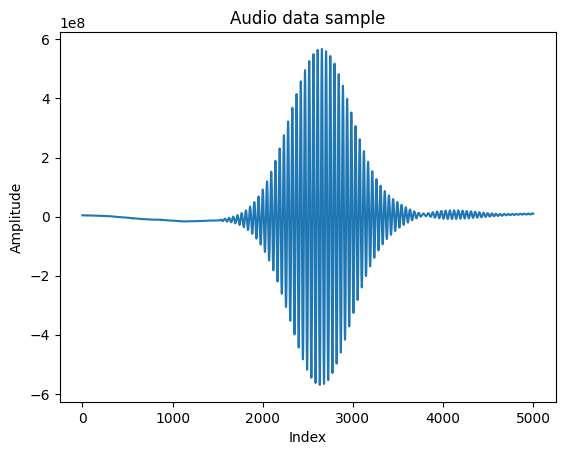

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


In [4]:
#Setting up audio state
from scipy.io import wavfile

sample_rate, audio = wavfile.read("Jies_Acoustic_Data_1.wav")

plt.plot(audio[84000:89000])
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.title("Audio data sample")
plt.show()

img=audio[84000:89000]
img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
img_padded /= np.linalg.norm(img_padded)
audiostate = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
audiostate.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
# Load in Accoustic Circuit
def arch_apply_layer(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        gate_count=gate_count+1
def arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits):
    qc=qtn.Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer(sorted_k_gates,qc,num_qubits)
    arch_apply_layer(sorted_z_gates,qc,num_qubits)
    arch_apply_layer(sorted_b_gates,qc,num_qubits)
    return qc
sorted_k_gates=[np.array([[ 0.58202826+0.03064421j,  0.2211523 +0.66589927j,
         0.31456239+0.01467208j, -0.08062462-0.24961722j],
       [ 0.21442015-0.15826631j, -0.38193016-0.07747488j,
        -0.01207216-0.77562583j,  0.34533318-0.2368683j ],
       [ 0.08815743+0.32977098j,  0.09571298+0.29393884j,
        -0.29172782-0.37350674j, -0.06823435+0.74742894j],
       [-0.60646143+0.32398103j,  0.4414201 +0.25570314j,
         0.12592156-0.24212686j,  0.34689456-0.26867738j]]), np.array([[ 0.44552844+0.15794513j,  0.66797301+0.5592994j ,
        -0.11283244-0.02905615j,  0.03183672+0.05445167j],
       [-0.09733357+0.855663j  ,  0.23246245-0.40912809j,
         0.07423724-0.03686386j, -0.09281805-0.14648249j],
       [ 0.12614157-0.04675024j, -0.08832296+0.07383197j,
        -0.14336369+0.10399472j,  0.22148849-0.94245711j],
       [ 0.04027883-0.12330888j,  0.0781551 +0.01453717j,
         0.6354779 -0.73780368j,  0.019408  -0.16819601j]]), np.array([[ 0.64828808+0.5747724j , -0.12442896-0.41081484j,
        -0.06888901-0.10599752j,  0.00205952-0.22163585j],
       [ 0.0997587 +0.07837263j,  0.07700988+0.20810604j,
         0.64933299+0.57312201j, -0.12503056-0.41101397j],
       [-0.07949422-0.06547905j, -0.4600854 -0.42522884j,
         0.45789497+0.12939045j,  0.41654416+0.4438201j ],
       [ 0.45274918-0.13295315j,  0.56972027+0.22232999j,
         0.08476216-0.01795405j,  0.58351822+0.2352219j ]]), np.array([[ 0.52407372+0.461487j  , -0.40031671+0.38672605j,
        -0.20296601+0.21451742j,  0.2229162 +0.25624484j],
       [ 0.2432249 +0.16987124j,  0.21224962-0.2653005j ,
         0.35801352-0.5997838j ,  0.45552873+0.31801012j],
       [-0.03384098+0.35613347j, -0.14360225-0.30104796j,
         0.42340664+0.3572732j ,  0.32604748-0.58953199j],
       [-0.15906532-0.52065713j, -0.67983397-0.0364627j ,
         0.33589182+0.07163898j,  0.20981771+0.27952047j]]), np.array([[ 0.3195201 +0.28623376j, -0.39021268+0.67612951j,
         0.29130818+0.25674555j,  0.11327077-0.20724645j],
       [ 0.35619821-0.1541608j , -0.1448835 -0.18206131j,
        -0.13391825+0.40844378j, -0.77596986-0.09126936j],
       [-0.59401613+0.12715196j,  0.00234348-0.11431195j,
         0.6021543 +0.03509899j, -0.31027391-0.39725667j],
       [-0.45769029+0.29467142j,  0.35182842+0.44675435j,
        -0.43332058+0.33596486j, -0.20974368+0.18890249j]]), np.array([[ 0.50748849-0.38992088j,  0.26423653-0.37016937j,
        -0.27974655+0.22028492j,  0.29301619-0.41343532j],
       [ 0.21295812+0.2976991j , -0.40519303-0.29927838j,
         0.09443477-0.62699161j, -0.06438628-0.45397483j],
       [-0.52754712+0.32413781j, -0.00941132-0.37106295j,
        -0.67810661+0.08969459j,  0.08652006-0.05910172j],
       [ 0.253007  +0.09517038j,  0.26500474-0.57567434j,
         0.04397303-0.03704988j, -0.55460073+0.46304785j]]), np.array([[ 0.8465369 +0.1490747j ,  0.11381032+0.4065244j ,
         0.1188296 +0.03126009j, -0.06330886-0.25264888j],
       [ 0.12141814-0.0432531j , -0.19565552-0.17316475j,
         0.8616023 -0.00372001j,  0.18176981+0.37377409j],
       [-0.010625  +0.32042399j,  0.72045441+0.10184213j,
        -0.07680818-0.17377331j,  0.23720832+0.52480926j],
       [-0.02840682-0.37542968j, -0.14094034+0.45191532j,
        -0.15965058+0.42537632j,  0.63258819+0.16599045j]]), np.array([[ 0.6879807 -0.15085243j, -0.37283286-0.26820696j,
         0.33201212-0.07792622j,  0.38242064+0.17446116j],
       [ 0.22139692+0.47721791j, -0.23807596+0.7458153j ,
         0.12477684+0.20328617j,  0.10738893-0.2046923j ],
       [-0.02372256-0.38704301j,  0.04009478-0.0397363j ,
         0.08806785+0.90358429j,  0.06914538-0.13208626j],
       [-0.18861644+0.20305504j,  0.39338576-0.13491159j,
         0.01759658-0.04765265j,  0.81504929-0.28870959j]]), np.array([[ 0.20146529-0.40427636j,  0.57271501+0.66513107j,
        -0.09169325+0.12521773j, -0.0271526 -0.02731558j],
       [ 0.22493316+0.1184158j , -0.00507774+0.05414656j,
         0.80426111+0.39957849j, -0.09271839+0.342534j  ],
       [-0.82288616+0.19381148j, -0.06260719+0.46273796j,
         0.1224518 -0.08029448j,  0.02590225+0.21245428j],
       [-0.11617348-0.05616341j, -0.08175297+0.04371399j,
         0.21382396+0.3197681j ,  0.68024952-0.60335992j]]), np.array([[ 0.87066998+0.1150999j , -0.27420068-0.37600907j,
         0.09424396+0.02108211j, -0.03612314-0.03854494j],
       [ 0.372813  +0.19573726j,  0.21562763+0.7651584j ,
        -0.173029  -0.11540316j, -0.1221138 -0.36409618j],
       [ 0.19144084-0.0476141j ,  0.34638822+0.15401582j,
         0.38760483-0.29324391j,  0.65628003+0.38787196j],
       [-0.08856471-0.06799111j,  0.0876067 -0.00937547j,
         0.82228486+0.18717588j, -0.12840687-0.50209077j]]), np.array([[ 0.09265075-0.09016941j,  0.50203184+0.85223331j,
        -0.04579392-0.04069792j, -0.03215189-0.01267246j],
       [ 0.07778813+0.54951414j,  0.10262224+0.03513331j,
         0.20297511+0.08275016j,  0.7909637 +0.08091651j],
       [-0.41503278-0.58944628j, -0.04123336+0.03158399j,
         0.49248551-0.30923895j,  0.36718933-0.06785595j],
       [-0.1517764 +0.36405129j,  0.07315172+0.04298646j,
         0.75285865+0.20792608j, -0.44757153-0.16395699j]]), np.array([[ 0.94288573-0.27707098j, -0.07145321-0.02650028j,
        -0.15852259-0.05485833j,  0.00544126+0.01489628j],
       [-0.03329412-0.07890731j,  0.30523914-0.93573229j,
        -0.01239679-0.05010488j, -0.0441048 +0.138888j  ],
       [-0.04695647-0.08672901j,  0.0741091 -0.02479653j,
         0.04555413-0.6330607j ,  0.64230814-0.41081063j],
       [ 0.12257869+0.04594511j,  0.03183247-0.13529964j,
         0.38746771+0.6451548j ,  0.2426427 -0.58164661j]])]
sorted_z_gates=[np.array([[ 7.03134478e-01+0.64204651j,  1.32967243e-01-0.17099836j,
         1.35690170e-01+0.02980882j, -8.90878621e-02-0.13863772j],
       [ 1.54638248e-01-0.18665489j,  7.95244426e-01+0.5456483j ,
         9.06082570e-04+0.05827191j,  8.24846307e-02-0.03001751j],
       [-8.03907783e-02-0.11601588j, -8.88605746e-02+0.06222374j,
         9.07885923e-01+0.34394578j,  2.24949069e-02-0.15889641j],
       [ 1.18723479e-01-0.02464785j, -5.83552520e-02-0.08809188j,
         3.86060998e-02-0.18236555j,  9.65796737e-01-0.08136794j]]), np.array([[ 0.64571428+0.49596465j, -0.45380149-0.33907793j,
        -0.06694162-0.08015101j,  0.04724597+0.0549996j ],
       [ 0.4955781 +0.27439294j,  0.71747993+0.38491003j,
        -0.05431832-0.0482405j , -0.07904742-0.06820239j],
       [ 0.10117342+0.02561433j, -0.07058747-0.01696308j,
         0.72663724+0.36736893j, -0.50884918-0.24889436j],
       [ 0.07238447+0.00716485j,  0.10395368+0.00897127j,
         0.53788306+0.17758718j,  0.77647313+0.24506405j]]), np.array([[ 0.64636693+0.63721595j,  0.03666502+0.18464219j,
         0.15823873-0.3293842j ,  0.07512451-0.03938812j],
       [-0.19001252-0.03081503j,  0.64599194+0.63867178j,
         0.00114168+0.07497111j,  0.16872555-0.32194436j],
       [-0.08004571+0.3581736j , -0.06430601+0.04382427j,
        -0.90366332+0.09417753j, -0.15828807-0.0933628j ],
       [-0.0257416 -0.061262j  , -0.07977603+0.35628033j,
         0.14020559-0.12534022j, -0.90711751+0.063675j  ]]), np.array([[ 0.65471375+0.65571412j, -0.05704243-0.06013354j,
         0.05952997-0.33061483j,  0.14617432+0.01738101j],
       [ 0.00359358+0.04573564j, -0.15514195+0.95233419j,
         0.15024435+0.05351004j,  0.18091655-0.09337244j],
       [ 0.33468649-0.11782398j,  0.03022321-0.10588509j,
         0.75758999+0.51223815j, -0.15635953+0.03462008j],
       [ 0.1146089 -0.01585878j,  0.12341588+0.18645136j,
        -0.15557113+0.03435739j, -0.28460644+0.91117182j]]), np.array([[ 0.48765382+0.80428082j, -0.02004694+0.18623798j,
        -0.03871273+0.0552293j , -0.25148666+0.1115579j ],
       [-0.06720493-0.14190248j, -0.43673553+0.8552704j ,
         0.06123371-0.11849076j,  0.11466872+0.14894048j],
       [-0.15239092+0.10160871j,  0.12887923+0.00218074j,
         0.82542422+0.41149955j,  0.11428394+0.29346247j],
       [-0.19945933-0.13168887j,  0.15957604-0.02467874j,
         0.00596335-0.35632686j, -0.64857446+0.60757489j]]), np.array([[-0.20310121+0.72763244j, -0.46759073+0.24399318j,
         0.03902037+0.11005302j, -0.1356478 +0.34509794j],
       [-0.16104273+0.00789092j,  0.31571895+0.2222955j ,
         0.28464787-0.72117529j, -0.43495194+0.18603181j],
       [-0.12050757+0.51657895j,  0.68663345-0.21409732j,
         0.10194473+0.32851939j, -0.14218333-0.25057363j],
       [ 0.24528904+0.24851823j, -0.21644769+0.09262687j,
        -0.41749531-0.30434763j, -0.26301599-0.69752091j]]), np.array([[ 0.59960737+0.58699756j,  0.52863945-0.12070687j,
         0.01438597-0.00941078j, -0.01492176+0.03683578j],
       [-0.53496912-0.08351615j,  0.55447857-0.62927262j,
         0.04676391-0.00283672j, -0.03238546-0.01260359j],
       [-0.00557339+0.03069273j, -0.01801741-0.02413408j,
         0.31915752+0.77555265j,  0.53806246+0.07256144j],
       [-0.02189967+0.03585054j,  0.03675377-0.01678535j,
        -0.45849335-0.28974123j,  0.74068471-0.39220222j]]), np.array([[ 0.77662637+6.11188819e-01j,  0.0218406 -2.16353155e-02j,
        -0.14257091+3.71626137e-02j,  0.00501998+2.49375782e-02j],
       [-0.0162492 -2.11654570e-02j,  0.86502625-4.82211327e-01j,
         0.04885749-8.62237496e-04j,  0.02443493+1.24518837e-01j],
       [ 0.02361563+1.47090131e-01j, -0.04319908+1.77398753e-03j,
         0.87237333+4.63234941e-01j,  0.01623505-7.21592420e-03j],
       [ 0.00559072+1.90586560e-02j,  0.12775119+8.18806839e-03j,
        -0.01529697+6.98846046e-03j,  0.37240375-9.18831164e-01j]]), np.array([[-0.09681078+0.83362289j, -0.0966908 +0.06137852j,
        -0.11812443+0.40895191j, -0.31612943-0.03809521j],
       [-0.10657436-0.17385175j,  0.78609145-0.12908755j,
        -0.20798033+0.30186568j, -0.26471895+0.34548415j],
       [ 0.30293512-0.31677137j, -0.40939011-0.12625996j,
        -0.62107907+0.48588119j,  0.02822391+0.04156967j],
       [ 0.19994696-0.14840973j,  0.13676433-0.38734208j,
         0.20579641+0.14231776j, -0.37154238-0.75406045j]]), np.array([[ 0.41154583+0.30545641j, -0.57722946+0.14494536j,
        -0.61270542+0.05550446j, -0.02528286+0.06320997j],
       [-0.24068861+0.49135409j,  0.32555458+0.31687055j,
        -0.18830948+0.02954589j,  0.66026907-0.14818492j],
       [-0.12810287+0.12477796j, -0.64350872-0.05277341j,
         0.55380291+0.2822562j ,  0.28309016-0.29090436j],
       [ 0.52090793-0.36693543j, -0.02700549-0.14760238j,
         0.09897426-0.43475944j,  0.60774319+0.05774166j]]), np.array([[ 0.06857136+0.26545743j,  0.4617385 +0.74884729j,
         0.29742017+0.15911151j, -0.19018004+0.03019813j],
       [-0.42767494-0.824323j  ,  0.22178229+0.26306455j,
        -0.08670321-0.06482756j,  0.08332348+0.02307675j],
       [-0.00076721-0.09914634j, -0.03850987-0.13550184j,
         0.62820086+0.46576225j,  0.59005693-0.10289649j],
       [-0.17079222-0.15302122j, -0.2067164 -0.21227227j,
         0.4909668 +0.14793756j, -0.65673252+0.40668393j]]), np.array([[ 0.93679913+0.02594862j,  0.13991495-0.28770167j,
         0.10117862+0.0920605j , -0.01879686+0.01788962j],
       [ 0.30961345-0.04226362j, -0.28174109+0.8950109j ,
         0.04800702+0.06610847j,  0.05148477-0.11227224j],
       [-0.10830616+0.09081878j, -0.06490451+0.01058552j,
         0.90338618+0.10824496j, -0.31561365+0.2196851j ],
       [-0.04060171+0.04960425j,  0.02598153-0.11058619j,
         0.35881805-0.1343086j ,  0.44351932-0.79967993j]])]
sorted_b_gates=[np.array([[ 0.79470034+0.46651016j, -0.06183633-0.02563694j,
         0.0405321 +0.03077763j,  0.35519194-0.13261686j],
       [ 0.04163815+0.02565811j,  0.9876019 +0.07080013j,
        -0.01868977+0.10151397j,  0.01365924-0.07997988j],
       [-0.01215399+0.00795198j, -0.05136915+0.09569919j,
         0.77172121+0.6149146j , -0.11660769+0.02685125j],
       [-0.38320895-0.03697997j, -0.03971645-0.04212265j,
         0.11435339+0.00228377j,  0.63863364-0.65383242j]]), np.array([[ 0.73014302+0.67053803j,  0.06824339+0.09991291j,
        -0.00315423-0.03241934j, -0.02737492-0.02863255j],
       [-0.06832139-0.10241291j,  0.33838657+0.92840835j,
        -0.05289589-0.07098943j,  0.01243432-0.02010401j],
       [ 0.02130573+0.01828214j, -0.02244896+0.0892792j ,
        -0.01508716+0.98722821j, -0.01262397+0.12542161j],
       [-0.01502122+0.03316467j,  0.01569681+0.01384212j,
         0.03143621-0.12355636j, -0.33237175+0.93354758j]]), np.array([[ 0.73591107+0.55126318j,  0.16441159+0.31931058j,
        -0.0224752 -0.14543077j,  0.01021258-0.06159422j],
       [ 0.24565266-0.26200369j, -0.84558714+0.34376809j,
        -0.05742093+0.0471137j ,  0.17163718+0.05327793j],
       [ 0.019668  +0.14221932j,  0.01602544+0.0780073j ,
        -0.45545565+0.78281084j, -0.32364484+0.21924013j],
       [ 0.06944699-0.01079778j, -0.16376764-0.06821787j,
         0.33146163+0.20670853j, -0.49926612-0.74948323j]]), np.array([[ 7.17991637e-01+0.67342796j, -5.34383911e-03-0.05433924j,
         2.69559704e-02-0.16432942j, -1.35804577e-02+0.00928795j],
       [ 5.30820938e-02-0.01328688j,  8.67896360e-01+0.46394857j,
        -8.94403912e-03-0.01354531j, -1.84544123e-02-0.16706091j],
       [ 9.26703685e-02-0.13926986j, -3.23254858e-03-0.00330969j,
         9.84563062e-01-0.00185388j, -3.85591669e-02-0.03376444j],
       [ 6.17368744e-04-0.00206549j,  5.46872610e-02-0.15973173j,
         2.73890182e-02-0.04344799j,  9.48825067e-01-0.26188459j]]), np.array([[ 0.56507372+0.30746262j, -0.11876625-0.12696098j,
        -0.38800081+0.20779634j,  0.40301607+0.44697653j],
       [ 0.17050499-0.21191571j,  0.19827398+0.80737897j,
        -0.20270783-0.40095894j,  0.05497155+0.17310693j],
       [-0.53087812+0.34505451j, -0.03796253+0.20040768j,
         0.24217185-0.02061659j,  0.70283543+0.06671974j],
       [-0.07711519-0.32455703j, -0.25601526-0.41406994j,
        -0.3206664 -0.66522051j,  0.30681165-0.11063275j]]), np.array([[ 0.22004077+0.01409825j, -0.2863934 +0.24745917j,
        -0.0682152 -0.17868422j, -0.75287943+0.45245693j],
       [-0.12101337-0.00697645j, -0.10178502+0.91398206j,
         0.1196823 +0.08706739j,  0.07034555-0.33575381j],
       [ 0.24391325-0.13520864j, -0.04595563+0.00539721j,
         0.66366276-0.65539256j,  0.21681634+0.05556001j],
       [ 0.57950374-0.72325014j,  0.09281615-0.01623243j,
        -0.04747952+0.26319591j, -0.08247475-0.23211602j]]), np.array([[ 0.5544758 +0.56143093j,  0.47486683+0.36179487j,
         0.08106661+0.04452605j,  0.08334508+0.07387222j],
       [-0.58944759+0.13023794j,  0.7443091 -0.27420421j,
         0.03809042-0.06380702j, -0.0243691 +0.01701644j],
       [-0.04494578-0.08505727j, -0.01611423-0.10867334j,
         0.30125342+0.72871738j,  0.29054326+0.52199382j],
       [-0.05799434-0.01798102j,  0.01990613+0.04422852j,
        -0.59452457-0.10335045j,  0.79213566+0.04838633j]]), np.array([[ 0.36087993-0.01080293j,  0.91557851-0.03273781j,
         0.07859434+0.05716312j, -0.12966675+0.06352207j],
       [ 0.87235786+0.28739604j, -0.32927208-0.09928422j,
        -0.08720405-0.17208417j, -0.01103217+0.02790335j],
       [-0.02057557+0.08272297j, -0.09191175+0.04741377j,
        -0.08672642+0.38223717j, -0.17125989+0.89391333j],
       [-0.07868024-0.1121928j ,  0.01114537+0.17761397j,
         0.35322866-0.82154768j, -0.14878834+0.35735446j]]), np.array([[ 0.14617241+0.49153034j, -0.43146663-0.40556759j,
        -0.21456778-0.13877135j,  0.47072835+0.31543785j],
       [ 0.07798231-0.15998614j,  0.45634742+0.42076338j,
        -0.19969481-0.45344271j,  0.49354915+0.30651154j],
       [ 0.74266325-0.26688234j,  0.24376679-0.31700554j,
        -0.09025163+0.21777477j, -0.20886591+0.34367742j],
       [-0.25358341+0.13518623j,  0.05692467+0.31764998j,
        -0.26052666+0.75217652j,  0.08870556+0.41444647j]]), np.array([[ 0.51030462+5.61704849e-01j,  0.16617521-1.72770756e-01j,
        -0.11466276+3.50835031e-01j, -0.46919987+1.01151586e-01j],
       [ 0.06206008-4.92001405e-04j,  0.11666512+8.83591936e-01j,
         0.35285731+2.74771730e-02j, -0.26809279+6.83068673e-02j],
       [-0.17214592-1.90664016e-01j,  0.32007603+9.58411087e-02j,
        -0.13546116+8.38196024e-01j,  0.31779335-2.15387760e-02j],
       [-0.55769994-2.07867653e-01j, -0.0759138 -1.75480827e-01j,
        -0.00643185+1.32439756e-01j, -0.61850013+4.57254109e-01j]]), np.array([[ 0.36154847+0.51179882j, -0.50070492-0.09801636j,
         0.22954133+0.47852417j,  0.24568187+0.07069554j],
       [-0.26625981+0.35218558j,  0.08618814+0.72588701j,
        -0.25017231+0.26089812j, -0.04406011-0.37166568j],
       [ 0.19863699-0.47962333j, -0.04338617-0.2596613j ,
        -0.30682601+0.53710677j, -0.09528713-0.5191271j ],
       [ 0.36943096+0.08025755j, -0.34575688+0.12842452j,
        -0.41491508-0.18135872j, -0.68531738+0.21525194j]]), np.array([[ 8.76599706e-01+0.24382701j, -3.78902308e-01+0.16072861j,
        -1.28022078e-02+0.03250201j,  3.18294542e-02+0.02207508j],
       [-4.11956822e-01-0.0070284j , -7.18755732e-01+0.55739191j,
        -4.59355870e-02-0.01661756j,  2.29264857e-02+0.00589798j],
       [-2.86962958e-02-0.02468589j, -2.02857661e-02-0.04027613j,
        -3.01108954e-01+0.94357038j, -7.34377502e-02-0.10074071j],
       [ 7.03164803e-04-0.03049853j,  2.35426873e-02+0.02675575j,
        -1.19636329e-01+0.03299989j, -3.62256667e-01+0.92258738j]])]
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)

In [5]:
#ALL FUNCIONS ME AND JOSH MADE FOR TAU MINIMISER
def tau_ipr_analyse(state_vector):
    ipr = np.sum(np.abs(state_vector)**4)
    tau=compute_tau_sparse(state_vector)
    return (ipr,tau)
def ipr_loss_function(
    tau_layer: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,  # matches TNOptimizer loss_constants
    eps: float = 1e-12
) -> torch.Tensor:
    """
    Computes the Inverse Participation Ratio (IPR) of a tau_layer
    applied to a prepared MPS state.

    Args:
        tau_layer: SU(2) tensor network layer to apply (trainable).
        init_tn: Prepared MPS state (fixed, passed via TNOptimizer).
        eps: Small number for numerical stability during normalization.

    Returns:
        ipr_loss: Scalar torch.Tensor representing the IPR.
                  Lower values -> amplitudes more uniform.
    """

    # --- Copy inputs to avoid modifying originals ---
    tau_layer = tau_layer.copy()
    init_tn = init_tn.copy()

    # --- Ensure tensors are torch complex and differentiable ---
    #init_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    #tau_layer.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: tensors are guaranteed to be complex and differentiable when passed from ipr_layer_optimise.

    # --- Apply tau_layer to the state ---
    new_state = apply_single_tau_layer(circ_tn=tau_layer, mps=init_tn)
    #Seems fine -- concatenates single-qubit gate layer to MPS. Concatenated state will inherit torch backend.

    # --- Contract full TN to get state vector ---
    vec = new_state.contract(all).data.to_dense().flatten()
    #Not sure about this one -- computing to dense SV?

    # --- Compute probabilities and normalize ---
    probs = torch.abs(vec)**2
    probs = probs / (probs.sum() + eps)  # ensure normalization

    # --- Compute IPR: sum_i p_i^2 ---
    ipr_loss = (probs**2).sum()

    return ipr_loss

def su2_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(2) parametrised tn, initialised with zero for all parameters and indexed to match mps. This is normlaised (at least when hitting zer ostate it gives same sate) """

    qc = qtn.Circuit(n)
    for idx in range(n):
        theta = np.random.uniform(-eps, eps)
        phi   = np.random.uniform(-eps, eps)
        lam   = np.random.uniform(-eps, eps)
        #for some reason it breaks if you have it on only idx? so werid idk what happens here
        qc.apply_gate("u3", *(theta, phi, lam), idx, idx+1,tags=["SU2"], parametrize=True)
    layer = qc.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()
    mapping = {}

    for i in range(13):
        mapping[f'k{i+1}'] = f'k{i}'
        mapping[f'b{i+1}'] = f'b{i}'

    to_opt.reindex_(mapping)
    
    return to_opt

def ipr_layer_optimise(
    init_mps: qtn.TensorNetwork,
    loss=ipr_loss_function,  # default: ipr_loss_function
    verbose: bool = False,
    gauge_iteratively: bool = False
) -> qtn.TensorNetwork:
    """
    Optimises a single SU(2) layer to minimise Inverse Participation Ratio (IPR) 
    when applied to init_mps.

    Args:
        init_mps: Current MPS object representing the state to act on (fixed).
        loss: Loss function. Default is ipr_loss_function.
        verbose: If True, prints optimisation progress.
        gauge_iteratively: If True, applies TN gauging for numerical stability.

    Returns:
        best_layer_tn: The optimised SU(2) layer as a TensorNetwork.
    """

    # --- 1. Copy the input MPS to avoid modifying the original ---
    init_mps = init_mps.copy()

    # --- 2. Build a SU(2) circuit layer (identity initialisation) ---
    to_opt = su2_circ_layer(init_mps.L, 1e-2)  
    #Check -- looks good!
    
    # Convert MPS to complex128
    init_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    #to_opt.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: applying compelx128 to torch parameterised tensors (PTensors) makes parameters complex. to_opt already has a torch backend from su2_circ_layer func.

    #print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')
    #Removed: only compute loss using torch.no_grad() for verbose prints (see below)

    if verbose:
        with torch.no_grad():
            print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')

    # --- 4. Setup bookkeeping to store the best parameters ---
    _best = {
        "val": loss(to_opt, init_tn=init_mps),      # initial loss
        "params": to_opt.get_params(),              # store initial parameters as default
    }

    # --- 5. Function to update best TN seen so far ---
    def get_best(psi):
        """Store parameters of psi if it improves loss."""
        with torch.no_grad():
            val = loss(psi, init_tn=init_mps)
        if val < _best["val"]:
            tn_copy = psi.copy()
            tn_copy.apply_to_arrays(to_numpy)
            _best["params"] = tn_copy.get_params()
            _best["val"] = val
        return psi

    # --- 6. Norm function for TNOptimizer ---
    def get_best_fn(psi):
        """Called during optimization to store best params and optionally gauge."""
        with torch.no_grad():
            _ = get_best(psi.copy())  # bookkeeping on a separate copy
            if gauge_iteratively:
                psi.gauge_all(method='simple', inplace=True)  # stabilise TN contractions
        return psi

    if verbose:
        print('Starting optimisation...')

    # --- 7. Initialise TNOptimizer for the SU(2) layer ---
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss, #Most likely cause of error.
        norm_fn=get_best_fn,
        loss_constants={'init_tn': init_mps},  # pass the fixed state
        tags=['SU2'],  # changed from SU4
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    # --- 8. Run optimisation using basinhopping ---
    opt_layer_tn = tnopt.optimize_basinhopping(
        n=400, tol=1e-16, lr=2, nhop=20
    )
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    # --- 9. Verbose outputs for tracking ---
    if verbose:
        with torch.no_grad():
            print(f'Final IPR loss = {loss(opt_layer_tn, init_tn=init_mps)}')

    # --- 10. Restore best parameters seen during optimization ---
    with torch.no_grad():
        best_layer_tn = opt_layer_tn.copy()
        # safe: _best["params"] is guaranteed not None
        best_layer_tn.set_params(_best["params"])
        best_copy = best_layer_tn.copy()
        best_copy.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

        if verbose:
            print(f'Best IPR loss recorded = {_best["val"]}')
            print(f'After updating, final IPR loss = {loss(best_copy, init_tn=init_mps)}')

    return best_layer_tn
def apply_single_tau_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 1-qubit unitaries to evolve an MPS. mps is the mps that represents the state prep final circuit (ausiostate mps, and constant through this whole process). circ_tn is the tau layer.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #does this conjugate the circuit? NO! | just connects indiices
    new = circ_tn | mps

    #Maybe we dont need all of this, Ill try and go without because my tau function needs dense state vector.
    '''shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))'''


    return new
    #return ensure_mps_shape_lrp(new)
def tau_tn_to_circ(best_tau_layer,circuit,num_qubits,verbose:bool= False,calc_first_tau:bool=True):
    '''Appends the best tau layer onto the end of the circuit and will print the new tau value'''
    if verbose:
        print("Lowest Possible IPR:",2**(-n))
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State before flattening layer")
        plt.show()
        if calc_first_tau==False:
            print("not computing tau before")
        else:
            tau=compute_tau_sparse(circuit.psi.to_dense())
            print("Tau before flattening layer is:",tau)
    for idx in range(num_qubits):
        circuit.apply_gate_raw(best_tau_layer.tensors[idx].data,[idx])
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State after flattening layer")
        plt.show()
    tau=compute_tau_sparse(circuit.psi.to_dense())
    print("Tau after flattening layer is:",tau)
    return circuit

# Random SU2 Gate Method

TAU for trial 0 :  22.57247987137325
TAU for trial 1 :  28.570424568665636
TAU for trial 2 :  34.03311324959635
TAU for trial 3 :  45.195579793045376
TAU for trial 4 :  34.923365788088105
TAU for trial 5 :  44.982149609229545
TAU for trial 6 :  36.74348450716945
TAU for trial 7 :  79.48806198975355
TAU for trial 8 :  35.17281834476363
TAU for trial 9 :  32.193212967437105
TAU for trial 10 :  39.06835032413172
TAU for trial 11 :  30.983503141759748
TAU for trial 12 :  26.634949395559143
TAU for trial 13 :  35.282962006802805
TAU for trial 14 :  34.27459704323465
TAU for trial 15 :  29.23562371190398
TAU for trial 16 :  63.650827647146066
TAU for trial 17 :  36.72250835163693
TAU for trial 18 :  31.637361113745452
TAU for trial 19 :  29.14740337059368
TAU for trial 20 :  45.535438060547875
TAU for trial 21 :  36.91389090181887
TAU for trial 22 :  36.02719882158035
TAU for trial 23 :  42.241261860678186
TAU for trial 24 :  33.15474878484264
TAU for trial 25 :  32.077809353827995
TAU for t

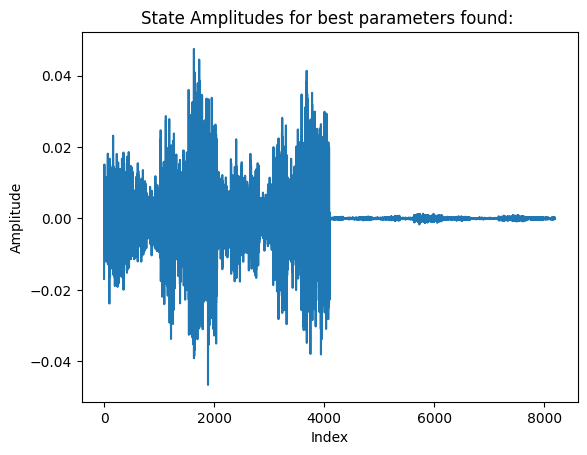

(<Figure size 816.667x216.667 with 1 Axes>, <Axes: >)

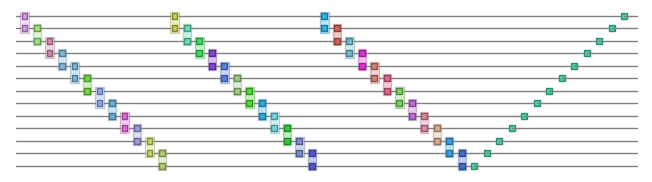

In [319]:
#Flattening random layer of su2
#make a list for storing trial data each will be a (fideility,parameters) object as a tuple in a list.
trial_data=[]

for trial in range(30):
    real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
    #Smoothing stage
    #Making a random su2 layer and seeing how it helps tau.
    n = 13  # number of qubits
    # Each tuple is (theta, phi, lambda)
    params_list = [(np.random.uniform(0, np.pi),
                    np.random.uniform(0, 2*np.pi),
                    np.random.uniform(0, 2*np.pi)) for _ in range(n)]
    for ind in range(13):
        real_accoustic_circuit.apply_gate("u3",*params_list[ind],ind)
    tau=compute_tau_sparse(real_accoustic_circuit.psi.to_dense())
    trial_data.append((tau,params_list))
    print("TAU for trial", trial, ": ",tau)

#Make the best circuit
best_layer = min(trial_data, key=lambda x: x[0])
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
for ind in range(13):
        real_accoustic_circuit.apply_gate("u3",*best_layer[1][ind],ind)

print("Best tau is",best_layer[0])
plt.plot(real_accoustic_circuit.psi.to_dense())
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.title("State Amplitudes for best parameters found: ")
plt.show()
real_accoustic_circuit.draw()

# 1 qubit MPS reverse construction.

This is a decent first attempt at an analytic flattener, but it doesnt actually work that well. Keep in mind randomly guessing only 400 times got me a 23 tau wheras this gav ea 42 tau. seems to suggest that optimisation might be the move, although probably best to do it over a different loss function not a tau.

In [12]:
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
audiostate = qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense())/qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense()).norm()

In [15]:
audiostate.compress(max_bond=1)

In [30]:
audiostate[2].data[0]


array([[-0.99081641+0.j        ],
       [-0.1352129 +0.00056103j]])

In [31]:
def make_su2_from_col(col):
    """
    Given a 2x1 complex column vector `col` (normalized),
    returns a 2x2 unitary U with `col` as the first column.
    """
    col = np.array(col, dtype=complex).reshape(2)
    
    # Ensure normalized
    col = col / np.linalg.norm(col)
    
    # Find an orthogonal vector
    # For 2x2, just swap and add a phase to make it orthogonal
    orth = np.array([-np.conj(col[1]), np.conj(col[0])])
    
    # Assemble unitary
    U = np.column_stack((col, orth))
    
    # Verify unitary
    if not np.allclose(U.conj().T @ U, np.eye(2)):
        raise ValueError("Generated matrix is not unitary")
    
    return U


In [33]:
U=make_su2_from_col(audiostate[2].data[0])

In [36]:
U

array([[-0.99081641+0.j        ,  0.1352129 +0.00056103j],
       [-0.1352129 +0.00056103j, -0.99081641-0.j        ]])

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


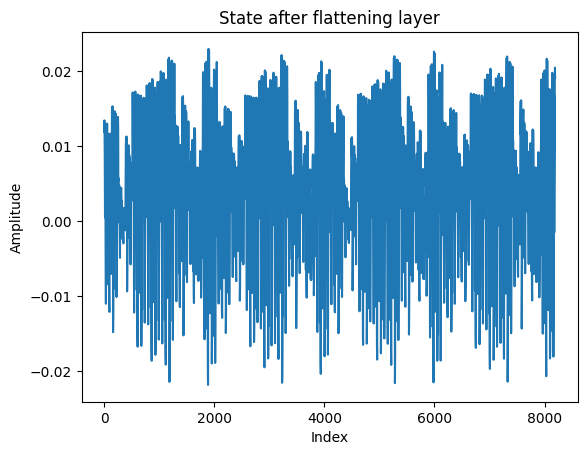

Tau is: 40.49539823689708


(<Figure size 816.667x216.667 with 1 Axes>, <Axes: >)

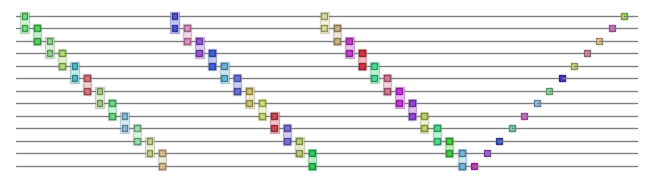

In [ ]:
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
def add_flattening_layer(circuit):
    '''Adds a layer of single qubit gates based on the chi1 mps approximation of the current circuit output. 
    Added feature is the flatten=True which turns on the hadamards. when hadamards are turned off it pushes the state into the terrible tau spike around the zero state'''
    circ_output_mps=qtn.MatrixProductState.from_dense(circuit.psi.to_dense())/qtn.MatrixProductState.from_dense(circuit.psi.to_dense()).norm()
    #Make sure that mps is normalised so that unitaries can be constructed from it
    circ_output_mps.compress(max_bond=1)
    circ_output_mps.left_canonize()
    circ_output_mps.normalize()
    for idx in range(13):
        U=make_su2_from_col(circ_output_mps[idx].data.flatten())
        #From construction I think that conj transpose happens to be unecessary
        h=np.array([[1/np.sqrt(2),1/np.sqrt(2)],[1/np.sqrt(2),-1/np.sqrt(2)]])
        #circuit.apply_gate("H",idx)
        circuit.apply_gate_raw(h@U.conj().T,[idx])
        
add_flattening_layer(real_accoustic_circuit)

plt.plot(real_accoustic_circuit.psi.to_dense())
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.title("State after flattening layer")
plt.show()
tau=compute_tau_sparse(real_accoustic_circuit.psi.to_dense())
print("Tau is:",tau)
real_accoustic_circuit.draw()

This is interesting, it seems that this kind of construction doesnt actually help as much as I hoped. It's still decent but reaslitically any kind of randomly generated single qubit layer will do this. What is interesting is that without the hadamards we get mixing times of 4000 (try this above)

# IPR Optimiser layer (su2)

## Development of IPR optimiser. (careful using this as there is dodgy functions here, use the one in the next section)

lets not get in a mess, one bit at a time. lets get the addition of the tau layer onto the current mps of the state working.

In [227]:

to_opt= su2_circ_layer(13,1e-3)#intitialise su2 circ at identity (zero parameters)
to_opt


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


TensorNetworkGenOperator(tensors=13, indices=26)

Above we have made sure indicies are labeled counting from 0 to match mps convention

In [135]:
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
audiostate = qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense())/qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense()).norm()

In [ ]:
def tau_tn_to_circ(best_tau_layer,circuit,num_qubits,verbose:bool= False):
    '''Appends the best tau layer onto the end of the circuit and will print the new tau value'''
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State before flattening layer")
        plt.show()
        tau=compute_tau_sparse(circuit.psi.to_dense())
        print("Tau before flattening layer is:",tau)
    for idx in range(num_qubits):
        circuit.apply_gate_raw(best_tau_layer.tensors[idx],[idx])
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State after flattening layer")
        plt.show()
    tau=compute_tau_sparse(circuit.psi.to_dense())
    print("Tau after flattening layer is:",tau)
    circuit.draw()
    return circuit

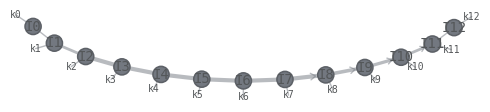

In [136]:
audiostate.draw()

In [138]:
to_opt

TensorNetworkGenOperator(tensors=13, indices=26)

In [145]:
mps = to_opt.copy() 
circ_tn = audiostate.copy()

new = circ_tn | mps

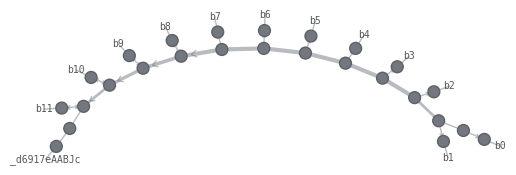

In [146]:
new.draw()

In [160]:
new.apply_to_arrays(
    lambda x: torch.as_tensor(x, dtype=torch.complex128)
)
new.contract(all).data.to_dense().flatten()

tensor([5.6954e-05-2.7958e-04j, 3.6019e-05-2.8065e-04j, 1.4505e-05-2.7659e-04j,
         ..., 2.0040e-05+3.3933e-06j, 1.7282e-05+9.5108e-06j,
        1.4211e-05+1.5447e-05j], dtype=torch.complex128)

okay make the tau value generator. I will use ipr (the inverse partition ratio) as it is far easier to compute than the actual tau. this can be changed later but due to the whole gradient follwing stuff its best to start simple.

In [271]:

init_mps = audiostate.copy()

# --- 2. Build a SU(2) circuit layer (identity initialisation) ---
to_opt = su2_circ_layer(init_mps.L, 10)  # small init parameters


#initial loss function
print(f'Initial IPR loss = {ipr_loss_function(to_opt, init_tn=init_mps)}')

Initial IPR loss = 0.0008075369594258876


C:\Users\archi\AppData\Local\Temp\ipykernel_13148\3320537472.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  tau_layer.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))


In [261]:
# --- 1. Build zero state MPS ---
n = 13  # number of qubits
zero_state = qtn.MPS_computational_state('0'*n)  # |00..0>
zero_state.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
zero_state.normalize()  # ensure norm=1

tensor(1.+0.j, dtype=torch.complex128)

In [253]:
new=apply_single_tau_layer(to_opt,zero_state)
new.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
print(np.linalg.norm(new.contract(all).data.flatten()))
print(new.contract(all).data.flatten())

0.9999999999999996
tensor([ 1.0000e+00+0.0000e+00j, -5.1860e-06-4.4700e-09j,
         4.0724e-04+1.9564e-07j,  ...,
         1.4871e-47+7.1383e-51j, -1.1678e-45-1.1500e-49j,
         6.0560e-51+5.8163e-54j], dtype=torch.complex128)


okay so the tau layer seems to work better and is now noramlised.

In [243]:
def compute_ipr_np(vec: np.ndarray, normalize=True) -> float:
    """
    Compute the Inverse Participation Ratio (IPR) of a state vector using NumPy.

    Args:
        vec: 1D complex or real NumPy array of shape (2^L,)
        normalize: If True, normalize the vector before computing IPR

    Returns:
        ipr: float scalar representing the IPR
    """
    if normalize:
        vec = vec / (np.linalg.norm(vec) + 1e-12)  # avoid division by zero

    probs = np.abs(vec) ** 2
    ipr = np.sum(probs ** 2)
    return ipr
print(compute_ipr_np(audiostate.to_dense()))
print(compute_ipr_np(audiostate.contract(all).data.flatten()))

0.0017205351045294786
0.0017205351045294786


hm i think this is working, lets push on and check.

In [288]:
ipr_layer_optimise(init_mps=audiostate,verbose=True)

C:\Users\archi\AppData\Local\Temp\ipykernel_13148\4227911287.py:31: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  to_opt.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
C:\Users\archi\AppData\Local\Temp\ipykernel_13148\3320537472.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  tau_layer.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))


Initial IPR loss = 0.0017212117112391885
Initial IPR loss = 0.0017212117112391885
Starting optimisation...


+0.003300327008 [best: +0.001714964821] :   0%|          | 3/800 [00:00<00:46, 17.03it/s]


Final IPR loss = 0.0017149648212357446
Best IPR loss recorded = 0.0017149648212357446
After updating, final IPR loss = 0.0017149648212357446


TensorNetworkGenOperator(tensors=13, indices=26)

In [ ]:
#ALL FUNCIONS ME AND JOSH MADE FOR TAU MINIMISER
def ipr_loss_function(
    tau_layer: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,  # matches TNOptimizer loss_constants
    eps: float = 1e-12
) -> torch.Tensor:
    """
    Computes the Inverse Participation Ratio (IPR) of a tau_layer
    applied to a prepared MPS state.

    Args:
        tau_layer: SU(2) tensor network layer to apply (trainable).
        init_tn: Prepared MPS state (fixed, passed via TNOptimizer).
        eps: Small number for numerical stability during normalization.

    Returns:
        ipr_loss: Scalar torch.Tensor representing the IPR.
                  Lower values -> amplitudes more uniform.
    """

    # --- Copy inputs to avoid modifying originals ---
    tau_layer = tau_layer.copy()
    init_tn = init_tn.copy()

    # --- Ensure tensors are torch complex and differentiable ---
    #init_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    #tau_layer.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: tensors are guaranteed to be complex and differentiable when passed from ipr_layer_optimise.

    # --- Apply tau_layer to the state ---
    new_state = apply_single_tau_layer(circ_tn=tau_layer, mps=init_tn)
    #Seems fine -- concatenates single-qubit gate layer to MPS. Concatenated state will inherit torch backend.

    # --- Contract full TN to get state vector ---
    vec = new_state.contract(all).data.to_dense().flatten()
    #Not sure about this one -- computing to dense SV?

    # --- Compute probabilities and normalize ---
    probs = torch.abs(vec)**2
    probs = probs / (probs.sum() + eps)  # ensure normalization

    # --- Compute IPR: sum_i p_i^2 ---
    ipr_loss = (probs**2).sum()

    return ipr_loss

def su2_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(2) parametrised tn, initialised with zero for all parameters and indexed to match mps. This is normlaised (at least when hitting zer ostate it gives same sate) """

    qc = qtn.Circuit(n)
    for idx in range(n):
        theta = np.random.uniform(-eps, eps)
        phi   = np.random.uniform(-eps, eps)
        lam   = np.random.uniform(-eps, eps)
        qc.apply_gate("u3", *(theta, phi, lam), idx, idx+1, tags=["SU2"], parametrize=True)
    layer = qc.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()
    mapping = {}

    for i in range(13):
        mapping[f'k{i+1}'] = f'k{i}'
        mapping[f'b{i+1}'] = f'b{i}'

    to_opt.reindex_(mapping)
    
    return to_opt

def ipr_layer_optimise(
    init_mps: qtn.TensorNetwork,
    loss=ipr_loss_function,  # default: ipr_loss_function
    verbose: bool = False,
    gauge_iteratively: bool = False
) -> qtn.TensorNetwork:
    """
    Optimises a single SU(2) layer to minimise Inverse Participation Ratio (IPR) 
    when applied to init_mps.

    Args:
        init_mps: Current MPS object representing the state to act on (fixed).
        loss: Loss function. Default is ipr_loss_function.
        verbose: If True, prints optimisation progress.
        gauge_iteratively: If True, applies TN gauging for numerical stability.

    Returns:
        best_layer_tn: The optimised SU(2) layer as a TensorNetwork.
    """

    # --- 1. Copy the input MPS to avoid modifying the original ---
    init_mps = init_mps.copy()

    # --- 2. Build a SU(2) circuit layer (identity initialisation) ---
    to_opt = su2_circ_layer(init_mps.L, 1e-2)  
    #Check -- looks good!
    
    # Convert MPS to complex128
    init_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    #to_opt.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: applying compelx128 to torch parameterised tensors (PTensors) makes parameters complex. to_opt already has a torch backend from su2_circ_layer func.

    #print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')
    #Removed: only compute loss using torch.no_grad() for verbose prints (see below)

    if verbose:
        with torch.no_grad():
            print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')

    # --- 4. Setup bookkeeping to store the best parameters ---
    _best = {
        "val": loss(to_opt, init_tn=init_mps),      # initial loss
        "params": to_opt.get_params(),              # store initial parameters as default
    }

    # --- 5. Function to update best TN seen so far ---
    def get_best(psi):
        """Store parameters of psi if it improves loss."""
        with torch.no_grad():
            val = loss(psi, init_tn=init_mps)
        if val < _best["val"]:
            tn_copy = psi.copy()
            tn_copy.apply_to_arrays(to_numpy)
            _best["params"] = tn_copy.get_params()
            _best["val"] = val
        return psi

    # --- 6. Norm function for TNOptimizer ---
    def get_best_fn(psi):
        """Called during optimization to store best params and optionally gauge."""
        with torch.no_grad():
            _ = get_best(psi.copy())  # bookkeeping on a separate copy
            if gauge_iteratively:
                psi.gauge_all(method='simple', inplace=True)  # stabilise TN contractions
        return psi

    if verbose:
        print('Starting optimisation...')

    # --- 7. Initialise TNOptimizer for the SU(2) layer ---
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss, #Most likely cause of error.
        norm_fn=get_best_fn,
        loss_constants={'init_tn': init_mps},  # pass the fixed state
        tags=['SU2'],  # changed from SU4
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    # --- 8. Run optimisation using basinhopping ---
    opt_layer_tn = tnopt.optimize_basinhopping(
        n=400, tol=1e-16, lr=2, nhop=20
    )
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    # --- 9. Verbose outputs for tracking ---
    if verbose:
        with torch.no_grad():
            print(f'Final IPR loss = {loss(opt_layer_tn, init_tn=init_mps)}')

    # --- 10. Restore best parameters seen during optimization ---
    with torch.no_grad():
        best_layer_tn = opt_layer_tn.copy()
        # safe: _best["params"] is guaranteed not None
        best_layer_tn.set_params(_best["params"])
        best_copy = best_layer_tn.copy()
        best_copy.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

        if verbose:
            print(f'Best IPR loss recorded = {_best["val"]}')
            print(f'After updating, final IPR loss = {loss(best_copy, init_tn=init_mps)}')

    return best_layer_tn
def apply_single_tau_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 1-qubit unitaries to evolve an MPS. mps is the mps that represents the state prep final circuit (ausiostate mps, and constant through this whole process). circ_tn is the tau layer.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #does this conjugate the circuit?
    new = circ_tn | mps

    #Maybe we dont need all of this, Ill try and go without because my tau function needs dense state vector.
    '''shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))'''


    return new
    #return ensure_mps_shape_lrp(new)

In [17]:
best_tau_layer=ipr_layer_optimise(init_mps=audiostate,verbose=True)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Initial IPR loss = 0.0017081287653011059
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000134465729 [best: +0.000133127067] :   2%|▏         | 123/8000 [00:02<03:09, 41.64it/s]


Final IPR loss = 0.00013312706717295456
Best IPR loss recorded = 0.00013312706717295462
After updating, final IPR loss = 0.00013312706717295456


In [16]:
def tau_tn_to_circ(best_tau_layer,circuit,num_qubits,verbose:bool= False):
    '''Appends the best tau layer onto the end of the circuit and will print the new tau value'''
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State before flattening layer")
        plt.show()
        tau=compute_tau_sparse(circuit.psi.to_dense())
        print("Tau before flattening layer is:",tau)
    for idx in range(num_qubits):
        circuit.apply_gate_raw(best_tau_layer.tensors[idx],[idx])
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State after flattening layer")
        plt.show()
    tau=compute_tau_sparse(circuit.psi.to_dense())
    print("Tau after flattening layer is:",tau)
    circuit.draw()
    return circuit

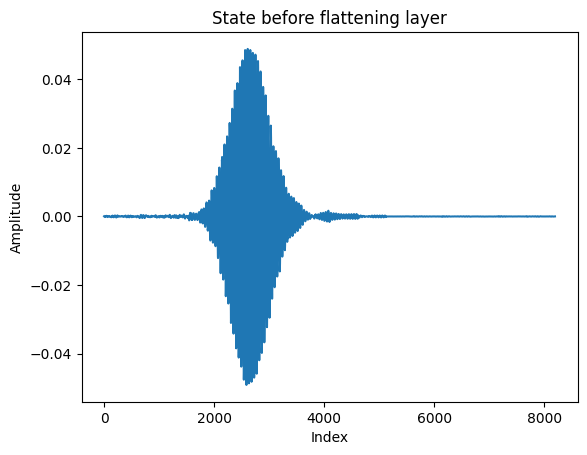

Tau before flattening layer is: 447.288165167058


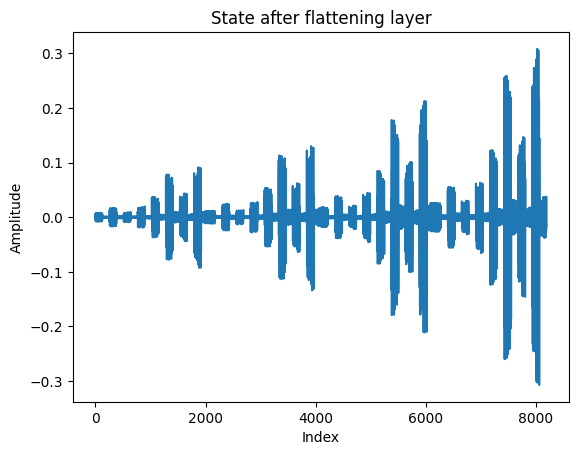

Tau after flattening layer is: 13.000000000000309


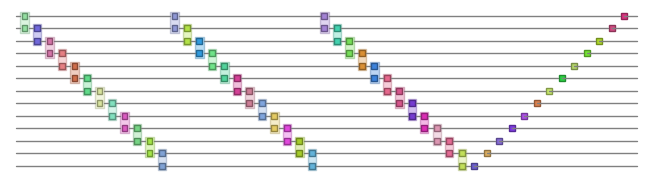

In [18]:
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
real_accoustic_circuit_taued=tau_tn_to_circ(best_tau_layer,real_accoustic_circuit,13,verbose=True)

Far out!! This is a really good strategy then. Best result I have had so far, just one layer of single qubits is able to drag down the tau to almost nothing and not only that but this was done via the IPR so the actual optimisation was really quick.

In [326]:
real_accoustic_circuit.psi.to_dense()

array([[-1.69277808e-02+4.17145590e-03j],
       [ 1.04849487e-02+1.08418314e-02j],
       [ 4.29076748e-03+1.54475660e-02j],
       ...,
       [ 2.49789993e-04-3.27372460e-05j],
       [ 2.71515552e-04+1.48848508e-04j],
       [ 4.61940903e-05-2.75044269e-04j]], shape=(8192, 1))

## Testing Different states with Tau reducer

In [32]:
#This is how you make an arbitary state as the inital in the circuit
n = 10
# Create a random initial ket state
psi0 = qu.rand_ket(2**n)
print(psi0)
psi0_tn = qtn.MatrixProductState.from_dense(psi0,dims=[2] * n)
# Initialize circuit with this state
qc = qtn.Circuit(n, psi0=psi0_tn)

[[-0.013405+0.007587j]
 [ 0.008685-0.017623j]
 [ 0.017246+0.001873j]
 ...
 [-0.024681-0.022569j]
 [-0.006555-0.045163j]
 [-0.026259+0.033446j]]


In [7]:
#ALL FUNCIONS ME AND JOSH MADE FOR TAU MINIMISER
def ipr_loss_function(
    tau_layer: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,  # matches TNOptimizer loss_constants
    eps: float = 1e-12
) -> torch.Tensor:
    """
    Computes the Inverse Participation Ratio (IPR) of a tau_layer
    applied to a prepared MPS state.

    Args:
        tau_layer: SU(2) tensor network layer to apply (trainable).
        init_tn: Prepared MPS state (fixed, passed via TNOptimizer).
        eps: Small number for numerical stability during normalization.

    Returns:
        ipr_loss: Scalar torch.Tensor representing the IPR.
                  Lower values -> amplitudes more uniform.
    """

    # --- Copy inputs to avoid modifying originals ---
    tau_layer = tau_layer.copy()
    init_tn = init_tn.copy()

    # --- Ensure tensors are torch complex and differentiable ---
    #init_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    #tau_layer.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: tensors are guaranteed to be complex and differentiable when passed from ipr_layer_optimise.

    # --- Apply tau_layer to the state ---
    new_state = apply_single_tau_layer(circ_tn=tau_layer, mps=init_tn)
    #Seems fine -- concatenates single-qubit gate layer to MPS. Concatenated state will inherit torch backend.

    # --- Contract full TN to get state vector ---
    vec = new_state.contract(all).data.to_dense().flatten()
    #Not sure about this one -- computing to dense SV?

    # --- Compute probabilities and normalize ---
    probs = torch.abs(vec)**2
    probs = probs / (probs.sum() + eps)  # ensure normalization

    # --- Compute IPR: sum_i p_i^2 ---
    ipr_loss = (probs**2).sum()

    return ipr_loss

def su2_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(2) parametrised tn, initialised with zero for all parameters and indexed to match mps. This is normlaised (at least when hitting zer ostate it gives same sate) """

    qc = qtn.Circuit(n)
    for idx in range(n):
        theta = np.random.uniform(-eps, eps)
        phi   = np.random.uniform(-eps, eps)
        lam   = np.random.uniform(-eps, eps)
        #for some reason it breaks if you have it on only idx? so werid idk what happens here
        qc.apply_gate("u3", *(theta, phi, lam), idx, idx+1,tags=["SU2"], parametrize=True)
    layer = qc.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()
    mapping = {}

    for i in range(13):
        mapping[f'k{i+1}'] = f'k{i}'
        mapping[f'b{i+1}'] = f'b{i}'

    to_opt.reindex_(mapping)
    
    return to_opt

def ipr_layer_optimise(
    init_mps: qtn.TensorNetwork,
    loss=ipr_loss_function,  # default: ipr_loss_function
    verbose: bool = False,
    gauge_iteratively: bool = False
) -> qtn.TensorNetwork:
    """
    Optimises a single SU(2) layer to minimise Inverse Participation Ratio (IPR) 
    when applied to init_mps.

    Args:
        init_mps: Current MPS object representing the state to act on (fixed).
        loss: Loss function. Default is ipr_loss_function.
        verbose: If True, prints optimisation progress.
        gauge_iteratively: If True, applies TN gauging for numerical stability.

    Returns:
        best_layer_tn: The optimised SU(2) layer as a TensorNetwork.
    """

    # --- 1. Copy the input MPS to avoid modifying the original ---
    init_mps = init_mps.copy()

    # --- 2. Build a SU(2) circuit layer (identity initialisation) ---
    to_opt = su2_circ_layer(init_mps.L, 1e-2)  
    #Check -- looks good!
    
    # Convert MPS to complex128
    init_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    #to_opt.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    #Removed: applying compelx128 to torch parameterised tensors (PTensors) makes parameters complex. to_opt already has a torch backend from su2_circ_layer func.

    #print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')
    #Removed: only compute loss using torch.no_grad() for verbose prints (see below)

    if verbose:
        with torch.no_grad():
            print(f'Initial IPR loss = {loss(to_opt, init_tn=init_mps)}')

    # --- 4. Setup bookkeeping to store the best parameters ---
    _best = {
        "val": loss(to_opt, init_tn=init_mps),      # initial loss
        "params": to_opt.get_params(),              # store initial parameters as default
    }

    # --- 5. Function to update best TN seen so far ---
    def get_best(psi):
        """Store parameters of psi if it improves loss."""
        with torch.no_grad():
            val = loss(psi, init_tn=init_mps)
        if val < _best["val"]:
            tn_copy = psi.copy()
            tn_copy.apply_to_arrays(to_numpy)
            _best["params"] = tn_copy.get_params()
            _best["val"] = val
        return psi

    # --- 6. Norm function for TNOptimizer ---
    def get_best_fn(psi):
        """Called during optimization to store best params and optionally gauge."""
        with torch.no_grad():
            _ = get_best(psi.copy())  # bookkeeping on a separate copy
            if gauge_iteratively:
                psi.gauge_all(method='simple', inplace=True)  # stabilise TN contractions
        return psi

    if verbose:
        print('Starting optimisation...')

    # --- 7. Initialise TNOptimizer for the SU(2) layer ---
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss, #Most likely cause of error.
        norm_fn=get_best_fn,
        loss_constants={'init_tn': init_mps},  # pass the fixed state
        tags=['SU2'],  # changed from SU4
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    # --- 8. Run optimisation using basinhopping ---
    opt_layer_tn = tnopt.optimize_basinhopping(
        n=400, tol=1e-16, lr=2, nhop=20
    )
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    # --- 9. Verbose outputs for tracking ---
    if verbose:
        with torch.no_grad():
            print(f'Final IPR loss = {loss(opt_layer_tn, init_tn=init_mps)}')

    # --- 10. Restore best parameters seen during optimization ---
    with torch.no_grad():
        best_layer_tn = opt_layer_tn.copy()
        # safe: _best["params"] is guaranteed not None
        best_layer_tn.set_params(_best["params"])
        best_copy = best_layer_tn.copy()
        best_copy.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

        if verbose:
            print(f'Best IPR loss recorded = {_best["val"]}')
            print(f'After updating, final IPR loss = {loss(best_copy, init_tn=init_mps)}')

    return best_layer_tn
def apply_single_tau_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 1-qubit unitaries to evolve an MPS. mps is the mps that represents the state prep final circuit (ausiostate mps, and constant through this whole process). circ_tn is the tau layer.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #does this conjugate the circuit? NO! | just connects indiices
    new = circ_tn | mps

    #Maybe we dont need all of this, Ill try and go without because my tau function needs dense state vector.
    '''shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))'''


    return new
    #return ensure_mps_shape_lrp(new)
def tau_tn_to_circ(best_tau_layer,circuit,num_qubits,verbose:bool= False,calc_first_tau:bool=True):
    '''Appends the best tau layer onto the end of the circuit and will print the new tau value'''
    if verbose:
        print("Lowest Possible IPR:",2**(-n))
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State before flattening layer")
        plt.show()
        if calc_first_tau==False:
            print("not computing tau before")
        else:
            tau=compute_tau_sparse(circuit.psi.to_dense())
            print("Tau before flattening layer is:",tau)
    for idx in range(num_qubits):
        circuit.apply_gate_raw(best_tau_layer.tensors[idx].data,[idx])
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State after flattening layer")
        plt.show()
    tau=compute_tau_sparse(circuit.psi.to_dense())
    print("Tau after flattening layer is:",tau)
    return circuit

### Acoustic State (sanity check)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Initial IPR loss = 0.0017221856178659075
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000133708868 [best: +0.000132844975] :   2%|▏         | 121/8000 [00:05<06:14, 21.05it/s]
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Final IPR loss = 0.0001328449746688771
Best IPR loss recorded = 0.0001328449746688771
After updating, final IPR loss = 0.0001328449746688771
Lowest Possible IPR: 0.0001220703125


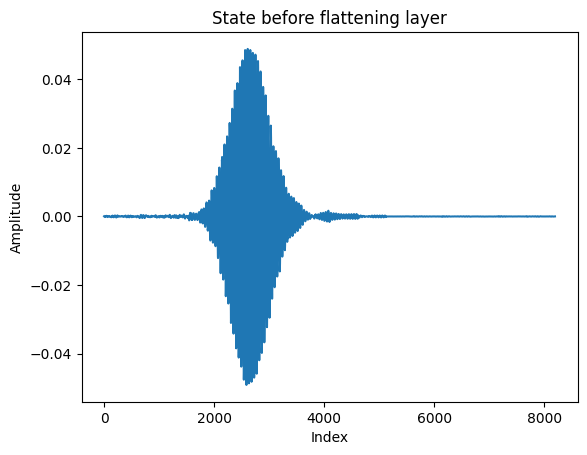

Tau before flattening layer is: 447.2881651674801


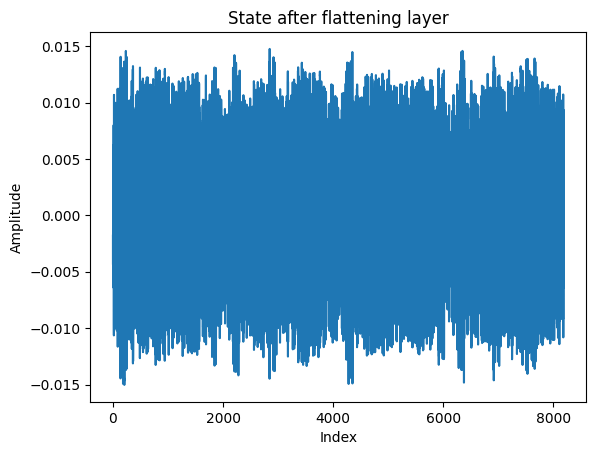

Tau after flattening layer is: 15.9496112380956


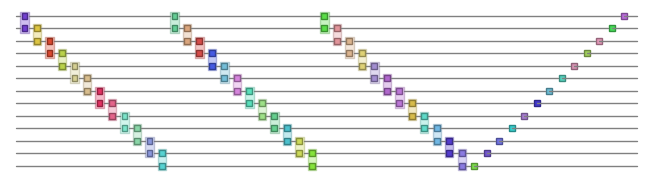

In [126]:
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
audiostate = qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense())/qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense()).norm()
best_tau_layer=ipr_layer_optimise(init_mps=audiostate,verbose=True)
real_accoustic_circuit_taued=tau_tn_to_circ(best_tau_layer,real_accoustic_circuit,13,verbose=True,calc_first_tau=True)

np.float64(16.78801253469952)

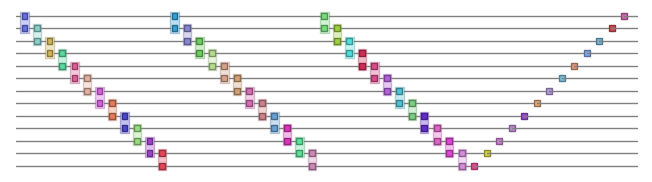

In [118]:

real_accoustic_circuit_taued.draw()
compute_tau_sparse(real_accoustic_circuit_taued.psi.to_dense())

In [119]:
np.linalg.norm(real_accoustic_circuit_taued.psi.to_dense())

np.float64(1.0000000256168207)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Initial IPR loss = 0.0017209276391590912
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000135245961 [best: +0.000133585311] :   1%|▏         | 116/8000 [00:02<03:00, 43.62it/s]
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Final IPR loss = 0.0001335853114595936
Best IPR loss recorded = 0.00013358531145959363
After updating, final IPR loss = 0.0001335853114595936
Lowest Possible IPR: 0.0001220703125


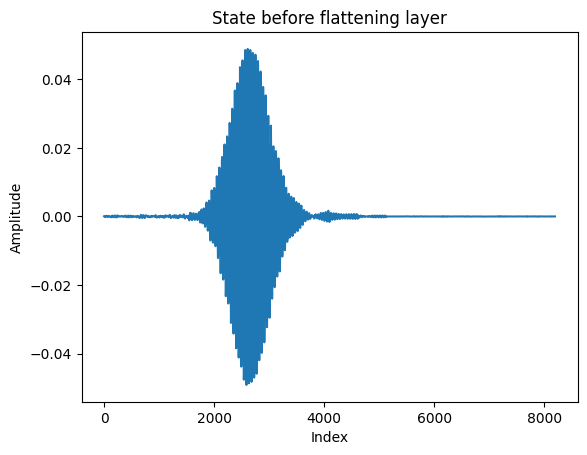

Tau before flattening layer is: 447.28813002233585


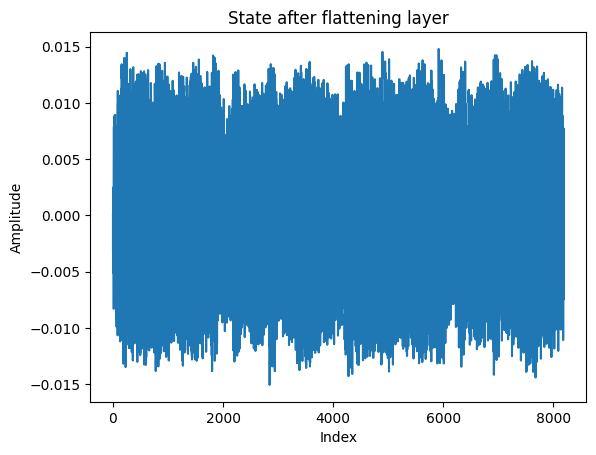

Tau after flattening layer is: 16.58002745766855


In [16]:
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
audiostate = qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense())/qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense()).norm()
# Now replace with direct inital state cicuit construction
n = 13
psi0_tn = audiostate

# Initialize circuit with this state
qc_from_pis0 = qtn.Circuit(n, psi0=psi0_tn)

best_tau_layer=ipr_layer_optimise(init_mps=psi0_tn,verbose=True)
real_accoustic_circuit_taued=tau_tn_to_circ(best_tau_layer,qc_from_pis0,13,verbose=True)

In [128]:
np.linalg.norm(real_accoustic_circuit_taued.psi.to_dense())

np.float64(0.9999999999999987)

### Single basis state

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


1.0
Lowest Possible IPR: 0.0001220703125
Initial IPR loss = 0.9998170553425105
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000122070615 [best: +0.000122070449] :   1%|          | 85/8000 [00:03<05:57, 22.11it/s]
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Final IPR loss = 0.00012207044949064712
Best IPR loss recorded = 0.00012207044949064712
After updating, final IPR loss = 0.00012207044949064712
Lowest Possible IPR: 0.0001220703125


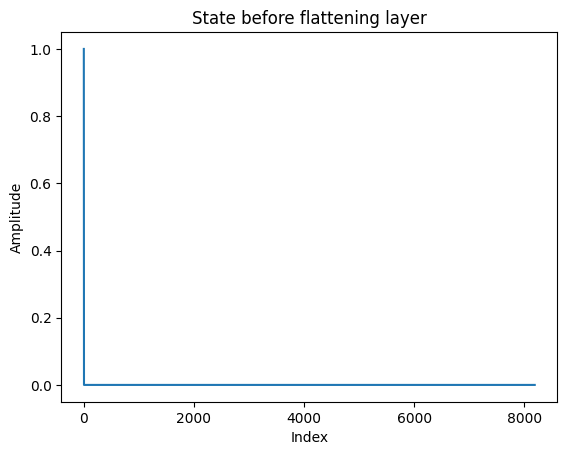

not computing tau before


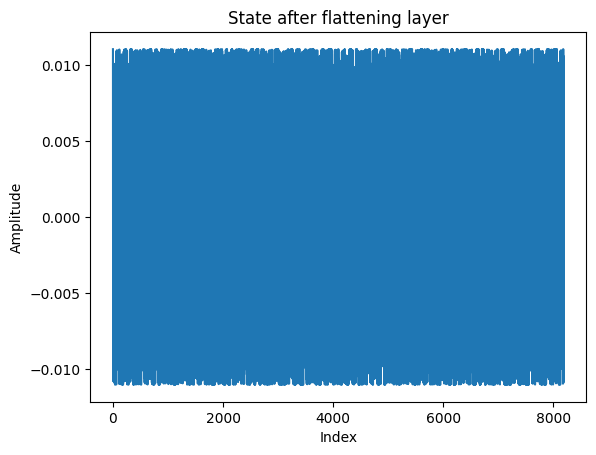

Tau after flattening layer is: 13.000000000000497


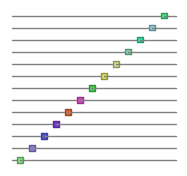

In [130]:
def basis_state(n, x):
    psi = np.zeros(2**n, dtype=complex)
    psi[x] = 1.0
    return psi

n = 13
#Set psi as desired state to test
psi = basis_state(n, x=0)
psi/= np.linalg.norm(psi)

psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()

# Initialize circuit with this state
qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print(np.linalg.norm(qc_from_psi0.psi.to_dense()))
print("Lowest Possible IPR:",2**(-n))
best_tau_layer=ipr_layer_optimise(init_mps=psi0_tn,verbose=True)
qc_from_pis0_taued=tau_tn_to_circ(best_tau_layer,qc_from_psi0,13,verbose=True,calc_first_tau=False)


In [65]:
np.linalg.norm(qc_from_pis0_taued.psi.to_dense())

np.float64(90.50966799187813)

In [53]:
best_tau_layer.tensors[1].data

array([[ 0.70732517+0.j        , -0.25506796+0.65926584j],
       [-0.68275051-0.18314706j, -0.41742465+0.5710215j ]])

In [54]:

for T in best_tau_layer.tensors:
    T=T.data
    check = T.conj().T @ T
    print(np.linalg.norm(check - np.eye(2)))

7.850462293418876e-17
2.1588771306901906e-16
1.962615573354719e-17
2.220446049250313e-16
7.850462293418876e-17
0.0
1.415262216750919e-16
3.236828524569469e-16
1.2719202621569003e-16
2.2291027918243403e-16
1.1775693440128312e-16
2.844205973472036e-16
1.1102230246251565e-16


### Hamming Ball state (tau was not reduced here!)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Norm Before Layer 0.9999999999999996
Lowest Possible IPR: 0.0001220703125
Initial IPR loss = 0.010869133773249044
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000407462944 [best: +0.000406155757] :   2%|▏         | 148/8000 [00:04<03:40, 35.69it/s]
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Final IPR loss = 0.0004061557574276743
Best IPR loss recorded = 0.00040615575742767435
After updating, final IPR loss = 0.0004061557574276743
Lowest Possible IPR: 0.0001220703125


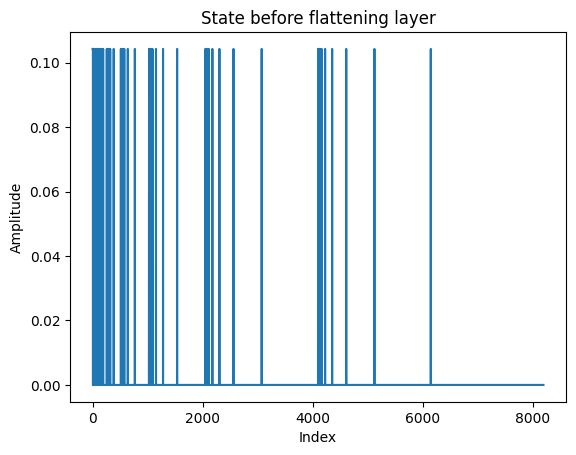

Tau before flattening layer is: 24.132534901513036


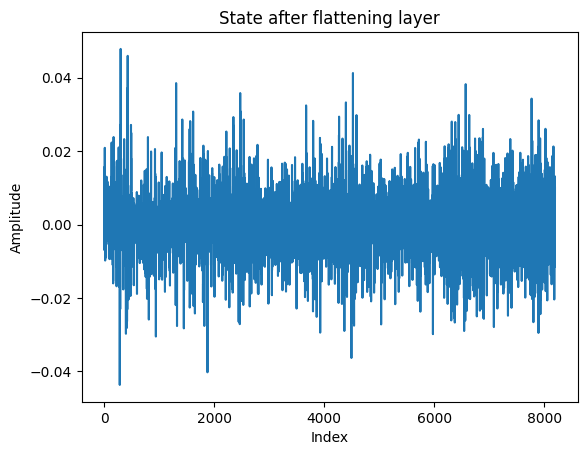

Tau after flattening layer is: 46.892213925957854


In [271]:
def hamming_ball_state(n, k):
    psi = np.zeros(2**n, dtype=complex)
    for x in range(2**n):
        if bin(x).count("1") <= k:
            psi[x] = 1.0
    psi /= np.linalg.norm(psi)
    return psi

psi = hamming_ball_state(n=13, k=2)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
n=13
N=2**13
# Initialize circuit with this state
qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print("Norm Before Layer",np.linalg.norm(qc_from_psi0.psi.to_dense()))
print("Lowest Possible IPR:",2**(-n))
best_tau_layer=ipr_layer_optimise(init_mps=psi0_tn,verbose=True)
qc_from_pis0_taued=tau_tn_to_circ(best_tau_layer,qc_from_psi0,13,verbose=True)

NOTE THIS STATE IT DOES NOT WORK FOR!

### Random Sparse State

Sparse Random State Norm Before Layer: 1.0000000000000004
Initial IPR loss = 0.3784631985225203
Starting optimisation...


+0.000122156544 [best: +0.000122130544] :   2%|▏         | 132/8000 [00:06<06:13, 21.06it/s]


Final IPR loss = 0.00012213054380196504
Best IPR loss recorded = 0.00012213054380196504
After updating, final IPR loss = 0.00012213054380196504
Lowest Possible IPR: 0.0001220703125


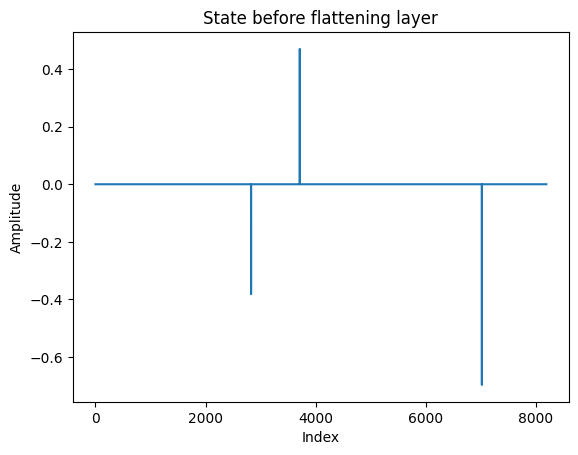

Tau before flattening layer is: 310593077749689.4


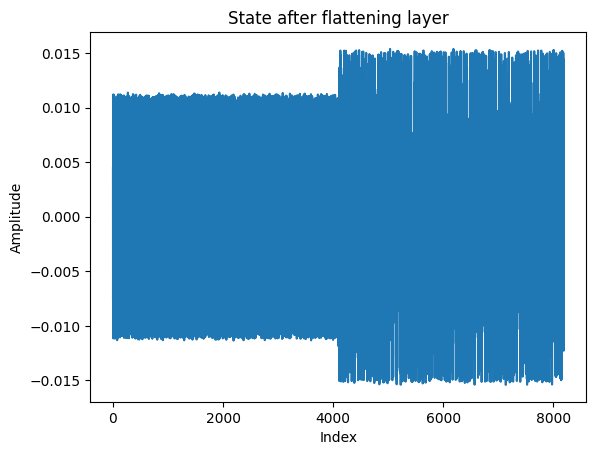

Tau after flattening layer is: 32.784328194921514


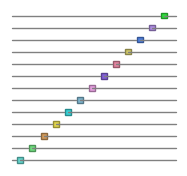

In [135]:
# -----------------------------
# 2️⃣ Random Sparse State
# -----------------------------
def sparse_random_state(n, k):
    indices = np.random.choice(2**n, k, replace=False)
    amplitudes = np.random.randn(k) + 1j*np.random.randn(k)
    amplitudes /= np.linalg.norm(amplitudes)
    
    psi_dense = np.zeros(2**n, dtype=complex)
    psi_dense[indices] = amplitudes
    return psi_dense

k_sparse = 3
psi = sparse_random_state(n, k_sparse)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()

qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print("Sparse Random State Norm Before Layer:", np.linalg.norm(qc_from_psi0.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=True)



### Random Fully Dense

Random Dense State Norm Before Layer: 0.9999999999999993
Initial IPR loss = 0.00024028161357185208
Starting optimisation...


+0.000238753798 [best: +0.000238753798] :   0%|          | 21/8000 [00:01<11:14, 11.83it/s]


Final IPR loss = 0.00023875379816791422
Best IPR loss recorded = 0.00023875379816791422
After updating, final IPR loss = 0.00023875379816791422
Lowest Possible IPR: 0.0001220703125


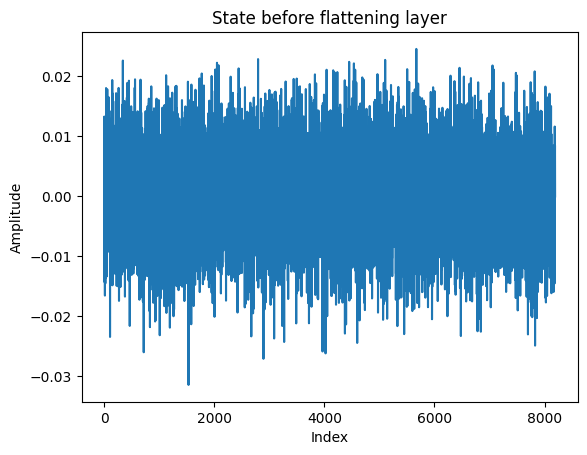

Tau before flattening layer is: 23.92349978564718


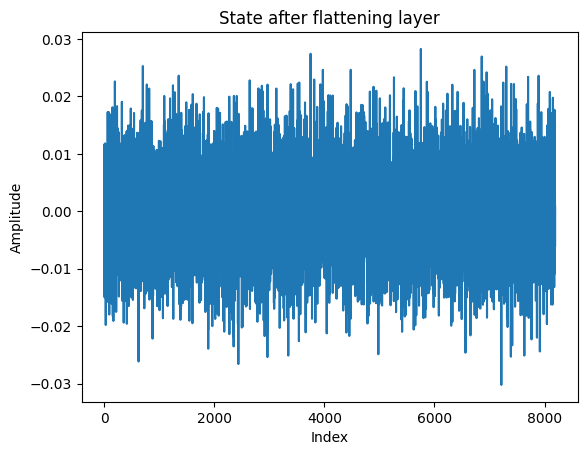

Tau after flattening layer is: 23.60382752847066


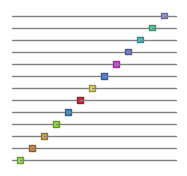

In [136]:
# -----------------------------
# 4️⃣ Fully Random Dense State (optional)
# -----------------------------
def random_dense_state(n):
    psi = np.random.randn(2**n) + 1j*np.random.randn(2**n)
    psi /= np.linalg.norm(psi)
    return psi

psi = random_dense_state(n)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()

qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print("Random Dense State Norm Before Layer:", np.linalg.norm(qc_from_psi0.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=True)


### Assorted Discretized function states

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Quadratic Polynomial State Norm: 0.9999999999999998
Initial IPR loss = 0.00034041431585560766
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000123058133 [best: +0.000122800822] :   1%|          | 79/8000 [00:03<06:12, 21.27it/s]
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Final IPR loss = 0.00012280082165560055
Best IPR loss recorded = 0.00012280082165560055
After updating, final IPR loss = 0.00012280082165560055
Lowest Possible IPR: 0.0001220703125


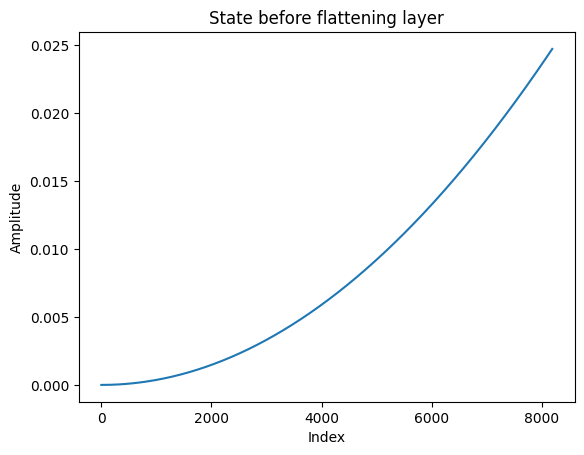

Tau before flattening layer is: 14.186784756467729


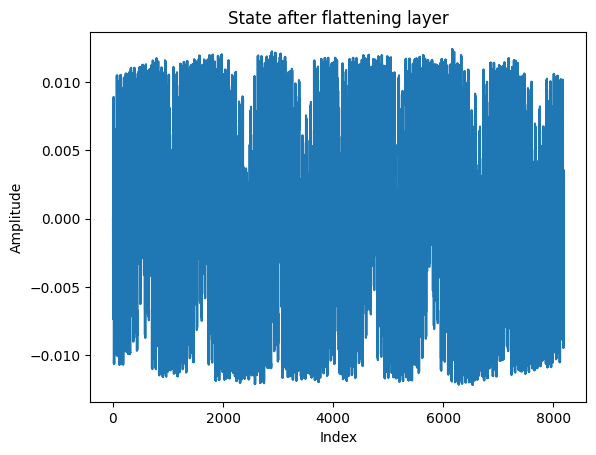

Tau after flattening layer is: 13.488989003106155
Cubic Polynomial State Norm: 1.0
Initial IPR loss = 0.0004633929333600923
Starting optimisation...


+0.000123171869 [best: +0.000122791730] :   1%|          | 82/8000 [00:03<06:08, 21.48it/s]


Final IPR loss = 0.00012279173033074263
Best IPR loss recorded = 0.00012279173033074263
After updating, final IPR loss = 0.00012279173033074263
Lowest Possible IPR: 0.0001220703125


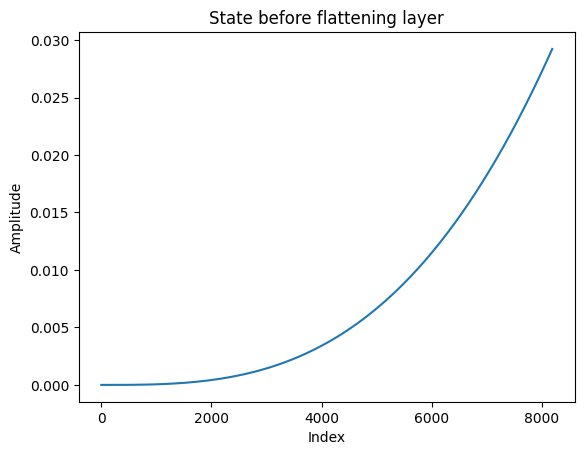

Tau before flattening layer is: 13.680442452077804


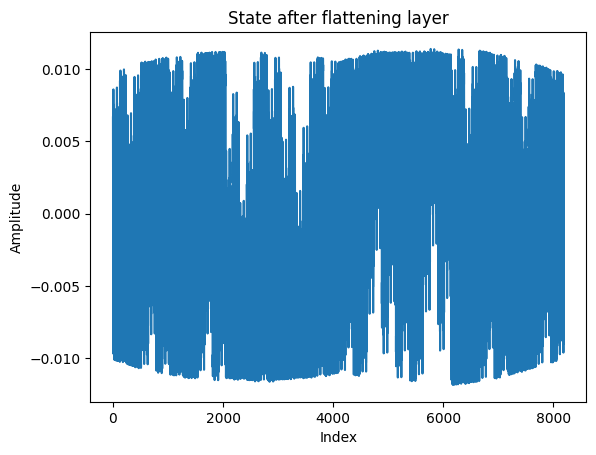

Tau after flattening layer is: 13.674618762055326
Sinusoidal State Norm: 1.0000000000000002
Initial IPR loss = 0.00018319138231698978
Starting optimisation...


+0.000122986819 [best: +0.000122782665] :   1%|          | 81/8000 [00:03<05:54, 22.35it/s]


Final IPR loss = 0.00012278266502928814
Best IPR loss recorded = 0.00012278266502928814
After updating, final IPR loss = 0.00012278266502928814
Lowest Possible IPR: 0.0001220703125


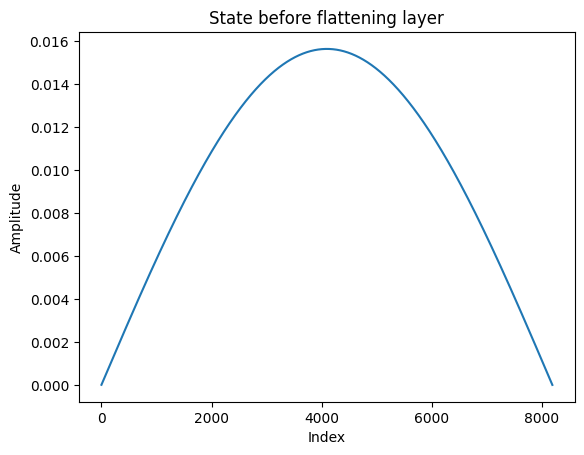

Tau before flattening layer is: 41.2998743199829


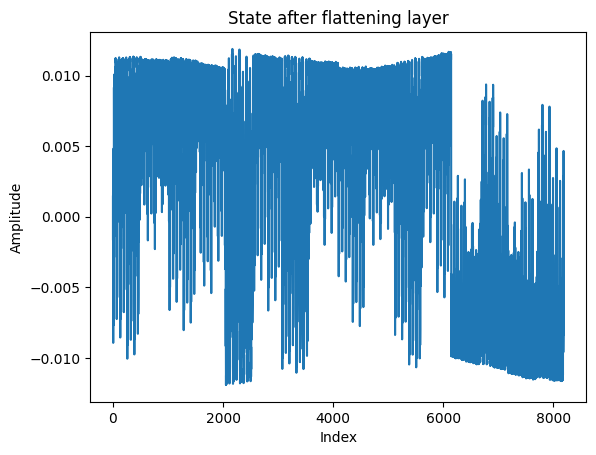

Tau after flattening layer is: 13.876977218340121
Cos Squared State Norm: 1.0000000000000004
Initial IPR loss = 0.00021960257732214056
Starting optimisation...


+0.000130808475 [best: +0.000126816037] :   1%|          | 82/8000 [00:03<05:53, 22.37it/s]


Final IPR loss = 0.00012681603666778586
Best IPR loss recorded = 0.00012681603666778586
After updating, final IPR loss = 0.00012681603666778586
Lowest Possible IPR: 0.0001220703125


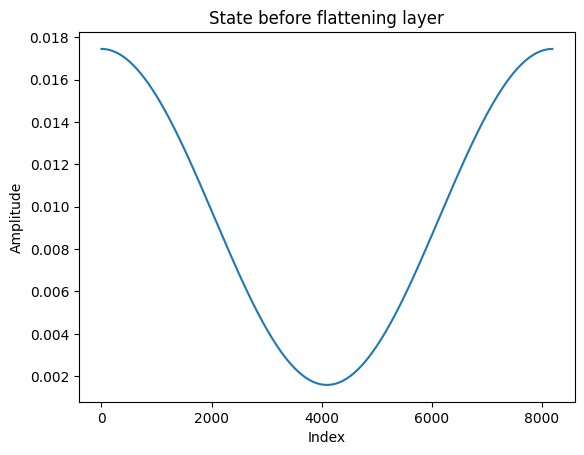

Tau before flattening layer is: 71.99693179731624


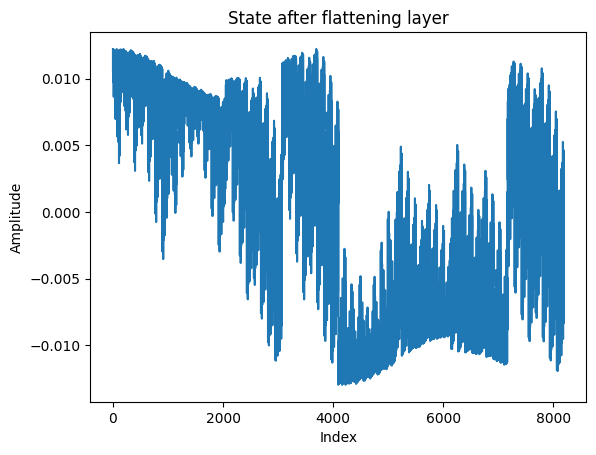

Tau after flattening layer is: 15.909062173857318
Sawtooth State Norm: 0.9999999999999993
Initial IPR loss = 0.00021814485988837644
Starting optimisation...


+0.000139116130 [best: +0.000138791267] :   1%|          | 91/8000 [00:04<06:19, 20.85it/s]


Final IPR loss = 0.000138791266992711
Best IPR loss recorded = 0.000138791266992711
After updating, final IPR loss = 0.000138791266992711
Lowest Possible IPR: 0.0001220703125


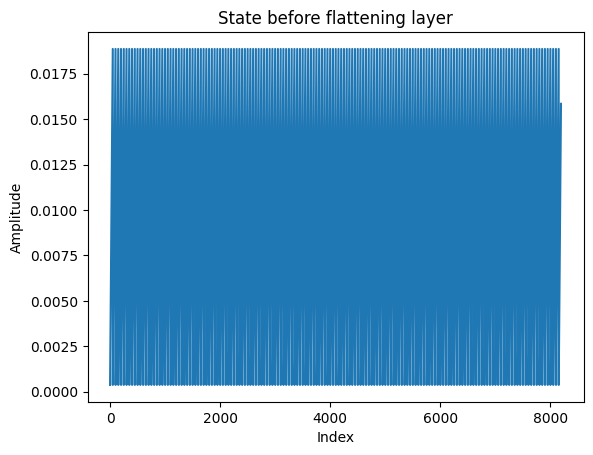

Tau before flattening layer is: 43.499996954397254


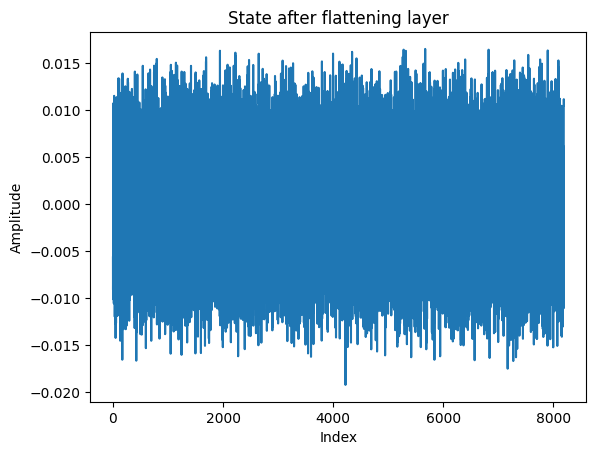

Tau after flattening layer is: 15.377699581636877
Modulated Sine-Poly State Norm: 1.0000000000000002
Initial IPR loss = 0.00025099753951375017
Starting optimisation...


+0.000141101050 [best: +0.000134310475] :   1%|          | 89/8000 [00:04<07:11, 18.35it/s]


Final IPR loss = 0.00013431047476873524
Best IPR loss recorded = 0.00013431047476873524
After updating, final IPR loss = 0.00013431047476873524
Lowest Possible IPR: 0.0001220703125


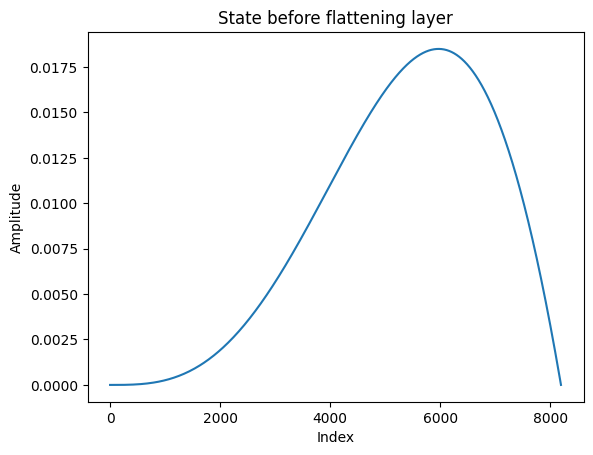

Tau before flattening layer is: 40.61719787099792


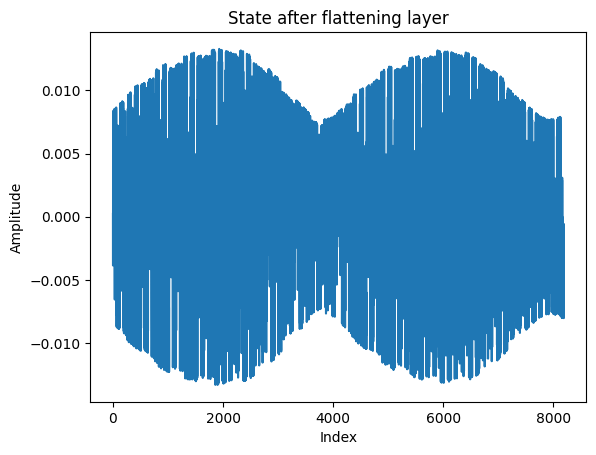

Tau after flattening layer is: 18.224019670578755


In [139]:

n = 13  # number of qubits

# -----------------------------
# 1️⃣ Quadratic Polynomial State
# -----------------------------
x = np.arange(2**n)
psi = (x**2) + 1.0
psi = psi.astype(complex)
psi /= np.linalg.norm(psi)

psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
qc_poly = qtn.Circuit(n, psi0=psi0_tn)
print("Quadratic Polynomial State Norm:", np.linalg.norm(qc_poly.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_poly_taued = tau_tn_to_circ(best_tau_layer, qc_poly, n, verbose=True)

# -----------------------------
# 2️⃣ Cubic Polynomial State
# -----------------------------
psi = (x**3 + 1.0).astype(complex)
psi /= np.linalg.norm(psi)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
qc_cubic = qtn.Circuit(n, psi0=psi0_tn)
print("Cubic Polynomial State Norm:", np.linalg.norm(qc_cubic.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_cubic_taued = tau_tn_to_circ(best_tau_layer, qc_cubic, n, verbose=True)

# -----------------------------
# 3️⃣ Sinusoidal State
# -----------------------------
psi = np.sin((x + 1) * np.pi / (2**n)).astype(complex)
psi /= np.linalg.norm(psi)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
qc_sin = qtn.Circuit(n, psi0=psi0_tn)
print("Sinusoidal State Norm:", np.linalg.norm(qc_sin.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_sin_taued = tau_tn_to_circ(best_tau_layer, qc_sin, n, verbose=True)

# -----------------------------
# 4️⃣ Cosine Squared Envelope
# -----------------------------
psi = (np.cos(x * np.pi / 2**n)**2 + 0.1).astype(complex)  # add 0.1 to avoid zeros
psi /= np.linalg.norm(psi)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
qc_cos2 = qtn.Circuit(n, psi0=psi0_tn)
print("Cos Squared State Norm:", np.linalg.norm(qc_cos2.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_cos2_taued = tau_tn_to_circ(best_tau_layer, qc_cos2, n, verbose=True)

# -----------------------------
# 5️⃣ Sawtooth / Linear Ramp
# -----------------------------
psi = (x % 50 + 1).astype(complex)  # small repeating ramp
psi /= np.linalg.norm(psi)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
qc_saw = qtn.Circuit(n, psi0=psi0_tn)
print("Sawtooth State Norm:", np.linalg.norm(qc_saw.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_saw_taued = tau_tn_to_circ(best_tau_layer, qc_saw, n, verbose=True)

# -----------------------------
# 6️⃣ Randomly Modulated Sine + Polynomial
# -----------------------------
psi = ((x**2 + 1) * np.sin((x + 1) * np.pi / 2**n)).astype(complex)
psi /= np.linalg.norm(psi)
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
qc_mod_sin = qtn.Circuit(n, psi0=psi0_tn)
print("Modulated Sine-Poly State Norm:", np.linalg.norm(qc_mod_sin.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_mod_sin_taued = tau_tn_to_circ(best_tau_layer, qc_mod_sin, n, verbose=True)



### Ising State (13 qubits)

In [ ]:
# --- quantum Ising model at the critical point ---
L  = 13       # number of spins/qubits
J  = 1.0       # Ising coupling
hx = 0.5       # transverse field, critical point ~ J
S  = 0.5       # spin-1/2

# Build Hamiltonian as an MPO (transverse-field Ising)
H_mpo = qtn.MPO_ham_ising(L, j=J, bx=hx, S=S, cyclic=False)

# DMRG for the ground state (need higher bond dims at criticality)
dmrg = qtn.DMRG(
    H_mpo,
    bond_dims=[64, 128, 256],
    cutoffs=[1e-8, 1e-9, 1e-10],
)

dmrg.solve(tol=1e-8, verbosity=1)

E0_crit = dmrg.energy      # ground-state energy
psi_crit = dmrg.state

1, R, max_bond=(64/64), cutoff:1e-08


100%|###########################################| 12/12 [00:00<00:00, 21.93it/s]

Energy: -4.049607832068567 ... not converged.
2, R, max_bond=(8/128), cutoff:1e-09



100%|###########################################| 12/12 [00:00<00:00, 46.53it/s]

Energy: -4.049608480436109 ... not converged.
3, R, max_bond=(8/256), cutoff:1e-10



100%|###########################################| 12/12 [00:00<00:00, 46.05it/s]

Energy: -4.049608488895203 ... converged!


In [145]:
psi_crit.to_dense()

array([[-0.00037584],
       [-0.00056248],
       [-0.00091885],
       ...,
       [-0.00091885],
       [-0.00056248],
       [-0.00037584]], shape=(8192, 1))

Random Dense State Norm Before Layer: 0.9999999999999991


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Initial IPR loss = 0.008691651995569418
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000164279074 [best: +0.000164008624] :   2%|▏         | 149/8000 [00:09<08:08, 16.06it/s]


Final IPR loss = 0.00016400862359016913
Best IPR loss recorded = 0.00016400862359016913
After updating, final IPR loss = 0.00016400862359016913
Lowest Possible IPR: 0.0001220703125


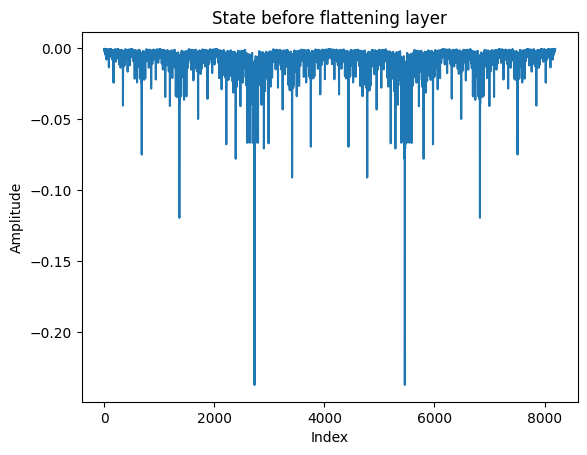

Tau before flattening layer is: 135.94012328069925


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


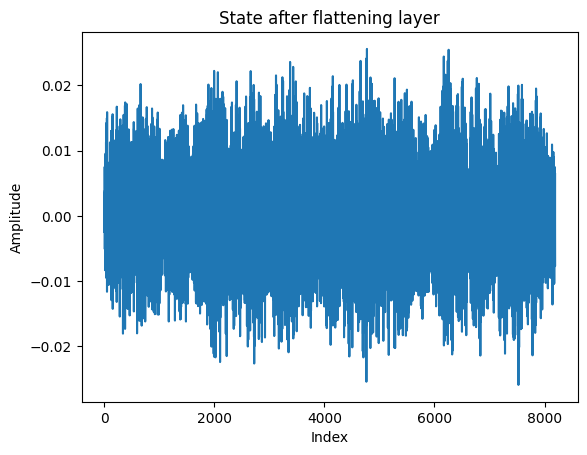

Tau after flattening layer is: 24.8018466170479


In [146]:
psi = psi_crit.to_dense()
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()

qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print("Random Dense State Norm Before Layer:", np.linalg.norm(qc_from_psi0.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=True)

### MBL Hamiltonian

In [190]:
# --- Parameters ---
n = 14                 # number of spins
dh = 1.0               # strength of random fields
dh_dist = 'g'          # Gaussian distribution
seed = 42              # for reproducibility

# --- Step 1: Construct the MBL Hamiltonian ---
H = qu.ham_mbl(n, dh, dh_dist=dh_dist, seed=seed, sparse=True)

# --- Step 2: Solve for the ground state (smallest eigenvalue) ---
evals, evecs = qu.eigh(H, k=1)  # sparse Hermitian solver, lowest energy
E0 = float(evals[0])
psi0 = evecs if evecs.ndim == 1 else evecs[:, 0]  # ensure it's a 1D vector

# --- Step 3: Convert the dense statevector to an MPS ---
mps = qtn.MatrixProductState.from_dense(
    psi0,
    cutoff=0.0  # exact representation initially
)

# --- Optional Step 4: Compress the MPS ---
mps.compress(max_bond=64, cutoff=1e-16)
mps /= mps.norm()  # normalize
mbl_state=mps.to_dense()


Random Dense State Norm Before Layer: 0.9999999999999993
Initial IPR loss = 0.054828946663797916
Starting optimisation...


+0.000030715851 [best: +0.000021492397] :   1%|          | 58/8000 [00:03<08:50, 14.98it/s]


Final IPR loss = 2.149239702229474e-05
Best IPR loss recorded = 2.1492397022294747e-05
After updating, final IPR loss = 2.149239702229474e-05
Lowest Possible IPR: 6.103515625e-05


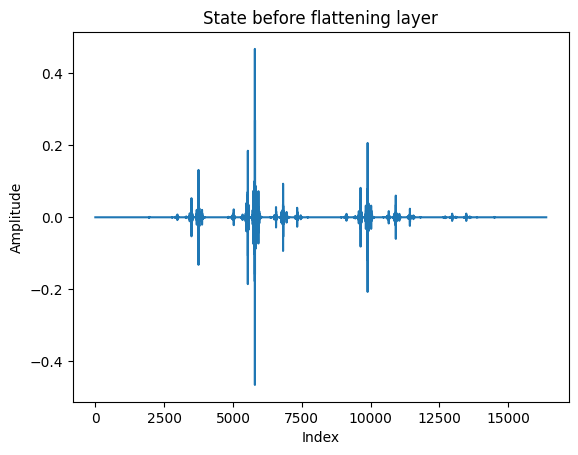

Tau before flattening layer is: 76332197074076.2


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


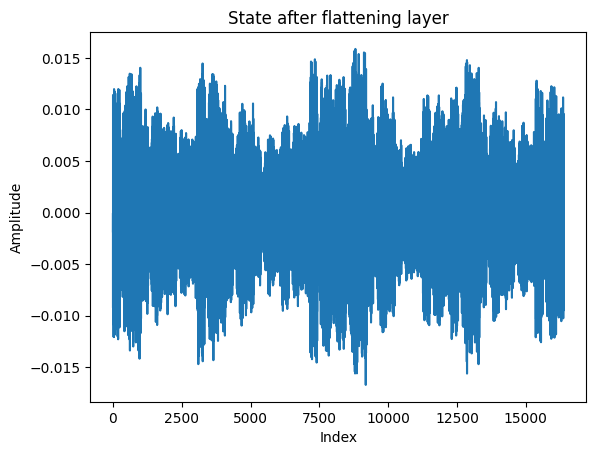

Tau after flattening layer is: 24.522403642512902


In [150]:
psi = mbl_state
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()

qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print("Random Dense State Norm Before Layer:", np.linalg.norm(qc_from_psi0.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=True)

### Hubbard Hamiltonian

In [188]:
# --- Parameters ---
n = 14                  # number of sites
t = 0.5                 # hopping energy
V = 1.0                 # interaction energy
mu = 1.0                # chemical potential
cyclic = False           # open boundary
parallel = False         # parallel construction of H

# --- Step 1: Build the Hubbard hardcore Hamiltonian ---
H = qu.ham_hubbard_hardcore(
    n=n,
    t=t,
    V=V,
    mu=mu,
    cyclic=cyclic,
    parallel=parallel,
    sparse=True
)

# --- Step 2: Solve for the ground state ---
evals, evecs = qu.eigh(H, k=1)  # smallest eigenvalue & eigenvector
E0 = float(evals[0])
psi0 = evecs if evecs.ndim == 1 else evecs[:, 0]  # ensure 1D vector

# --- Step 3: Convert dense statevector to an MPS ---
mps_hub = qtn.MatrixProductState.from_dense(
    psi0,
    cutoff=0.0   # exact initially
)

# --- Step 4: Optionally compress the MPS ---
mps_hub.compress(max_bond=64, cutoff=1e-10)
mps_hub /= mps_hub.norm()  # normalize

Random Dense State Norm Before Layer: 1.0


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Initial IPR loss = 0.006097805088167593
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000036677782 [best: +0.000036677782] :   1%|          | 70/8000 [00:02<04:05, 32.35it/s]


Final IPR loss = 3.667778188711198e-05
Best IPR loss recorded = 3.667778188711198e-05
After updating, final IPR loss = 3.667778188711198e-05
Lowest Possible IPR: 6.103515625e-05


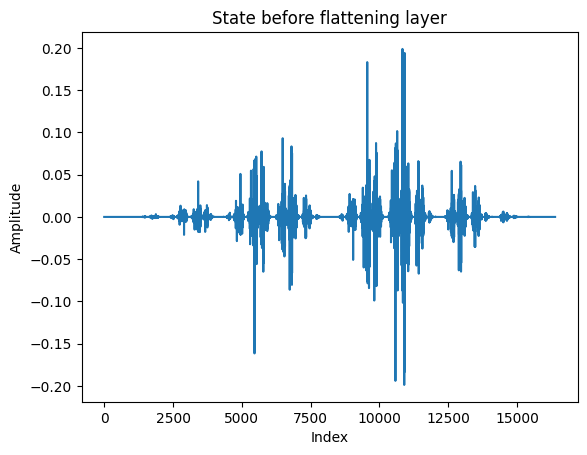

Tau before flattening layer is: 104734875055127.81


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


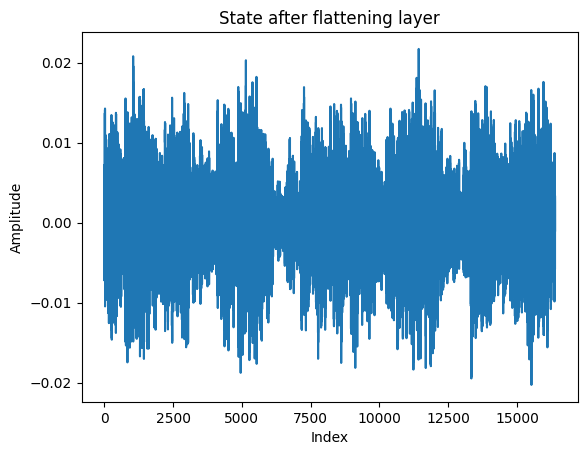

Tau after flattening layer is: 29.227345769612157


In [189]:
psi = mps_hub.to_dense()
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()

qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print("Random Dense State Norm Before Layer:", np.linalg.norm(qc_from_psi0.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=True)

### 2D Heisenberg

In [287]:
# --- build H(Heisenberg), solve, and make an MPS ---

np.random.seed(42)
Lx, Ly = 4, 4
H = qu.ham_heis_2D(Lx, Ly, j=1.0, cyclic=False, sparse=True)

# smallest eigenpair (ground state) via sparse Hermitian solver
evals, evecs = qu.eigh(H, k=1)          # returns lowest energy & eigenvector
E0 = float(evals[0])
psi0 = evecs if evecs.ndim == 1 else evecs[:, 0]   # ensure 1D statevector

# convert the dense statevector to an MPS (exact, then optionally compress)
ham_mps = qtn.MatrixProductState.from_dense(
    psi0, 
    #L=Lx * Ly,            # 12 spins in row-major ordering
    cutoff=0.0            # keep exact initially
)

# (Optional) compress to a manageable bond dimension
ham_mps.compress(max_bond=64, cutoff=1e-7)
ham_mps/=ham_mps.norm()

Random Dense State Norm Before Layer: 0.9999999999999997


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Initial IPR loss = 0.0039065057252740225
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000019525640 [best: +0.000015978014] :   1%|          | 47/8000 [00:03<08:29, 15.61it/s]


Final IPR loss = 1.597801409916765e-05
Best IPR loss recorded = 1.5978014099167656e-05
After updating, final IPR loss = 1.597801409916765e-05
Lowest Possible IPR: 1.52587890625e-05


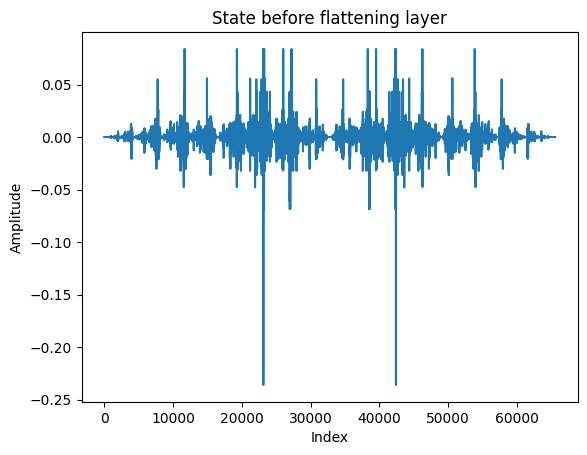

Tau before flattening layer is: 150119987579016.53


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


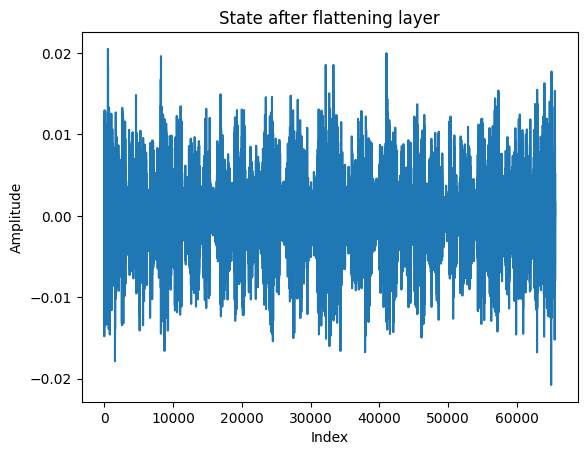

Tau after flattening layer is: 51.95367087626606


In [289]:
psi = ham_mps.to_dense()
n=16
N=2**n
psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()

qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
print("Random Dense State Norm Before Layer:", np.linalg.norm(qc_from_psi0.psi.to_dense()))
best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=True)
qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=True)

## Graphing results of specifc states of interest (tau reduction layer graph, not just ipr and tau link)

All of this is great! Really promising how well tau can reduce states and seems to work. general intuition is that the worse the state is the better the ipr can be reduced. would be great to get a proof for this!

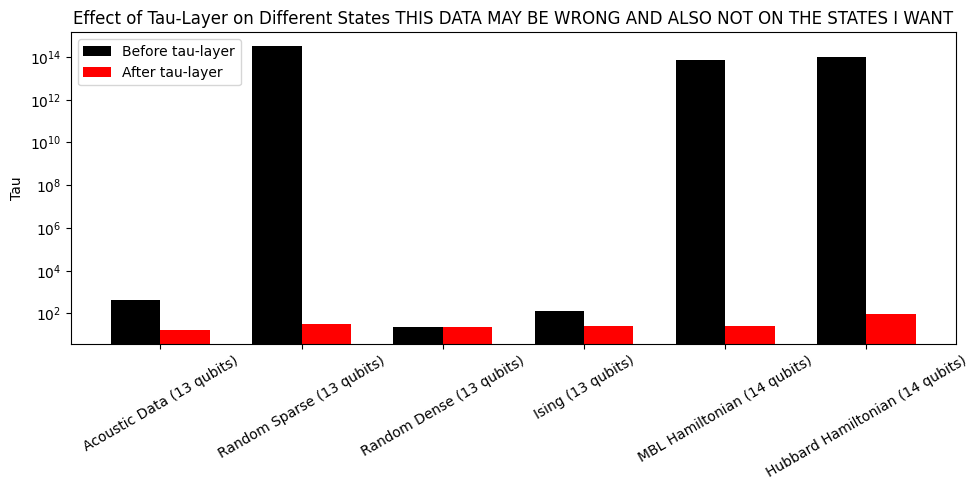

In [ ]:
state_labels = ['Acoustic Data (13 qubits)','Random Sparse (13 qubits)','Random Dense (13 qubits)','Ising (13 qubits)','MBL Hamiltonian (14 qubits)','Hubbard Hamiltonian (14 qubits)']
state_data=[(447.3,17.49),(310593077749689.4,32.784328194921514),(23.92349978564718,23.60382752847066),(135.94012328069925,24.8018466170479),(76332197074076.2,24.522403642512902),(95821268667457.36,97.3525063583732)]
import matplotlib.pyplot as plt
import numpy as np

def plot_tau_reduction(tau_list, labels=None):
    """
    Plot tau reduction for a list of states.

    Args:
        tau_list: list of tuples (tau_before, tau_after)
        labels: optional list of strings for each state
    """

    tau_before = [t[0] for t in tau_list]
    tau_after  = [t[1] for t in tau_list]
    n = len(tau_list)

    # Default labels if none provided
    if labels is None:
        labels = [f"State {i+1}" for i in range(n)]

    x = np.arange(n)
    width = 0.35

    # --- Bar chart ---
    fig, ax = plt.subplots(figsize=(10,5))
    ax.bar(x - width/2, tau_before, width, label='Before tau-layer',color='black')
    ax.bar(x + width/2, tau_after, width, label='After tau-layer',color='red')

    ax.set_ylabel('Tau')
    ax.set_yscale('log')
    ax.set_title('Effect of Tau-Layer on Different States THIS DATA MAY BE WRONG AND ALSO NOT ON THE STATES I WANT')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30)
    ax.legend()
    plt.tight_layout()
    plt.show()


plot_tau_reduction(state_data, state_labels)


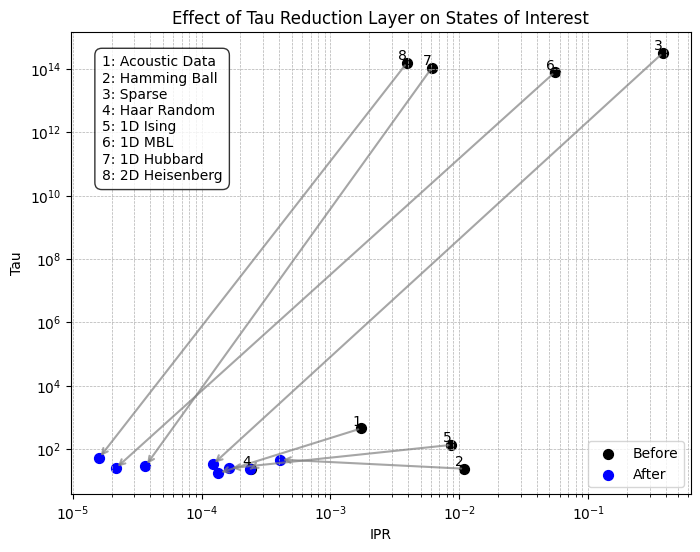

In [291]:
import matplotlib.pyplot as plt

# Your data
data = [
    (0.001723501318895288, 447.2881300218694, 0.00013498851404575524, 17.493241752710276),
    (0.010869133773249044, 24.132534901513036, 0.0004061557574276743, 46.892213925957854),
    (0.3784631985225203, 310593077749689.4, 0.00012213054380196504, 32.784328194921514),
    (0.00024028161357185208, 23.92349978564718, 0.00023875379816791422, 23.60382752847066),
    (0.008691651995569418, 135.94012328069925, 0.00016400862359016913, 24.8018466170479),
    (0.054828946663797916, 76332197074076.2, 2.149239702229474e-05, 24.522403642512902),
    (0.006097805088167593, 104734875055127.81, 3.667778188711198e-05, 29.227345769612157),
    (0.0039065057252740225,150119987579016.53,1.597801409916765e-05,51.95367087626606)
]

plt.figure(figsize=(8, 6))

for before_x, before_y, after_x, after_y in data:
    plt.scatter(before_x, before_y, color='black', s=50, label='Before')
    plt.scatter(after_x, after_y, color='blue', s=50, label='After')
    
    # Use annotate for arrows that respect log scale
for i, (bx, by, ax, ay) in enumerate(data, 1):
    plt.annotate(
        '', xy=(ax, ay), xytext=(bx, by),
        arrowprops=dict(arrowstyle='->', color='gray', lw=1.5, alpha=0.7)
    )
    # Annotate the starting point with a number
    plt.text(bx, by, str(i), color='black', fontsize=10,
             ha='right', va='bottom')  # adjust ha/va to position nicely

# Clean up duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

labels_dict = {
    1: "Acoustic Data",
    2: "Hamming Ball",
    3: "Sparse",
    4: "Haar Random",
    5: "1D Ising",
    6: "1D MBL",
    7: "1D Hubbard",
    8: "2D Heisenberg"
}
# Add a boxed annotation with number -> label mapping
legend_text = "\n".join([f"{k}: {v}" for k, v in labels_dict.items()])
plt.text(
    0.05, 0.95,  # position in axis coordinates (0=left/bottom, 1=top/right)
    legend_text,
    transform=plt.gca().transAxes,  # use axis coordinates
    fontsize=10,
    verticalalignment='top',
    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.5', alpha=0.8)
)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("IPR")
plt.ylabel("Tau")
plt.title("Effect of Tau Reduction Layer on States of Interest")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.show()


## Grpahing Tau and IPR plots for various states

kinda stuck on a proof for this so ill just collect some evidence on how IPR and tau are related (a good idea)!

In [6]:
def tau_ipr_analyse(state_vector):
    ipr = np.sum(np.abs(state_vector)**4)
    tau=compute_tau_sparse(state_vector)
    return (ipr,tau)

### Haar random

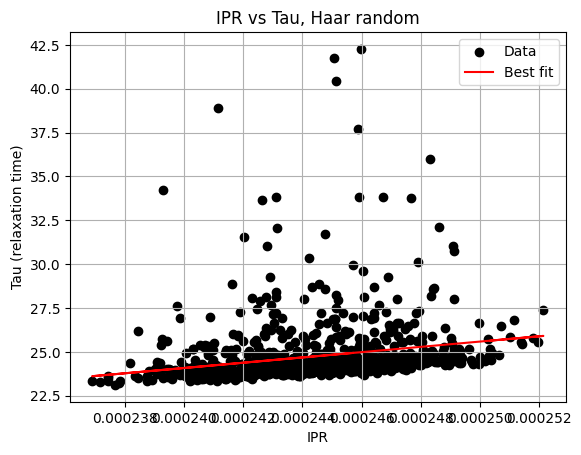

In [230]:
def plot_ipr_tau(data,title):
    """
    Plot IPR vs tau as black dots with a red linear best-fit line.
    
    Parameters
    ----------
    data : list of tuples
        Each tuple is (ipr, tau)
    """
    import matplotlib.pyplot as plt
    import numpy as np

    # unzip and convert to np arrays
    iprs, taus = zip(*data)
    iprs = np.array(iprs)
    taus = np.array(taus)

    # Scatter plot: black dots
    plt.scatter(iprs, taus, color='black', label='Data')

    # Fit a straight line: tau = m*IPR + b
    m, b = np.polyfit(iprs, taus, 1)
    taus_fit = m * iprs + b

    # Plot the fit line in red
    plt.plot(iprs, taus_fit, color='red', label='Best fit')

    # Labels and legend
    plt.xlabel('IPR')
    plt.ylabel('Tau (relaxation time)')
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.show()
    
tau_ipr_data=[]
for i in range(1000):
    #number of qubits
    n=13
    # real and imaginary parts
    psi_real = np.random.randn(2**n)
    psi_imag = np.random.randn(2**n)

    # combine into complex vector
    psi = psi_real + 1j * psi_imag

    # normalize
    psi /= np.linalg.norm(psi)
    tau_ipr_data.append(tau_ipr_analyse(psi))
plot_ipr_tau(tau_ipr_data,"IPR vs Tau, Haar random")

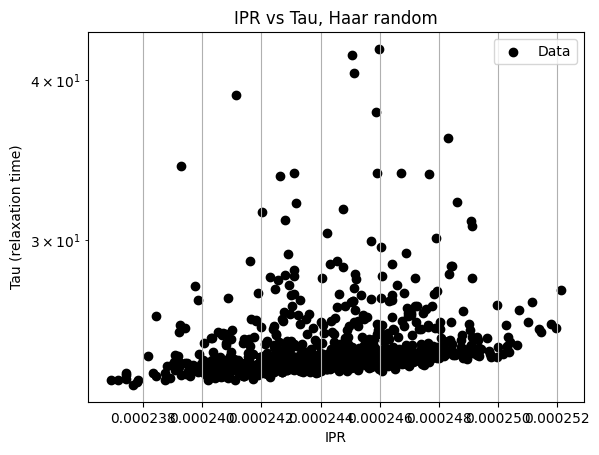

In [233]:
plot_ipr_tau_log(tau_ipr_data,"IPR vs Tau, Haar random")

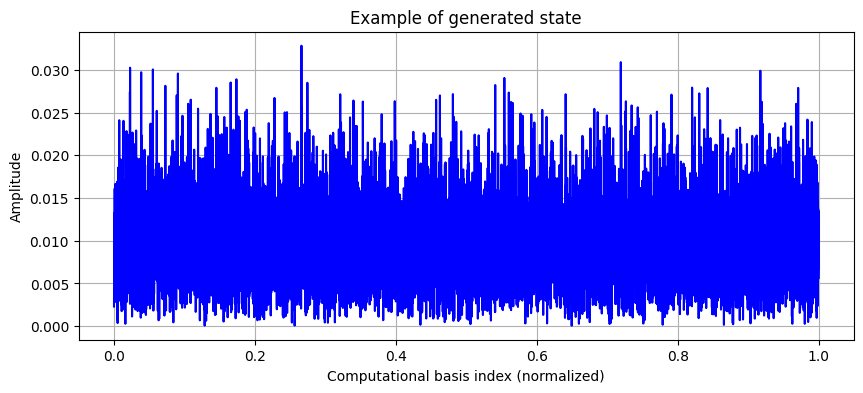

In [232]:
#number of qubits
n=13
# real and imaginary parts
psi_real = np.random.randn(2**n)
psi_imag = np.random.randn(2**n)

# combine into complex vector
psi = psi_real + 1j * psi_imag

# normalize
psi /= np.linalg.norm(psi)
plt.figure(figsize=(10,4))
plt.plot(x, np.abs(psi), color='blue')
plt.title(f'Example of generated state')
plt.xlabel('Computational basis index (normalized)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

### Polynomial

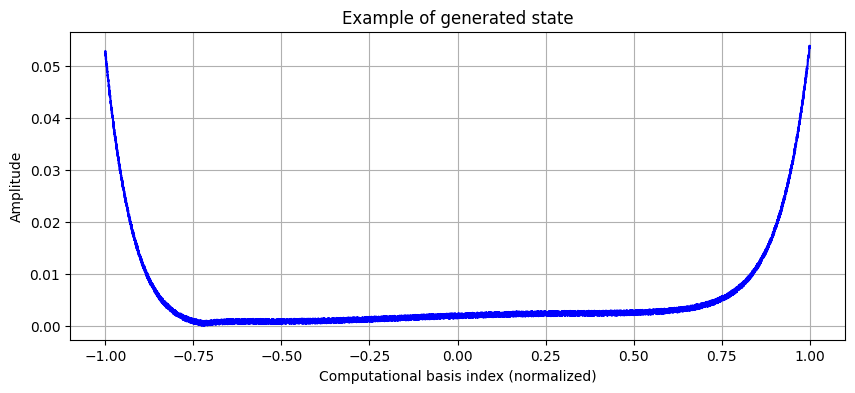

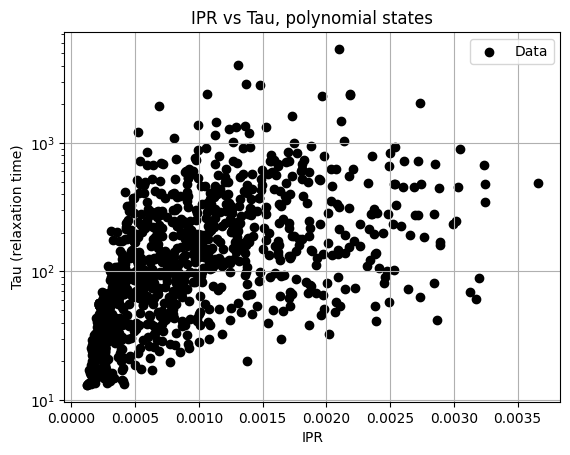

In [241]:
import numpy as np

n = 13
N = 2**n
x = np.linspace(0, 1, N)  # normalized position vector

tau_ipr_data = []
first_psi_plotted=False
import numpy as np

n = 13
N = 2**n
x = np.linspace(-1, 1, N)  # normalized to [-1, 1]

tau_ipr_data = []
num_trials = 1000
max_degree = 15  # allow higher degree

for i in range(num_trials):
    degree = np.random.randint(1, max_degree + 1)
    
    # Scale coefficients so higher-degree terms don't explode
    coeffs = np.random.uniform(-1, 1, size=degree+1) / (np.arange(degree+1) + 1)
    
    # Evaluate polynomial
    amps = np.polyval(coeffs, x)
    
    # Optionally take absolute value to avoid negative amplitudes
    amps = np.abs(amps)
    
    # Normalize
    psi = amps / np.linalg.norm(amps)
    
    # Optionally add tiny noise floor to make tau/IPR more interesting
    psi += 0.001 * np.random.rand(N)
    psi /= np.linalg.norm(psi)
    
    # Append result
    tau_ipr_data.append(tau_ipr_analyse(psi))
    if not first_psi_plotted:
        plt.figure(figsize=(10,4))
        plt.plot(x, np.abs(psi), color='blue')
        plt.title(f'Example of generated state')
        plt.xlabel('Computational basis index (normalized)')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()
        first_psi_plotted = True

plot_ipr_tau_log(tau_ipr_data,"IPR vs Tau, polynomial states")

###Gaussian

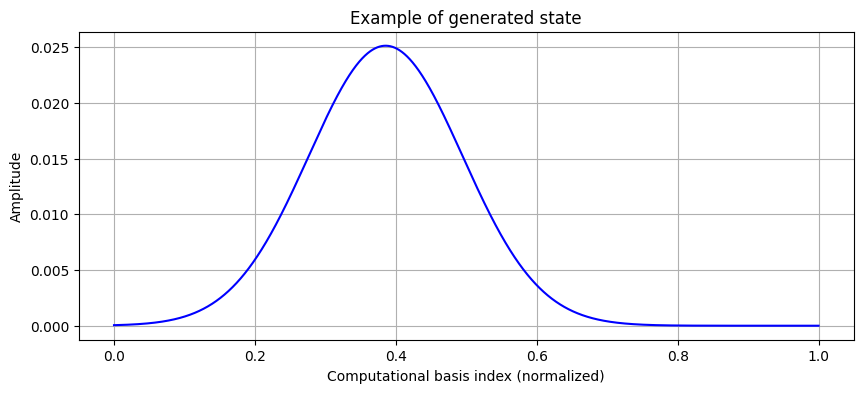

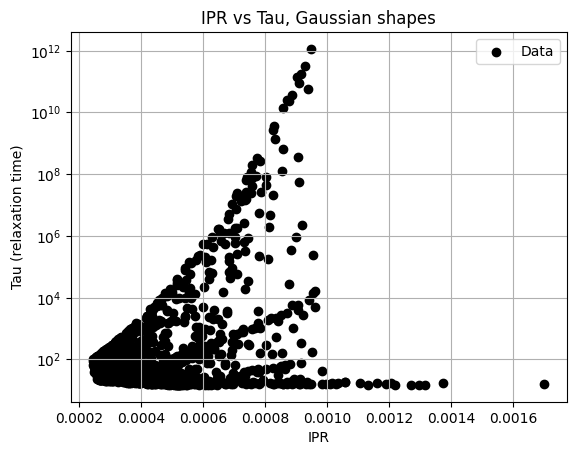

In [216]:
import numpy as np

n = 13
N = 2**n
x = np.linspace(0, 1, N)
tau_ipr_data = []
first_psi_plotted=False
for i in range(1000):
    center = np.random.uniform(0, 1)
    width = np.random.uniform(0.05, 0.2)  # wider than before
    amps = np.exp(-(x - center)**2 / (2 * width**2))
    
    psi = amps / np.linalg.norm(amps)
    tau_ipr_data.append(tau_ipr_analyse(psi))
    if not first_psi_plotted:
        plt.figure(figsize=(10,4))
        plt.plot(x, np.abs(psi), color='blue')
        plt.title(f'Example of generated state')
        plt.xlabel('Computational basis index (normalized)')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()
        first_psi_plotted = True


def plot_ipr_tau_log(data,title):
    """
    Plot IPR vs tau as black dots with a red linear best-fit line.
    
    Parameters
    ----------
    data : list of tuples
        Each tuple is (ipr, tau)
    """
    import matplotlib.pyplot as plt
    import numpy as np

    # unzip and convert to np arrays
    iprs, taus = zip(*data)
    iprs = np.array(iprs)
    taus = np.array(taus)

    # Scatter plot: black dots
    plt.scatter(iprs, taus, color='black', label='Data')

    # Labels and legend
    plt.xlabel('IPR')
    plt.ylabel('Tau (relaxation time)')
    plt.yscale("log")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.show()
    

plot_ipr_tau_log(tau_ipr_data,"IPR vs Tau, Gaussian shapes")

### Random spikes (unclear)

think that this runs into errors cause tau is so large. numerical errors keep messing it so make sure tau is not so large it tweakks out.

(np.float64(0.09483668622079844), np.float64(73786.0211058992))


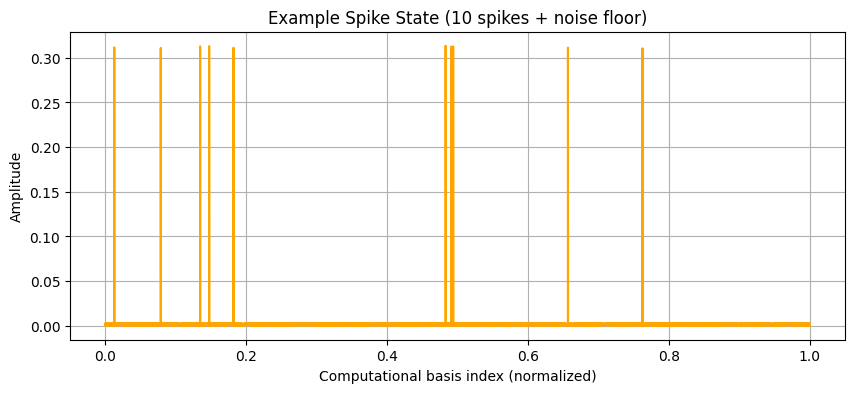

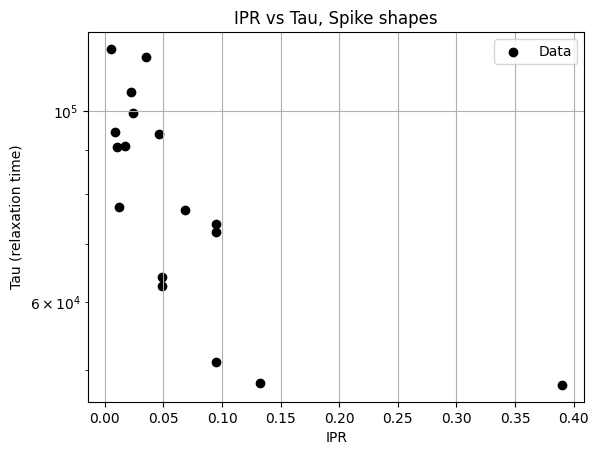

In [228]:
import numpy as np
import matplotlib.pyplot as plt

n = 13
N = 2**n
x = np.linspace(0, 1, N)

tau_ipr_data = [(np.float64(0.06876693594150945), np.float64(76760.83300943009)),
(np.float64(0.04866565303296243), np.float64(62669.50863835978)),
(np.float64(0.03503830111113415), np.float64(115264.00491015406)),
(np.float64(0.024075712470836598), np.float64(99328.03489350414)),
(np.float64(0.01708417186593518), np.float64(90883.40831163184)),
(np.float64(0.011971235982135418), np.float64(77313.7717432228)),
(np.float64(0.008436470819964648), np.float64(94308.65947139263)),
(np.float64(0.09488489304793263), np.float64(72365.94560308076)),
(np.float64(0.09480247061369873), np.float64(51107.90775968395)),
(np.float64(0.04642325554603269), np.float64(94023.61697691953)),
(np.float64(0.022446214295903405), np.float64(105077.69859650939)),
(np.float64(0.010691330002689016), np.float64(90826.76665955971)),
(np.float64(0.00506292620125145), np.float64(117879.14569863946)),
(np.float64(0.3898503156763316), np.float64(48077.007589312656)),
(np.float64(0.13231613872406828), np.float64(48327.69935326787)),
(np.float64(0.04868696416833556), np.float64(64131.35746157704))
]
num_trials = 1  # fewer trials to keep it fast
first_psi_plotted = False

# Log-spaced spike numbers between min and max
min_spikes = 10
max_spikes = N
spike_numbers = np.unique(np.logspace(np.log10(min_spikes), np.log10(max_spikes), num=num_trials, dtype=int))

for num_spikes in spike_numbers:
    amps = np.zeros(N)
    
    # Random spike positions
    spike_positions = np.random.choice(N, size=num_spikes, replace=False)
    amps[spike_positions] = 1.0
    
    # Add a small noise floor
    amps += 0.01 * np.random.rand(N)
    
    # Normalize
    psi = amps / np.linalg.norm(amps)
    
    # Compute IPR and tau
    data=tau_ipr_analyse(psi)
    print(data)
    tau_ipr_data.append(data)
    
    # Plot first example
    if not first_psi_plotted:
        plt.figure(figsize=(10,4))
        plt.plot(x, np.abs(psi), color='orange')
        plt.title(f'Example Spike State ({num_spikes} spikes + noise floor)')
        plt.xlabel('Computational basis index (normalized)')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()
        first_psi_plotted = True
    

plot_ipr_tau_log(tau_ipr_data,"IPR vs Tau, Spike shapes")

okay note that these take much longer to compute than the others for some reason. maybe because tau is large it makes it hard. Ive been adding each trial to the list at the start since it takes so long lol. yeah okay something about this isnt working i wonder if its because they are all high in this high ipr zone so they just have randomly high tau.

### Sinosodal pulses

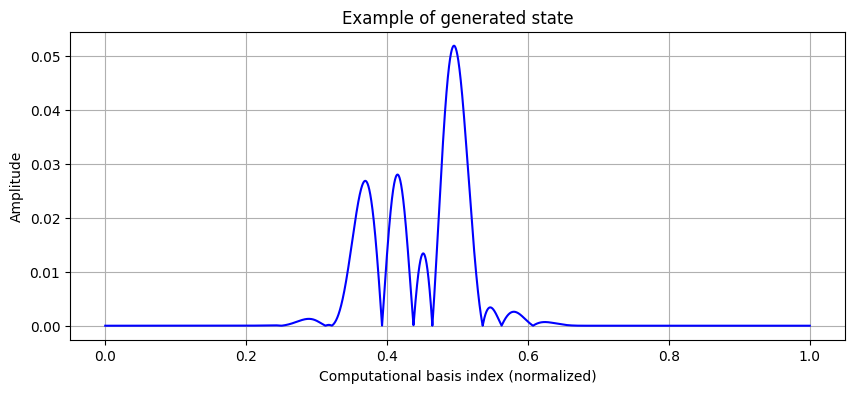

[(np.float64(0.0014920873136535665), np.float64(2357298960.697023)), (np.float64(0.0015019415642890809), np.float64(41668.749255552466)), (np.float64(0.0013977830543121673), np.float64(799988.9078303814)), (np.float64(0.0007967826442364264), np.float64(9419.121762740924)), (np.float64(0.0017667713942322687), np.float64(5185867.4742757715)), (np.float64(0.000873938711034471), np.float64(695.5784988123943)), (np.float64(0.0006418753357251474), np.float64(1012.504310316308)), (np.float64(0.001008218457580282), np.float64(949.9822356462022)), (np.float64(0.0006640939649082186), np.float64(16236.844466456005)), (np.float64(0.0009902876925256467), np.float64(1476.6653539747138))]


In [ ]:
n = 13
N = 2**n
x = np.linspace(0, 1, N)
tau_ipr_data = []

num_trials = 10

# To visualize the first generated state
first_psi_plotted = False

for i in range(num_trials):
    # Gaussian envelope
    center = np.random.uniform(0.3, 0.7)
    width = np.random.uniform(0.05, 0.15)
    envelope = np.exp(-(x - center)**2 / (2 * width**2))
        
    # Two cosine frequencies
    f1 = np.random.randint(3, 6)
    f2 = np.random.randint(7, 12)
    cos_component = np.cos(2*np.pi*f1*x) + np.cos(2*np.pi*f2*x)
    amps = envelope * cos_component
    amps = np.abs(amps)  # ensure non-negative
    
    # normalize
    psi = amps / np.linalg.norm(amps)
    
    # store IPR and tau
    tau_ipr_data.append(tau_ipr_analyse(psi))
    
    # Plot the first state amplitudes to see structure
    if not first_psi_plotted:
        plt.figure(figsize=(10,4))
        plt.plot(x, np.real(psi), color='blue')
        plt.title(f'Example of generated state')
        plt.xlabel('Computational basis index (normalized)')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()
        first_psi_plotted = True
print(tau_ipr_data)

### Josh's States (not working)

want to try this on some other states so Josh recomended these. 

In [254]:
import numpy as np
import quimb as qu
import quimb.tensor as qtn


def generate_target_state_josh(
    N,
    sigma_theta,
    seed=None,
    return_circuit=False,
):
    """
    Generate |psi> = U |0^N> in Quimb where

    U = (⊗ Ry(theta_i^(1)))
        (∏ exp(i phi_i Z_i Z_{i+1}))
        (⊗ Ry(theta_i^(2)))

    Parameters
    ----------
    N : int
        Number of qubits
    sigma_theta : float
        Std dev of Gaussian for Ry angles
    seed : int or None
        RNG seed
    return_circuit : bool
        If True, return the Circuit object as well

    Returns
    -------
    psi : qtn.TensorNetwork
        Final quantum state
    circ : qtn.Circuit (optional)
        Circuit preparing the state
    """

    rng = np.random.default_rng(seed)

    theta_1 = rng.normal(0.0, sigma_theta, size=N)
    theta_2 = rng.normal(0.0, sigma_theta, size=N)
    phi = rng.uniform(0.0, 2 * np.pi, size=N - 1)

    circ = qtn.Circuit(N)

    # First layer: ⊗ Ry(theta_i^(1))
    for i in range(N):
        circ.apply_gate('RY', theta_1[i], i)

    # ZZ entangling layer: exp(i phi_i Z_i Z_{i+1})
    for i in range(N - 1):
        circ.apply_gate('RZZ', 2 * phi[i], i, i + 1)

    # Second layer: ⊗ Ry(theta_i^(2))
    for i in range(N):
        circ.apply_gate('RY', theta_2[i], i)

    # Apply to |0^N>
    psi = circ.psi

    if return_circuit:
        return psi, circ

    return psi
psi,circ=generate_target_state_josh(2**4,0.1,return_circuit=True)


In [255]:
tau_ipr_analyse(psi.to_dense())

(np.float64(0.8816584897821543), np.float64(16.07996531299735))

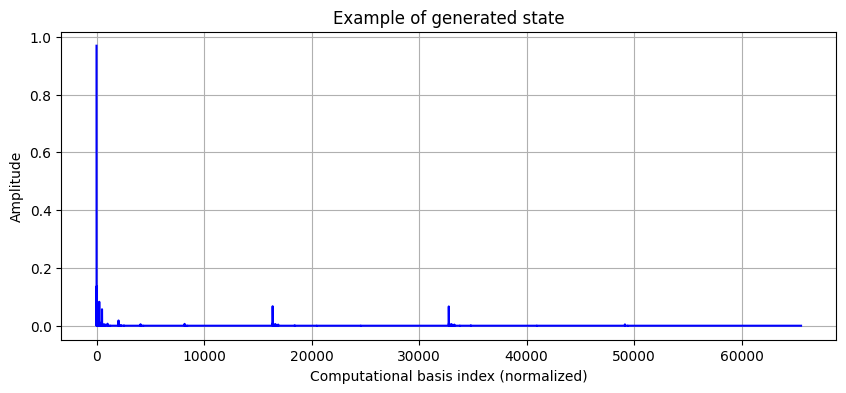

In [256]:
plt.figure(figsize=(10,4))
plt.plot(np.abs(circ.psi.to_dense().flatten()), color='blue')
plt.title(f'Example of generated state')
plt.xlabel('Computational basis index (normalized)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

In [261]:
n = 6
N = 2**n
tau_ipr_data = []

num_trials = 1

# To visualize the first generated state
first_psi_plotted = False

for i in range(num_trials):
    psi=generate_target_state_josh(N,0.1)
    psi=psi.to_dense()
    # normalize
    psi = psi / np.linalg.norm(psi)
    
    # store IPR and tau
    tau_ipr_data.append(tau_ipr_analyse(psi))
    
    # Plot the first state amplitudes to see structure
    if not first_psi_plotted:
        plt.figure(figsize=(10,4))
        plt.plot(np.abs(psi), color='blue')
        plt.title(f'Example of generated state')
        plt.xlabel('Computational basis index (normalized)')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()
        first_psi_plotted = True
plot_ipr_tau_log(tau_ipr_data,"IPR vs Tau, Josh's states Pulses")

KeyboardInterrupt: 

hm this is not really working maybe some more thought needs to go into how we choose this the computation takes so long maybe baciase of the tau.

# Full before and after tau and IPR graph

In [10]:
#Running numerical trials, keep in mind this will exit if it gets stuck on a state its dogdy i know this jsut needs some love and attention and it will be fine, let it break and keep restarting
#I think the timeout doesnt work well cause im trying to use a bunch of quimb stuff
import numpy as np
import os
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, TimeoutError

before_file = "tau_ipr_before.npy"
after_file = "tau_ipr_after.npy"
num_trials = 100
timeout_sec = 20  # max seconds per trial

# -----------------------------
# Load existing saved data
# -----------------------------
if os.path.exists(before_file):
    tau_ipr_data_before = list(np.load(before_file, allow_pickle=True))
else:
    tau_ipr_data_before = []

if os.path.exists(after_file):
    tau_ipr_data_after = list(np.load(after_file, allow_pickle=True))
else:
    tau_ipr_data_after = []

# -----------------------------
# Simulation parameters
# -----------------------------
n = 16
N = 2**n
x = np.linspace(0, 1, N)
first_psi_plotted = False

# -----------------------------
# Define single trial function
# -----------------------------
def run_single_trial(_):
    # Gaussian envelope
    center = np.random.uniform(0.3, 0.7)
    width = np.random.uniform(0.02, 0.05)
    envelope = np.exp(-(x - center)**2 / (2 * width**2))
    
    # Two cosine frequencies
    f1 = np.random.randint(3, 6)
    f2 = np.random.randint(7, 12)
    cos_component = np.cos(2*np.pi*f1*x) + np.cos(2*np.pi*f2*x)
    amps = envelope * cos_component
    amps = np.abs(amps)
    
    # normalize
    psi = amps / np.linalg.norm(amps)
    
    ipr, tau = tau_ipr_analyse(psi)
    
    if 10**10 < tau < 10**16:
        psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
        qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
        best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=False)
        qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=False)
        ipr_after, tau_after = tau_ipr_analyse(qc_from_psi0_taued.psi.to_dense())
        return (ipr, tau), (ipr_after, tau_after), psi
    else:
        return None

# -----------------------------
# Run trials with thread-based timeout
# -----------------------------
new_tau_ipr_data_before = []
new_tau_ipr_data_after = []

with ThreadPoolExecutor(max_workers=1) as executor:
    for i in range(num_trials):
        future = executor.submit(run_single_trial, i)
        try:
            result = future.result(timeout=timeout_sec)
            if result is not None:
                tau_before, tau_after, psi = result
                new_tau_ipr_data_before.append(tau_before)
                new_tau_ipr_data_after.append(tau_after)
                print(f"Trial {i}: tau before vs after = {tau_before[1]:.3e}, {tau_after[1]:.3e}")
                
                if not first_psi_plotted:
                    """plt.figure(figsize=(10,4))
                    plt.plot(x, np.real(psi), color='blue')
                    plt.title('Example of generated state')
                    plt.xlabel('Computational basis index (normalized)')
                    plt.ylabel('Amplitude')
                    plt.grid(True)
                    plt.show()"""
                    first_psi_plotted = True
        except TimeoutError:
            
            print(f"Trial {i} timed out after {timeout_sec} seconds, skipping...")
            break
# -----------------------------
# Append new results to old data
# -----------------------------
tau_ipr_data_before.extend(new_tau_ipr_data_before)
tau_ipr_data_after.extend(new_tau_ipr_data_after)

# -----------------------------
# Save everything back to disk
# -----------------------------
np.save(before_file, np.array(tau_ipr_data_before))
np.save(after_file, np.array(tau_ipr_data_after))

print("Saved", len(new_tau_ipr_data_before), "new BEFORE points")
print("Saved", len(new_tau_ipr_data_after), "new AFTER points")

Trial 1 timed out after 20 seconds, skipping...
Saved 0 new BEFORE points
Saved 0 new AFTER points


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.war

Tau after flattening layer is: 20.85310446231922
tau before vs after is: 209469750110255.62 20.853104462319557


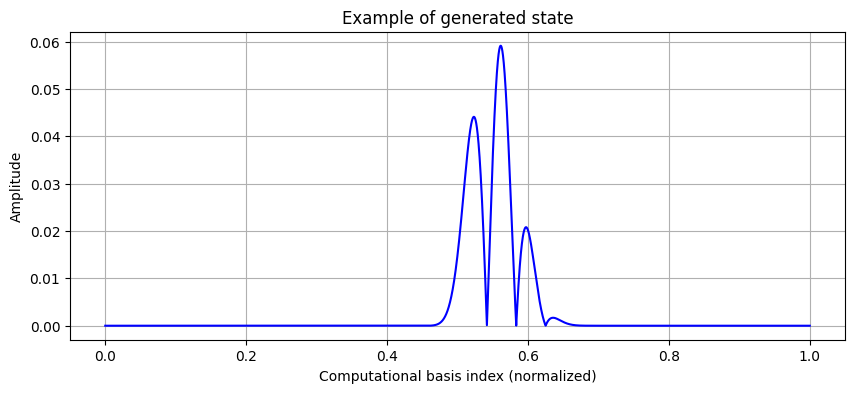

+0.000143136877 [best: +0.000141053575] :   1%|▏         | 112/8000 [00:02<03:22, 39.03it/s]


Tau after flattening layer is: 18.75980354944509
tau before vs after is: 54260236474343.33 18.75980354944388


+0.000133245834 [best: +0.000131175084] :   1%|▏         | 104/8000 [00:02<02:55, 44.90it/s]


Tau after flattening layer is: 15.82285006425439
tau before vs after is: 10855853383.223507 15.822850064254695


In [ ]:
#OLD VERSION THAT SOMETIMES GETS STUCK ON DATA POINTS
import numpy as np
import os

before_file = "tau_ipr_before.npy"
after_file = "tau_ipr_after.npy"
num_trials = 10


# -----------------------------
# Load existing saved data
# -----------------------------
if os.path.exists(before_file):
    tau_ipr_data_before = list(np.load(before_file, allow_pickle=True))
else:
    tau_ipr_data_before = []

if os.path.exists(after_file):
    tau_ipr_data_after = list(np.load(after_file, allow_pickle=True))
else:
    tau_ipr_data_after = []

# -----------------------------
# NEW DATA FROM THIS RUN
# -----------------------------
new_tau_ipr_data_before = []
new_tau_ipr_data_after = []

# >>> YOUR NUMERICAL SIMULATION GOES HERE <<<
n = 16
N = 2**n
x = np.linspace(0, 1, N)



# To visualize the first generated state
first_psi_plotted = False

for i in range(num_trials):
    # Gaussian envelope
    center = np.random.uniform(0.3, 0.7)
    width = np.random.uniform(0.02, 0.05)
    envelope = np.exp(-(x - center)**2 / (2 * width**2))
        
    # Two cosine frequencies
    f1 = np.random.randint(3, 6)
    f2 = np.random.randint(7, 12)
    cos_component = np.cos(2*np.pi*f1*x) + np.cos(2*np.pi*f2*x)
    amps = envelope * cos_component
    amps = np.abs(amps)  # ensure non-negative
    
    # normalize
    psi = amps / np.linalg.norm(amps)
    
    # store IPR and tau
    ipr,tau=tau_ipr_analyse(psi)

    #If there is tau greater than 10^10 then we will do stuff to it
    if 10**10<tau <10**16:
        new_tau_ipr_data_before.append((ipr,tau))

        #Tau reduce the given state
        psi0_tn = qtn.MatrixProductState.from_dense(psi)/qtn.MatrixProductState.from_dense(psi).norm()
        qc_from_psi0 = qtn.Circuit(n, psi0=psi0_tn)
        best_tau_layer = ipr_layer_optimise(init_mps=psi0_tn, verbose=False)
        qc_from_psi0_taued = tau_tn_to_circ(best_tau_layer, qc_from_psi0, n, verbose=False)
        ipr_after,tau_after=tau_ipr_analyse(qc_from_psi0_taued.psi.to_dense())

        new_tau_ipr_data_after.append((ipr_after,tau_after))
        print("tau before vs after is:",tau,tau_after)
    
    # Plot the first state amplitudes to see structure
    if not first_psi_plotted:
        plt.figure(figsize=(10,4))
        plt.plot(x, np.real(psi), color='blue')
        plt.title(f'Example of generated state')
        plt.xlabel('Computational basis index (normalized)')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.show()
        first_psi_plotted = True

# -----------------------------
# Append new results to old data
# -----------------------------
tau_ipr_data_before.extend(new_tau_ipr_data_before)
tau_ipr_data_after.extend(new_tau_ipr_data_after)

# -----------------------------
# Save everything back to disk
# -----------------------------
np.save(before_file, np.array(tau_ipr_data_before))
np.save(after_file, np.array(tau_ipr_data_after))

print("Saved", len(new_tau_ipr_data_before), "new BEFORE points")
print("Saved", len(new_tau_ipr_data_after), "new AFTER points")

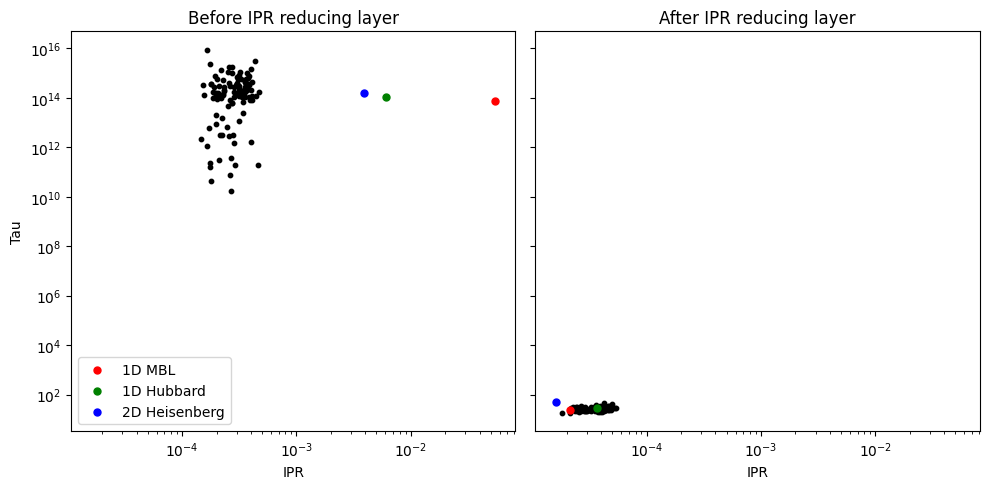

Graphing 108 data points.


In [9]:
import matplotlib.pyplot as plt
# Load your saved data — allow_pickle is required for object arrays
before = np.load("tau_ipr_before.npy", allow_pickle=True)
after = np.load("tau_ipr_after.npy", allow_pickle=True)


x_before, y_before = zip(*before)
x_after, y_after = zip(*after)

fig, axs = plt.subplots(1, 2, figsize=(10,5), sharex=True, sharey=True)
# Example special points (one tuple per point)
special_before = [(0.054828946663797916, 76332197074076.2), (0.006097805088167593, 104734875055127.81), (0.0039065057252740225,150119987579016.53)]
special_after  = [(2.149239702229474e-05, 24.522403642512902), (3.667778188711198e-05, 29.227345769612157), (1.597801409916765e-05,51.95367087626606)]

# Colors for each special point
colors_before = ['red', 'green', 'blue']
colors_after  = ['red', 'green', 'blue']
labels=["1D MBL","1D Hubbard","2D Heisenberg"]


# Left plot
axs[0].scatter(x_before, y_before, s=10,color="black")
axs[0].set_title("Before IPR reducing layer")

# Right plot
axs[1].scatter(x_after, y_after, s=10,color="black")
axs[1].set_title("After IPR reducing layer")
# Plot each special point individually with its own color
for (x, y), c,label in zip(special_before, colors_before,labels):
    axs[0].scatter(x, y, s=25, color=c, marker='o', label=label)

for (x, y), c in zip(special_after, colors_after):
    axs[1].scatter(x, y, s=25, color=c, marker='o', label=label)
axs[0].set_xlabel("IPR")
axs[1].set_xlabel("IPR")
axs[0].set_ylabel("Tau")
axs[0].set_yscale("log")
axs[0].set_xscale("log")
axs[0].legend()

plt.tight_layout()
plt.show()
print("Graphing",len(before),"data points.")

# IPR Optimising (subspace fidelity rather than fidelity)

In [13]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def compute_tau_sparse_multi(state_vector, n_eigs=5, verbose=False):
    """
    Compute τ (relaxation times) for the single-qubit-flip Markov chain
    using a sparse representation for efficiency.

    Parameters
    ----------
    state_vector : np.array of shape (2**n,)
        Full state vector of |ψ⟩
    n_eigs : int
        Number of leading eigenvalues to compute (including the largest)
    verbose : bool
        If True, prints intermediate details

    Returns
    -------
    tau_list : list of float
        Relaxation times τ_k = 1 / (1 - λ_k) for k=2,...,n_eigs
    lambda_list : list of float
        Corresponding eigenvalues λ_1, λ_2, ..., λ_n_eigs
    P_reduced : scipy.sparse.csr_matrix
        Sparse transition matrix with zero-amplitude rows removed
    """

    state_vector = np.array(state_vector, dtype=complex).flatten()
    norm = np.linalg.norm(state_vector)
    if norm == 0:
        raise ValueError("State vector cannot be zero")
    state_vector /= norm

    n_qubits = int(np.log2(len(state_vector)))
    dim = 2**n_qubits
    pi = np.abs(state_vector)**2
    N = n_qubits

    rows, cols, data = [], [], []

    for x in range(dim):
        row_sum = 0.0
        for bit in range(n_qubits):
            y = x ^ (1 << bit)
            denom = pi[x] + pi[y]
            if denom > 0:
                Pxy = (1 / N) * pi[y] / denom
                rows.append(x)
                cols.append(y)
                data.append(Pxy)
                row_sum += Pxy
        # Diagonal entry
        rows.append(x)
        cols.append(x)
        data.append(1.0 - row_sum)
        if verbose and x < 3:
            print(f"Row {x} sum ~ {row_sum + (1-row_sum):.6f}")

    P = sp.csr_matrix((data, (rows, cols)), shape=(dim, dim))

    # Remove zero-amplitude rows (and columns)
    zero_rows = np.where(pi == 0)[0]
    if len(zero_rows) > 0:
        mask = np.ones(dim, dtype=bool)
        mask[zero_rows] = False
        P_reduced = P[mask, :][:, mask]
    else:
        P_reduced = P

    if verbose:
        print(f"Sparse P shape: {P_reduced.shape}, nnz = {P_reduced.nnz}")

    # Compute the n_eigs largest eigenvalues (in magnitude)
    vals, _ = spla.eigs(P_reduced.T, k=n_eigs, which='LM')
    vals = np.real(vals)
    vals.sort()
    vals = vals[::-1]  # descending order
    lambda_list = vals.tolist()

    # Compute tau_k = 1 / (1 - λ_k) relative to λ1
    tau_list = [1.0 / (lambda_list[0] - lam) if lambda_list[0] != lam else np.inf
                for lam in lambda_list[1:]]

    if verbose:
        for i, lam in enumerate(lambda_list):
            print(f"λ_{i+1} = {lam:.6f}")
        for i, tau in enumerate(tau_list, start=2):
            print(f"τ_{i} = {tau:.6f}")

    return tau_list

In [19]:
def tau_tn_to_circ_multi(best_tau_layer,circuit,num_qubits,n_eigs=5,verbose:bool= False,calc_first_tau:bool=True):
    '''Appends the best tau layer onto the end of the circuit and will print the new tau value, FOR MULTIPLE LEVELS OF TAU'''
    if verbose:
        print("Lowest Possible IPR:",2**(-n))
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State before flattening layer")
        plt.show()
        if calc_first_tau==False:
            print("not computing tau before")
        else:
            tau_list=compute_tau_sparse_multi(circuit.psi.to_dense(),n_eigs=n_eigs ,verbose=False)
            print("Taus before flattening layer are:",tau_list)
            if verbose:
                tau_indices = list(range(2, 2 + len(tau_list)))  # τ2, τ3, τ4, ...
                plt.figure(figsize=(6,4))
                plt.plot(tau_indices, tau_list, 'o-', color='blue', markersize=6, linewidth=2)
                plt.xticks(tau_indices)
                plt.xlabel("Eigenvalue index k (τ_k)")
                plt.ylabel("Relaxation time τ_k")
                plt.title("Taus before")
                plt.grid(True)
                plt.show()
    for idx in range(num_qubits):
        circuit.apply_gate_raw(best_tau_layer.tensors[idx].data,[idx])
    if verbose:
        plt.plot(circuit.psi.to_dense())
        plt.xlabel("Index")
        plt.ylabel("Amplitude")
        plt.title("State after flattening layer")
        plt.show()
    tau_list=compute_tau_sparse_multi(circuit.psi.to_dense(),n_eigs=n_eigs ,verbose=False)
    print("Taus after flattening layer are:",tau_list)
    if verbose:
        tau_indices = list(range(2, 2 + len(tau_list)))  # τ2, τ3, τ4, ...
        plt.figure(figsize=(6,4))
        plt.plot(tau_indices, tau_list, 'o-', color='blue', markersize=6, linewidth=2)
        plt.xticks(tau_indices)
        plt.xlabel("Eigenvalue index k (τ_k)")
        plt.ylabel("Relaxation time τ_k")
        plt.title("Taus after")
        plt.grid(True)
        plt.show()

    return circuit

In [20]:
tau_list=compute_tau_sparse_multi(real_accoustic_circuit.psi.to_dense(),n_eigs=15 ,verbose=False)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Initial IPR loss = 0.0017246392896100035
Starting optimisation...


  0%|          | 0/8000 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000137903019 [best: +0.000133477371] :   1%|▏         | 117/8000 [00:02<03:14, 40.50it/s]
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Final IPR loss = 0.00013347737131017286
Best IPR loss recorded = 0.00013347737131017286
After updating, final IPR loss = 0.00013347737131017286
Lowest Possible IPR: 0.0001220703125


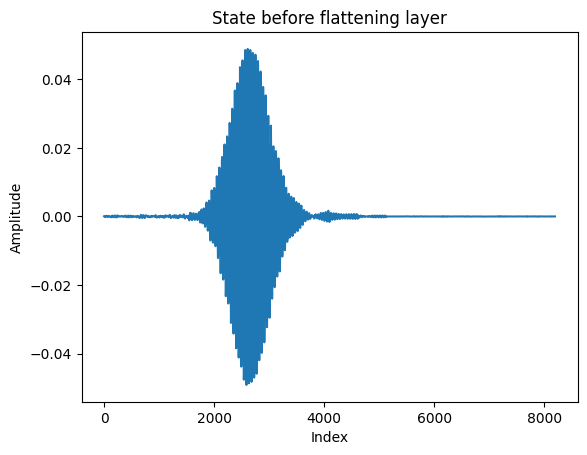

Taus before flattening layer are: [447.2881300215806, 173.58424196063987, 43.65612804919993, 41.98546669202255, 38.131416088178234, 32.46571996253138, 31.790001720770345, 26.031423492043764, 25.888370090282038, 25.370711528629943, 24.235608215248, 23.379737331659612, 23.205616422876837, 22.952311678858255]


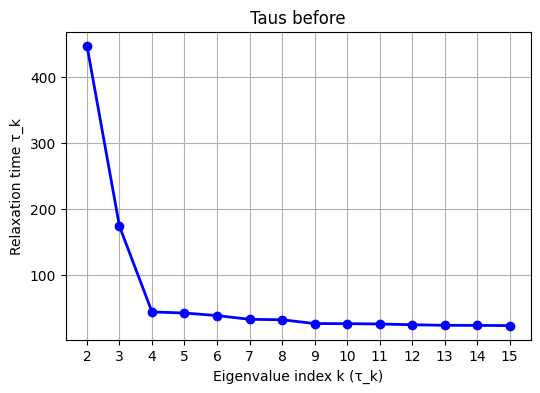

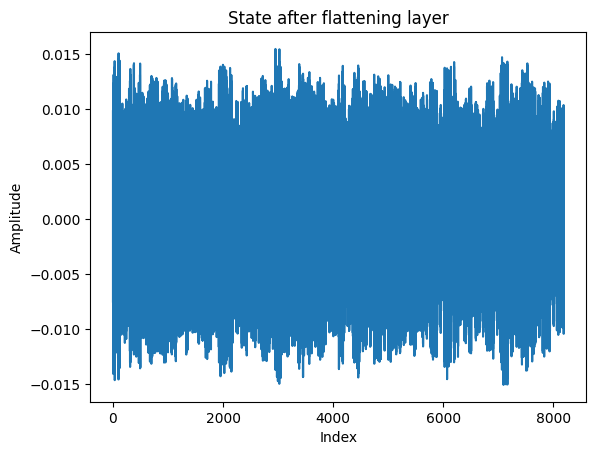

Taus after flattening layer are: [17.151844360774245, 14.054081916538314, 13.83234292533718, 13.570351650434839, 13.478699526967322, 13.431253014654141, 13.204730874456418, 13.143366878595344, 13.039877527999437, 13.01764219970272, 13.009570096319273, 12.968787514284047, 11.112742991404959, 7.873993766848085]


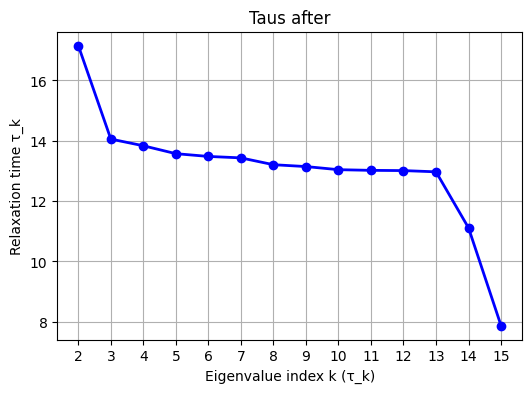

In [21]:
real_accoustic_circuit=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
audiostate = qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense())/qtn.MatrixProductState.from_dense(real_accoustic_circuit.psi.to_dense()).norm()
# Now replace with direct inital state cicuit construction
n = 13
psi0_tn = audiostate

# Initialize circuit with this state
qc_from_pis0 = qtn.Circuit(n, psi0=psi0_tn)

best_tau_layer=ipr_layer_optimise(init_mps=psi0_tn,verbose=True)
real_accoustic_circuit_taued=tau_tn_to_circ_multi(best_tau_layer,qc_from_pis0,13,n_eigs=15,verbose=True)